# Solución optimizada CUDA Python — ASL

David Domínguez · 23712 / Jonathan Diaz · 23873 / Luis Padilla · 23663

**Ejecución nueva directa en este notebook:** `EXP-009` / `RUN-20261118T041129Z-cuda-notebook-01`.
Cada salida corresponde al código de la celda ejecutada. No se simula `fit` ni se
sustituye por leer un historial. La corrida es adicional a las cinco mediciones
del informe: sus promedios permanecen intactos. Al final se incluyen los registros
históricos completos identificados como tales.

Kernel: **PCUDA**. Preparación de archivos/imágenes en CPU.
Matemática del entrenamiento en GPU; validación y prueba en CPU.
Datos congelados:17,400 imágenes,RGB64×64,float32/255;train12180,val2610,test2610.
Se ejecutan15épocas completas por red,batch128,último20,sin EarlyStopping.

Las celdas operativas se extrajeron del AST del controlador medido y se separaron
por fase. Esta ejecución verifica su recorrido en notebook. Para repetir se debe
preparar otro EXP/RUN; este destino no se sobrescribe después de cerrarlo.


In [1]:
from pathlib import Path
import ast, csv, hashlib, json, os, random, subprocess, sys, time
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/Proyecto 3 CUDA.pdf").is_file())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]
EXPERIMENT = ROOT / "resultados/paralelo/EXP-009"
CONFIG = ROOT / "configuraciones/EXP-009.json"
NOTEBOOK = ROOT / "LAB3-DATASCIENCE/Lab3_ASL_Deep_Learning.ipynb"
directory = EXPERIMENT / "RUN-20261118T041129Z-cuda-notebook-01"
repetition = 1
experiment = "EXP-009"
SEED, IMG_SIZE, NUM_CLASSES = 42, 64, 29
__file__ = str(ROOT / "scripts/benchmark_cuda.py")
assert not (directory / "salida.json").exists(), "Corrida cerrada: preparar otro EXP/RUN"
from IPython.display import display, Image as NotebookImage, Markdown
from PIL import Image
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
print("Ejecución real:", experiment, directory.name)
print("Intérprete:", sys.executable)


Ejecución real: EXP-009 RUN-20261118T041129Z-cuda-notebook-01
Intérprete: C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Scripts\python.exe


In [2]:
from __future__ import annotations
import argparse
from collections import deque
from concurrent.futures import ThreadPoolExecutor
import csv
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import subprocess
import sys
import time
import traceback
from benchmark_cpu import FIELDS, sha, write_csv, write_json, utc

## 1. Configuración, registro y funciones de medición

Las funciones siguientes registran tiempos y estado real; no entrenan al definirse.

In [3]:
FIELDS = 'experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo'.split(',')

def utc():
    return datetime.now(timezone.utc).isoformat()

def sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

def write_csv(path, rows, fields=None):
    with Path(path).open('w', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields or list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def original_namespace():
    """Compile only named definitions, preserving their original source bodies."""
    import numpy as np
    import pandas as pd
    from PIL import Image
    namespace = dict(np=np, pd=pd, Image=Image, random=random, SEED=42, IMG_SIZE=64)
    notebook = json.loads(NOTEBOOK.read_text(encoding='utf-8'))
    names = {'build_sampled_file_list', 'load_images', 'build_cnn_a', 'build_cnn_b', 'build_fc'}
    for index, cell in enumerate(notebook['cells']):
        if cell['cell_type'] != 'code':
            continue
        tree = ast.parse(''.join(cell['source']))
        for node in tree.body:
            if isinstance(node, ast.FunctionDef) and node.name in names:
                exec(compile(ast.Module(body=[node], type_ignores=[]), f'original/celda-{index}', 'exec'), namespace)
    namespace['_notebook'] = notebook
    return namespace

class Recorder:

    def __init__(self, directory, config, repetition):
        self.directory, self.config, self.repetition = (directory, config, repetition)
        self.rows = []
        self.epochs = []

    def state(self, phase, **more):
        write_json(self.directory / 'estado.json', dict(utc=utc(), fase=phase, **more))
        print(f'[{utc()}] {phase} {more}', flush=True)

    def measure(self, phase, function, **load):
        self.state(phase)
        start_utc, start = (utc(), time.perf_counter_ns())
        value = function()
        end, end_utc = (time.perf_counter_ns(), utc())
        self.add(phase, (end - start) / 1000000000.0, start_utc, end_utc, **load)
        return value

    def add(self, phase, seconds, start, end, **load):
        row = dict.fromkeys(FIELDS, '')
        row.update(experimento_id=self.config['experimento_id'], run_id=self.directory.name, dispositivo='cpu', repeticion=self.repetition, fase=phase, tipo_medicion='pared', duracion_s=seconds, inicio_utc=start, fin_utc=end, incluido_resumen='true', estado='completada', configuracion_sha256=sha(CONFIG), datos_sha256=self.config['datos']['manifest_splits_sha256'], evidencia=(self.directory / 'tiempos.csv').relative_to(ROOT).as_posix())
        row.update(load)
        self.rows.append(row)
        write_csv(self.directory / 'tiempos.csv', self.rows, FIELDS)
        print(f'RESULTADO {phase}: {seconds:.6f} s', flush=True)

In [4]:
config = json.loads(CONFIG.read_text(encoding="utf8"))
print(json.dumps(config, indent=2, ensure_ascii=False))
from registro_notebook import iniciar_monitor
monitor_stop, monitor_thread = iniciar_monitor(directory)


{
  "es_plantilla": false,
  "experimento_id": "EXP-009",
  "creado_utc": "2026-11-18T04:11:29.552584+00:00",
  "pregunta": "Tiempo real CNN-B CUDA Python, FP32, mismos datos/pasos que fase CPU EXP-002",
  "responsable": "Codex por solicitud del usuario; revision docente de codigo y salidas nativas",
  "requisitos": [
    "REQ-06",
    "REQ-07",
    "REQ-09",
    "REQ-12"
  ],
  "decisiones": [
    "DEC-021",
    "DEC-022",
    "DEC-023"
  ],
  "codigo": {
    "fuentes": {
      "scripts/benchmark_cuda.py": "816574529011075f5e8ad7c53d925bf882e11c10e420abe2e9688f6c97ba1c5a",
      "scripts/capturar_contexto.py": "9164ea30a915f5ee2a3852ccbe55d608accaa5aa65ffbb0d1d175233bf518e46",
      "src/asl_cuda/__init__.py": "905eaf476ad18cd47ebcb0b4fc5d8e6f89e92c8de7a07e1c1e68d18a9f52284c",
      "src/asl_cuda/blas.py": "1ba799e3cb2d8856e3b7bd408ca2d8f6cd6cb840a0e326916c40f3bc021024b8",
      "src/asl_cuda/kernels.py": "3dc55a51bc4e2ece39c279ecf9d60956c06d4700a03603c44dda23f6dd100fec",
      "src/a

## 2. Datos y funciones originales utilizadas

Código original conservado: carga de imágenes y arquitectura. Las tablas muestran todos los conteos de clases y particiones.

In [5]:
def build_cnn_b():

    def bn():
        return layers.BatchNormalization(momentum=0.9)
    model = keras.Sequential([layers.Input((IMG_SIZE, IMG_SIZE, 3)), layers.Conv2D(32, 3, padding='same', activation='relu'), bn(), layers.Conv2D(32, 3, padding='same', activation='relu'), layers.MaxPooling2D(), layers.Dropout(0.25), layers.Conv2D(64, 3, padding='same', activation='relu'), bn(), layers.Conv2D(64, 3, padding='same', activation='relu'), layers.MaxPooling2D(), layers.Dropout(0.25), layers.Conv2D(128, 3, padding='same', activation='relu'), bn(), layers.MaxPooling2D(), layers.Dropout(0.3), layers.Flatten(), layers.Dense(256, activation='relu'), bn(), layers.Dropout(0.4), layers.Dense(NUM_CLASSES, activation='softmax')], name='CNN_B_regularizada')
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [6]:
datos_manifest = pd.read_csv(ROOT / "resultados/secuencial/EXP-002/manifest_splits.csv", keep_default_na=False)
display(pd.crosstab(datos_manifest.clase, datos_manifest.split, margins=True))
display(datos_manifest.head(12))
print("17,400 rutas/identidades completas en el manifiesto congelado; no se vuelve a muestrear.")


split,test,train,val,All
clase,,,,
A,90,420,90,600
B,90,420,90,600
C,90,420,90,600
D,90,420,90,600
E,90,420,90,600
F,90,420,90,600
G,90,420,90,600
H,90,420,90,600
I,90,420,90,600


,dataset_id,ruta_relativa,sha256,clase,label_idx,split,orden
0,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/G/G655.jpg,c0bd22cd6c98e4c44f55768591883b3f09de1ea56a4d5086e1588f9c6bba1408,G,6,train,0
1,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/U/U872.jpg,99f8225febb986777b61f51b64a28dbe383ed4207961f574b12fc05ab16dcfd9,U,20,train,1
2,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/del/del1194.jpg,f1c0ce06721a2800426c606c91cf5ef7e1a8eda6b64e6a1d7fce5fd5241674fd,del,26,train,2
3,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/X/X1315.jpg,8aa9f39fb29eb8d6a3b3d08b8b2798ec2a87ae9d0acdefd00b7b4ab04c1b777f,X,23,train,3
4,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/L/L1488.jpg,de633263269d5853ae4e0fb29cde3d8b7117757b87c7c00dfc80e0b3ad211824,L,11,train,4
5,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/Q/Q2458.jpg,f91ac91df6363041db78bed1b5f6965394ccd957d6ee7a26889f4fe1551726c3,Q,16,train,5
6,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/R/R1802.jpg,a0ed4e004c4ecd3aae62a9bfca0f17322cf9a0fd1582dd5fc10d378a469df3a2,R,17,train,6
7,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/F/F639.jpg,db1e01d002a4453522ed1da46a5c7d52dd17ab290943f908bd6e520d4f94c7ce,F,5,train,7
8,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/V/V2125.jpg,51bb2043c46f2e3cab613a68a5b582ff7191610a6b405ba5dd8f16b0f889cb65,V,21,train,8
9,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/P/P1458.jpg,b16b54cab32dbec8c12826f245e32f66a02fd5d1bed59affb41ba895232642f7,P,15,train,9


17,400 rutas/identidades completas en el manifiesto congelado; no se vuelve a muestrear.


## 3. CUDA Python: configuración y código completo de los módulos

Cada celda `%%modulo` ejecuta la fuente Python mostrada en un módulo de memoria. No escribe ni altera los archivos del proyecto. Los kernels y la red usados abajo son estos mismos módulos.

In [7]:
import types
from IPython.core.magic import register_cell_magic
pkg = types.ModuleType("asl_cuda")
pkg.__path__ = [str(ROOT / "src/asl_cuda")]
sys.modules["asl_cuda"] = pkg
@register_cell_magic
def modulo(nombre, codigo):
    module = types.ModuleType(nombre)
    module.__file__ = str(ROOT / "src" / (nombre.replace(".", "/") + ".py"))
    module.__package__ = nombre.rsplit(".", 1)[0]
    sys.modules[nombre] = module
    setattr(sys.modules["asl_cuda"], nombre.rsplit(".", 1)[-1], module)
    exec(compile(codigo, module.__file__, "exec"), module.__dict__)
    print("Módulo ejecutado:", nombre, "SHA-256:", hashlib.sha256(codigo.encode()).hexdigest())


In [8]:
%%modulo asl_cuda.runtime
"""Local toolkit discovery. Never installs packages or silently falls back to CPU."""
import os
from pathlib import Path

_DLL_HANDLES = []


def configure():
    if os.environ.get("NUMBA_ENABLE_CUDASIM", "0") != "0":
        raise RuntimeError("CUDA simulator is not a GPU benchmark.")
    if os.name == "nt":
        root = Path(os.environ.get("CUDA_HOME", "C:/Program Files/NVIDIA GPU Computing Toolkit/CUDA/v13.1"))
        os.environ.setdefault("CUDA_HOME", str(root))
        for folder in (root / "bin/x64", root / "bin", root / "nvvm/bin/x64", root / "nvvm/bin"):
            if folder.is_dir():
                _DLL_HANDLES.append(os.add_dll_directory(str(folder)))


configure()
# numba-cuda 0.30.4 still registers NumPy's retired row_stack alias at import.
# Preserve the installed NumPy 2.5.5: the alias is exactly vstack, not new math.
# Process-local compatibility only; no site-packages files are changed.
import numpy as np
if not hasattr(np, "row_stack"):
    np.row_stack = np.vstack
from numba import cuda  # noqa: E402


def device_info():
    if not cuda.is_available():
        raise RuntimeError("A real CUDA device is required.")
    d = cuda.get_current_device()
    free, total = cuda.current_context().get_memory_info()
    return dict(name=d.name.decode() if isinstance(d.name, bytes) else d.name,
                compute_capability=list(d.compute_capability), free_bytes=int(free), total_bytes=int(total),
                max_threads_per_block=int(d.MAX_THREADS_PER_BLOCK),
                max_shared_memory_per_block=int(d.MAX_SHARED_MEMORY_PER_BLOCK),
                simulator=False)


Módulo ejecutado: asl_cuda.runtime SHA-256: 90d0c6469d9e4ee15658375a5026307032068d875557d0084654b429889f97cb


In [9]:
%%modulo asl_cuda.kernels
"""K01-K19, DIS-CUDA-001: FP32 NHWC, gather backward, explicit reductions.

Flat buffers have explicit active dimensions; capacity never defines batch size.
No floating point atomics or cross-block barriers. Partial gradients are unique.
"""
import math
from numba import float32
from .runtime import cuda


@cuda.jit(device=True, inline=True)
def _left(a, mode, m, k, H, W, Ci, Co, I, O):
    if mode == 0:  # virtual im2col
        n = m // (H * W)
        h = (m // W) % H + k // (3 * Ci) - 1
        w = m % W + (k // Ci) % 3 - 1
        if 0 <= h < H and 0 <= w < W:
            return a[((n * H + h) * W + w) * Ci + k % Ci]
        return float32(0)
    if mode == 1:  # gather dX, spatially reversed offsets
        n = m // (H * W)
        h = (m // W) % H - k // (3 * Co) + 1
        w = m % W - (k // Co) % 3 + 1
        if 0 <= h < H and 0 <= w < W:
            return a[((n * H + h) * W + w) * Co + k % Co]
        return float32(0)
    if mode == 2:  # im2col transpose without materializing it
        n = k // (H * W)
        h = (k // W) % H + m // (3 * Ci) - 1
        w = k % W + (m // Ci) % 3 - 1
        if 0 <= h < H and 0 <= w < W:
            return a[((n * H + h) * W + w) * Ci + m % Ci]
        return float32(0)
    if mode == 3:
        return a[m * I + k]
    if mode == 4:
        return a[m * O + k]
    return a[k * I + m]


@cuda.jit(device=True, inline=True)
def _right(v, mode, k, n, Ci, Co, I, O):
    if mode == 0 or mode == 2:
        return v[k * Co + n]
    if mode == 1:
        return v[((k // Co) * Ci + n) * Co + k % Co]
    if mode == 3 or mode == 5:
        return v[k * O + n]
    return v[n * O + k]


def _make_gemm(mode):
    @cuda.jit(cache=True, fastmath=False)
    def kernel(a, v, bias, out, M, N, K, H, W, Ci, Co, I, O, relu, m0):
        sa = cuda.shared.array((16, 16), float32)
        sb = cuda.shared.array((16, 16), float32)
        tx, ty = cuda.threadIdx.x, cuda.threadIdx.y
        m, n = m0 + cuda.blockIdx.y * 16 + ty, cuda.blockIdx.x * 16 + tx
        begin, end = 0, K
        if mode == 2 or mode == 5:
            begin = cuda.blockIdx.z * 2048
            end = min(K, begin + 2048)
        acc = float32(0)
        for k0 in range(begin, end, 16):
            sa[ty, tx] = float32(0)
            sb[ty, tx] = float32(0)
            if m < M and k0 + tx < end:
                sa[ty, tx] = _left(a, mode, m, k0 + tx, H, W, Ci, Co, I, O)
            if n < N and k0 + ty < end:
                sb[ty, tx] = _right(v, mode, k0 + ty, n, Ci, Co, I, O)
            cuda.syncthreads()
            for kk in range(16):
                acc += sa[ty, kk] * sb[kk, tx]
            cuda.syncthreads()
        if m < M and n < N:
            index = m * N + n
            if mode == 2 or mode == 5:
                index += cuda.blockIdx.z * M * N
            if mode == 0 or mode == 3:
                acc += bias[n]
                if relu and acc < 0:
                    acc = float32(0)
            out[index] = acc
    return kernel


GEMM = tuple(_make_gemm(i) for i in range(6))


@cuda.jit(cache=True)
def merge_partials(parts, out, E, P):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        value = float32(0)
        for p in range(P):
            value += parts[p * E + i]
        out[i] = value


@cuda.jit(cache=True)
def copy_flat(x, y, E):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        y[i] = x[i]


@cuda.jit(cache=True)
def relu_backward(grad, activation, E):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        if activation[i] <= 0:
            grad[i] = float32(0)


@cuda.jit(cache=True)
def dropout(x, mask, out, factor, E):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        out[i] = x[i] * float32(mask[i]) * factor


@cuda.jit(cache=True)
def pool_forward(x, y, arg, b, H, W, C):
    E = b * (H // 2) * (W // 2) * C
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        c = i % C
        w = (i // C) % (W // 2)
        h = (i // (C * (W // 2))) % (H // 2)
        n = i // (C * (W // 2) * (H // 2))
        base = ((n * H + 2 * h) * W + 2 * w) * C + c
        value, pos = x[base], 0
        for p in range(1, 4):
            candidate = x[base + (p // 2) * W * C + (p % 2) * C]
            if candidate > value:
                value, pos = candidate, p
        y[i], arg[i] = value, pos


@cuda.jit(cache=True)
def pool_backward(dy, arg, dx, b, H, W, C):
    for i in range(cuda.grid(1), b * H * W * C, cuda.gridsize(1)):
        c, w = i % C, (i // C) % W
        h, n = (i // (C * W)) % H, i // (C * W * H)
        out_i = ((n * (H // 2) + h // 2) * (W // 2) + w // 2) * C + c
        dx[i] = float32(0)
        if arg[out_i] == 2 * (h % 2) + w % 2:
            dx[i] = dy[out_i]


@cuda.jit(cache=True, fastmath=False)
def reduce_channels(x, dy, mean, inv, parts1, parts2, L, C, mode):
    # mode0 sum; mode1 centered variance; mode2 BN backward pair.
    s1 = cuda.shared.array((8, 32), float32)
    s2 = cuda.shared.array((8, 32), float32)
    tx, ty = cuda.threadIdx.x, cuda.threadIdx.y
    c = cuda.blockIdx.y * 32 + tx
    v1, v2 = float32(0), float32(0)
    if c < C:
        for j in range(256):
            l = cuda.blockIdx.x * 2048 + ty + 8 * j
            if l < L:
                value = x[l * C + c]
                if mode == 0:
                    v1 += value
                elif mode == 1:
                    centered = value - mean[c]
                    v1 += centered * centered
                else:
                    g = dy[l * C + c]
                    v1 += g
                    v2 += g * ((value - mean[c]) * inv[c])
    s1[ty, tx], s2[ty, tx] = v1, v2
    cuda.syncthreads()
    stride = 4
    while stride > 0:
        if ty < stride:
            s1[ty, tx] += s1[ty + stride, tx]
            s2[ty, tx] += s2[ty + stride, tx]
        cuda.syncthreads()
        stride //= 2
    if ty == 0 and c < C:
        parts1[cuda.blockIdx.x * C + c] = s1[0, tx]
        parts2[cuda.blockIdx.x * C + c] = s2[0, tx]


@cuda.jit(cache=True, fastmath=False)
def finish_channels(p1, p2, out1, out2, movmean, movvar, mean, inv, P, C, L, mode):
    # mode0 mean; mode1 variance+moving state; mode2 dbeta/dgamma; mode3 bias.
    s1 = cuda.shared.array(256, float32)
    s2 = cuda.shared.array(256, float32)
    t, c = cuda.threadIdx.x, cuda.blockIdx.x
    s1[t], s2[t] = float32(0), float32(0)
    if t < P:
        s1[t], s2[t] = p1[t * C + c], p2[t * C + c]
    cuda.syncthreads()
    stride = 128
    while stride > 0:
        if t < stride:
            s1[t] += s1[t + stride]
            s2[t] += s2[t + stride]
        cuda.syncthreads()
        stride //= 2
    if t == 0:
        if mode == 0:
            out1[c] = s1[0] / float32(L)
        elif mode == 1:
            var = s1[0] / float32(L)
            inv[c] = float32(1) / math.sqrt(var + float32(.001))
            movmean[c] = float32(.9) * movmean[c] + float32(.1) * mean[c]
            movvar[c] = float32(.9) * movvar[c] + float32(.1) * var
        elif mode == 2:
            out1[c], out2[c] = s1[0], s2[0]
        else:
            out1[c] = s1[0]


@cuda.jit(cache=True, fastmath=False)
def bn_forward(x, y, gamma, beta, mean, inv, E, C):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        c = i % C
        y[i] = gamma[c] * ((x[i] - mean[c]) * inv[c]) + beta[c]


@cuda.jit(cache=True, fastmath=False)
def bn_backward(x, dy, dx, gamma, mean, inv, dbeta, dgamma, L, C):
    for i in range(cuda.grid(1), L * C, cuda.gridsize(1)):
        c = i % C
        xhat = (x[i] - mean[c]) * inv[c]
        dx[i] = (gamma[c] * inv[c] / float32(L)) * (
            float32(L) * dy[i] - dbeta[c] - xhat * dgamma[c])


@cuda.jit(cache=True, fastmath=False)
def softmax_loss(logits, labels, probs, dlogits, loss, correct, b):
    s = cuda.shared.array(32, float32)
    t, n = cuda.threadIdx.x, cuda.blockIdx.x
    z = float32(-math.inf)
    if t < 29:
        z = logits[n * 29 + t]
    s[t] = z
    cuda.syncthreads()
    stride = 16
    while stride > 0:
        if t < stride:
            s[t] = max(s[t], s[t + stride])
        cuda.syncthreads()
        stride //= 2
    maximum = s[0]
    cuda.syncthreads()
    value = float32(0)
    if t < 29:
        value = math.exp(z - maximum)
    s[t] = value
    cuda.syncthreads()
    stride = 16
    while stride > 0:
        if t < stride:
            s[t] += s[t + stride]
        cuda.syncthreads()
        stride //= 2
    denominator = s[0]
    label = labels[n]
    if t < 29:
        probability = value / denominator
        probs[n * 29 + t] = probability
        dlogits[n * 29 + t] = (probability - float32(t == label)) / float32(b)
    if t == 0:
        loss[n] = (maximum - logits[n * 29 + label]) + math.log(denominator)
        winner = 0
        for c in range(1, 29):
            if logits[n * 29 + c] > logits[n * 29 + winner]:
                winner = c
        correct[n] = winner == label


@cuda.jit(cache=True, fastmath=False)
def adam(theta, grad, moment, velocity, alpha, E, error):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        g = grad[i]
        if not math.isfinite(g):
            cuda.atomic.max(error, 0, 1)
        if error[0] == 0:
            m = moment[i] + (g - moment[i]) * float32(.1)
            v = velocity[i] + (g * g - velocity[i]) * float32(.001)
            value = theta[i] - (m * alpha) / (math.sqrt(v) + float32(1e-7))
            if not math.isfinite(value):
                cuda.atomic.max(error, 0, 2)
            theta[i], moment[i], velocity[i] = value, m, v


@cuda.jit(cache=True)
def finite_check(x, E, error):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        if not math.isfinite(x[i]):
            cuda.atomic.max(error, 0, 3)


@cuda.jit(cache=True)
def metrics(loss, correct, b, total):
    s = cuda.shared.array(256, float32)
    q = cuda.shared.array(256, float32)
    t = cuda.threadIdx.x
    s[t], q[t] = float32(0), float32(0)
    if t < b:
        s[t], q[t] = loss[t], float32(correct[t])
    cuda.syncthreads()
    stride = 128
    while stride > 0:
        if t < stride:
            s[t] += s[t + stride]
            q[t] += q[t + stride]
        cuda.syncthreads()
        stride //= 2
    if t == 0:
        total[0] += s[0]
        total[1] += q[0]
        total[2] += float32(b)


@cuda.jit(cache=True)
def advance_step(counter):
    if cuda.grid(1) == 0:
        counter[0] += 1


@cuda.jit(cache=True)
def im2col(x, cols, R, H, W, Ci):
    K = 9 * Ci
    for i in range(cuda.grid(1), R * K, cuda.gridsize(1)):
        r, kk = i // K, i % K
        n = r // (H * W)
        h = (r // W) % H + kk // (3 * Ci) - 1
        w = r % W + (kk // Ci) % 3 - 1
        value = float32(0)
        if 0 <= h < H and 0 <= w < W:
            value = x[((n * H + h) * W + w) * Ci + kk % Ci]
        cols[i] = value


@cuda.jit(cache=True)
def col2im_gather(cols, dx, R, H, W, Ci):
    for i in range(cuda.grid(1), R * Ci, cuda.gridsize(1)):
        c = i % Ci
        w, h = (i // Ci) % W, (i // (Ci * W)) % H
        n = i // (Ci * W * H)
        value = float32(0)
        for kh in range(3):
            for kw in range(3):
                ho, wo = h - kh + 1, w - kw + 1
                if 0 <= ho < H and 0 <= wo < W:
                    row = (n * H + ho) * W + wo
                    value += cols[row * 9 * Ci + (kh * 3 + kw) * Ci + c]
        dx[i] = value


@cuda.jit(cache=True)
def bias_activation(y, bias, E, C, relu):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        value = y[i] + bias[i % C]
        if relu and value < 0:
            value = float32(0)
        y[i] = value


Módulo ejecutado: asl_cuda.kernels SHA-256: 3dc55a51bc4e2ece39c279ecf9d60956c06d4700a03603c44dda23f6dd100fec


In [10]:
%%modulo asl_cuda.blas
"""FP32 cuBLAS SGEMM on Numba-owned device memory and the SAME CUDA stream.

The installed NVIDIA CUDA toolkit supplies the DLL. No tensor cores, no TF32,
no NumPy/CPU multiplication. Geometry inside cuBLAS belongs to NVIDIA's backend.
"""
import ctypes as ct
import os
from pathlib import Path


class Blas:
    def __init__(self, stream):
        root = Path(os.environ["CUDA_HOME"])
        self.path = root / "bin/x64/cublas64_13.dll"
        self.dll = ct.WinDLL(str(self.path))
        self.handle = ct.c_void_p()
        self._signature("cublasCreate_v2", [ct.POINTER(ct.c_void_p)])
        self._signature("cublasSetStream_v2", [ct.c_void_p, ct.c_void_p])
        self._signature("cublasSetMathMode", [ct.c_void_p, ct.c_int])
        self._signature("cublasSetAtomicsMode", [ct.c_void_p, ct.c_int])
        self._signature("cublasGetVersion_v2", [ct.c_void_p, ct.POINTER(ct.c_int)])
        self._signature("cublasDestroy_v2", [ct.c_void_p])
        self._signature("cublasSgemm_v2", [ct.c_void_p, ct.c_int, ct.c_int,
            ct.c_int, ct.c_int, ct.c_int, ct.POINTER(ct.c_float), ct.c_void_p, ct.c_int,
            ct.c_void_p, ct.c_int, ct.POINTER(ct.c_float), ct.c_void_p, ct.c_int])
        self._call("cublasCreate_v2", ct.byref(self.handle))
        raw = stream.handle
        self._call("cublasSetStream_v2", self.handle, ct.c_void_p(raw.value if hasattr(raw, "value") else int(raw)))
        self._call("cublasSetMathMode", self.handle, 2)  # CUBLAS_PEDANTIC_MATH
        self._call("cublasSetAtomicsMode", self.handle, 0)  # CUBLAS_ATOMICS_NOT_ALLOWED
        version = ct.c_int()
        self._call("cublasGetVersion_v2", self.handle, ct.byref(version))
        self.version = version.value

    def _signature(self, name, args):
        fn = getattr(self.dll, name)
        fn.argtypes, fn.restype = args, ct.c_int

    def _call(self, name, *args):
        status = getattr(self.dll, name)(*args)
        if status:
            raise RuntimeError(f"{name}: cuBLAS status {status}")

    @staticmethod
    def ptr(array):
        return ct.c_void_p(array.device_ctypes_pointer.value)

    def gemm(self, a, b, out, M, N, K, transpose_a=False, transpose_b=False):
        """C_row=op(A)_row @ op(B)_row, implemented as C_col=B_col @ A_col."""
        alpha, beta = ct.c_float(1.), ct.c_float(0.)
        self._call("cublasSgemm_v2", self.handle, int(transpose_b), int(transpose_a),
                   N, M, K, ct.byref(alpha), self.ptr(b), K if transpose_b else N,
                   self.ptr(a), M if transpose_a else K, ct.byref(beta), self.ptr(out), N)

    def close(self):
        if self.handle:
            self._call("cublasDestroy_v2", self.handle)
            self.handle = ct.c_void_p()


Módulo ejecutado: asl_cuda.blas SHA-256: 1ba799e3cb2d8856e3b7bd408ca2d8f6cd6cb840a0e326916c40f3bc021024b8


In [11]:
%%modulo asl_cuda.model
"""Complete CNN-B training on explicitly launched CUDA Python kernels.

TensorFlow is used only as a CPU oracle and for CPU validation/checkpoint I/O.
The original network and its initial state are imported without editing them.
"""
from contextlib import contextmanager
from pathlib import Path
import hashlib
import json
import time
import numpy as np
from .runtime import cuda, device_info
from . import kernels as k

ROOT = Path(__file__).resolve().parents[2]
INITIAL = ROOT / "data/EXP-002/RUN-20261117T171942Z-cpu-01/CNN-B.estado-inicial.npz"
INITIAL_SHA = "10558d723213752b759626c3b196665f2547a0b65cbce296e47b3a4f992305fd"


def cpu_reference():
    """Build original definitions, confirm CPU placement and restore ALL 80 arrays."""
    import os
    for name, value in {"TF_NUM_INTRAOP_THREADS":"6", "TF_NUM_INTEROP_THREADS":"1",
                        "OMP_NUM_THREADS":"6", "OPENBLAS_NUM_THREADS":"6",
                        "MKL_NUM_THREADS":"6", "TF_DETERMINISTIC_OPS":"1",
                        "TF_ENABLE_ONEDNN_OPTS":"1"}.items():
        os.environ[name] = value
    import tensorflow as tf
    tf.config.set_visible_devices([], "GPU")
    tf.config.threading.set_intra_op_parallelism_threads(6)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    tf.keras.utils.set_random_seed(43)
    tf.keras.mixed_precision.set_global_policy("float32")
    import sys
    sys.path.insert(0, str(ROOT / "scripts"))
    from benchmark_cpu import original_namespace
    ns = original_namespace()
    ns.update(keras=tf.keras, layers=tf.keras.layers, NUM_CLASSES=29)
    model = ns["build_cnn_b"]()
    model.jit_compile = False
    model.optimizer.build(model.trainable_variables)
    if hashlib.sha256(INITIAL.read_bytes()).hexdigest() != INITIAL_SHA:
        raise ValueError("Initial checkpoint identity changed")
    with np.load(INITIAL, allow_pickle=False) as archive:
        variables = list(model.variables) + list(model.optimizer.variables)
        if len(variables) != len(archive.files):
            raise ValueError("Initial state variable count differs")
        for index, variable in enumerate(variables):
            value = archive[f"arr_{index}"]
            if tuple(variable.shape) != value.shape or str(variable.dtype) != str(value.dtype):
                raise ValueError(f"Incompatible state variable {index}")
            variable.assign(value)
    if int(model.optimizer.iterations.numpy()) != 0:
        raise ValueError("Expected optimizer iteration zero")
    if any(np.any(v.numpy()) for v in [*model.optimizer._momentums, *model.optimizer._velocities]):
        raise ValueError("Nonzero initial Adam requires explicit state mapping")
    return tf, model


def grid(E):
    return max(1, min(4096, (int(E) + 255) // 256))


def compiled_resources():
    """Numba-CUDA 0.30 API expects signature objects, not .signatures tuples."""
    result={}
    for name,kern in vars(k).items():
        if hasattr(kern,"get_regs_per_thread") and kern.signatures:
            regs=kern.get_regs_per_thread()
            shared=kern.get_shared_mem_per_block()
            local=kern.get_local_mem_per_thread()
            result[name]=[dict(firma=str(sig),registros=value,shared_bytes=shared[sig],local_bytes=local[sig])
                          for sig,value in regs.items()]
    return result


class Network:
    def __init__(self, reference, backend="explicit"):
        self.info = device_info()
        if self.info["free_bytes"] < 1536 * 2**20:
            raise MemoryError("Insufficient free VRAM for the frozen profile")
        self.stream = cuda.stream()
        if backend not in ("explicit", "cublas"):
            raise ValueError("Unknown backend")
        self.backend = backend
        self.allocations, self.params, self.ops, self.transfers = [], [], [], []
        self.reference = reference
        self.input = self.alloc(128 * 64 * 64 * 3)
        self.host_x = cuda.pinned_array(128 * 64 * 64 * 3, dtype=np.float32)
        self.labels = self.alloc(128, np.int64)
        self.host_y = cuda.pinned_array(128, dtype=np.int64)
        shape, previous = (64, 64, 3), self.input
        for layer in reference.layers:
            name = type(layer).__name__
            item = dict(input=previous, shape=shape, layer=layer)
            if name == "Conv2D":
                H, W, Ci = shape
                Co = layer.filters
                item.update(kind="conv", H=H, W=W, Ci=Ci, Co=Co,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias), relu=True)
                shape = (H, W, Co)
            elif name == "Dense":
                I, O = int(layer.kernel.shape[0]), int(layer.kernel.shape[1])
                item.update(kind="dense", I=I, O=O, relu=O != 29,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias))
                shape = (O,)
            elif name == "BatchNormalization":
                C = shape[-1]
                item.update(kind="bn", C=C, gamma=self.param(layer.gamma), beta=self.param(layer.beta),
                            moving_mean=self.alloc(C), moving_var=self.alloc(C),
                            initial_mean=layer.moving_mean.numpy().copy(), initial_var=layer.moving_variance.numpy().copy(),
                            mean=self.alloc(C), inv=self.alloc(C))
            elif name == "MaxPooling2D":
                H, W, C = shape
                item.update(kind="pool", H=H, W=W, C=C)
                shape = (H // 2, W // 2, C)
                item["arg"] = self.alloc(128 * int(np.prod(shape)), np.uint8)
            elif name == "Dropout":
                E = 128 * int(np.prod(shape))
                item.update(kind="drop", p=layer.rate, mask=self.alloc(E, np.uint8),
                            host_mask=cuda.pinned_array(E, dtype=np.uint8))
            elif name == "Flatten":
                shape = (int(np.prod(shape)),)
                continue
            elif name == "InputLayer":
                continue
            else:
                raise TypeError(f"Unsupported original layer {name}")
            item["sample_elements"] = int(np.prod(shape))
            item["output"] = self.alloc(128 * item["sample_elements"])
            self.ops.append(item)
            previous = item["output"]
        self.probs = self.alloc(128 * 29)
        self.loss, self.correct = self.alloc(128), self.alloc(128, np.uint8)
        self.g1, self.g2 = self.alloc(128 * 64 * 64 * 32), self.alloc(128 * 64 * 64 * 32)
        self.parts = self.alloc(16 * 2**20 // 4)
        self.p1, self.p2 = self.alloc(65536), self.alloc(65536)
        self.dummy = self.alloc(256)
        self.total = self.alloc(3)
        self.error = self.alloc(1, np.int32)
        self.counter = self.alloc(1, np.int64)
        self.host_error = cuda.pinned_array(1, dtype=np.int32)
        self.host_total = cuda.pinned_array(3, dtype=np.float32)
        if backend == "cublas":
            from .blas import Blas
            self.blas = Blas(self.stream)
            self.columns = self.alloc(128 * 64 * 64 * (9 * 32))
        self.bytes_allocated = sum(a.nbytes for a in self.allocations)
        if self.bytes_allocated > (1408 if backend == "cublas" else 768) * 2**20:
            raise MemoryError(f"Arena exceeds design: {self.bytes_allocated}")
        if sum(p["value"].size for p in self.params) != 2245245:
            raise ValueError("Architecture parameter count changed")
        self.events = []
        self.restore()

    def alloc(self, count, dtype=np.float32):
        array = cuda.device_array(int(count), dtype=dtype, stream=self.stream)
        self.allocations.append(array)
        return array

    def param(self, variable):
        values = variable.numpy().copy()
        p = dict(initial=values, value=self.alloc(values.size), grad=self.alloc(values.size),
                 m=self.alloc(values.size), v=self.alloc(values.size), variable=variable)
        self.params.append(p)
        return p

    def restore(self):
        for p in self.params:
            p["value"].copy_to_device(p["initial"].ravel(), stream=self.stream)
            for state in ("m", "v"):
                p[state].copy_to_device(np.zeros(p["initial"].size, np.float32), stream=self.stream)
        for op in self.ops:
            if op["kind"] == "bn":
                op["moving_mean"].copy_to_device(op["initial_mean"], stream=self.stream)
                op["moving_var"].copy_to_device(op["initial_var"], stream=self.stream)
        for a in (self.error, self.counter, self.total):
            a.copy_to_device(np.zeros(a.size, dtype=a.dtype), stream=self.stream)
        self.stream.synchronize()
        self.steps = 0
        self.events = []

    @contextmanager
    def timed(self, phase):
        start, end = cuda.event(timing=True), cuda.event(timing=True)
        start.record(self.stream)
        yield
        end.record(self.stream)
        self.events.append((phase, start, end))

    def drain_events(self):
        self.stream.synchronize()
        result = {}
        for phase, start, end in self.events:
            result[phase] = result.get(phase, 0.) + cuda.event_elapsed_time(start, end) / 1000.
        self.events.clear()
        return result

    def gemm(self, mode, a, v, bias, out, M, N, K, H=1, W=1, Ci=1, Co=1, I=1, O=1, relu=False):
        if self.backend == "cublas":
            if mode in (0, 2):
                R = M if mode == 0 else K
                width = 9 * Ci
                k.im2col[grid(R * width), 256, self.stream](a, self.columns, R, H, W, Ci)
                self.blas.gemm(self.columns, v, out, M, N, K, transpose_a=mode == 2)
            elif mode == 1:
                self.blas.gemm(a, v, self.columns, M, 9 * Ci, Co, transpose_b=True)
                k.col2im_gather[grid(M * Ci), 256, self.stream](self.columns, out, M, H, W, Ci)
            else:
                self.blas.gemm(a, v, out, M, N, K, transpose_a=mode == 5, transpose_b=mode == 4)
            if mode in (0, 3):
                k.bias_activation[grid(M * N), 256, self.stream](out, bias, M * N, N, relu)
            return
        P = (K + 2047) // 2048 if mode in (2, 5) else 1
        if mode in (2, 5) and P * M * N > self.parts.size:
            raise MemoryError("Partial gradient workspace exhausted")
        for m0 in range(0, M, 16384):
            geom = ((N + 15) // 16, (min(16384, M - m0) + 15) // 16, P)
            k.GEMM[mode][geom, (16, 16), self.stream](
                a, v, bias, out, M, N, K, H, W, Ci, Co, I, O, relu, m0)

    def reduce(self, x, dy, op, L, C, mode, out1, out2):
        P = (L + 2047) // 2048
        if P > 256 or P * C > self.p1.size:
            raise ValueError("Reduction shape exceeds frozen profile")
        mean, inv = op.get("mean", self.dummy), op.get("inv", self.dummy)
        k.reduce_channels[(P, (C + 31) // 32), (32, 8), self.stream](
            x, dy, mean, inv, self.p1, self.p2, L, C, 2 if mode == 2 else (1 if mode == 1 else 0))
        k.finish_channels[C, 256, self.stream](self.p1, self.p2, out1, out2,
            op.get("moving_mean", self.dummy), op.get("moving_var", self.dummy),
            mean, inv, P, C, L, mode)

    def upload(self, x, labels, epoch, batch_index):
        b = len(x)
        np.copyto(self.host_x[:x.size], x.ravel())
        np.copyto(self.host_y[:b], labels)
        drops = [op for op in self.ops if op["kind"] == "drop"]
        for d, op in enumerate(drops):
            E = b * op["sample_elements"]
            rng = np.random.Generator(np.random.PCG64(np.random.SeedSequence([43, epoch, batch_index, d + 1])))
            op["host_mask"][:E] = rng.random(E, dtype=np.float32) >= np.float32(op["p"])
        with self.timed("h2d_lotes"):
            self.input[:x.size].copy_to_device(self.host_x[:x.size], stream=self.stream)
            self.labels[:b].copy_to_device(self.host_y[:b], stream=self.stream)
            for op in drops:
                E = b * op["sample_elements"]
                op["mask"][:E].copy_to_device(op["host_mask"][:E], stream=self.stream)
        self.transfers.append(dict(batch=b, imagenes_bytes=x.nbytes, etiquetas_bytes=labels.nbytes,
                                   mascaras_bytes=sum(b * op["sample_elements"] for op in drops)))

    def forward(self, b):
        for op in self.ops:
            kind, x, y, E = op["kind"], op["input"], op["output"], b * op["sample_elements"]
            if kind == "conv":
                H, W, Ci, Co = (op[z] for z in ("H", "W", "Ci", "Co"))
                self.gemm(0, x, op["weights"]["value"], op["bias"]["value"], y,
                          b * H * W, Co, 9 * Ci, H, W, Ci, Co, relu=True)
            elif kind == "dense":
                self.gemm(3, x, op["weights"]["value"], op["bias"]["value"], y,
                          b, op["O"], op["I"], I=op["I"], O=op["O"], relu=op["relu"])
            elif kind == "bn":
                C, L = op["C"], E // op["C"]
                self.reduce(x, self.dummy, op, L, C, 0, op["mean"], self.dummy)
                self.reduce(x, self.dummy, op, L, C, 1, self.dummy, self.dummy)
                k.bn_forward[grid(E), 256, self.stream](x, y, op["gamma"]["value"],
                    op["beta"]["value"], op["mean"], op["inv"], E, C)
            elif kind == "pool":
                k.pool_forward[grid(E), 256, self.stream](x, y, op["arg"], b, op["H"], op["W"], op["C"])
            else:
                k.dropout[grid(E), 256, self.stream](x, op["mask"], y, np.float32(1 / (1 - op["p"])), E)
            k.finite_check[grid(E), 256, self.stream](y, E, self.error)
        k.softmax_loss[b, 32, self.stream](self.ops[-1]["output"], self.labels,
            self.probs, self.g1, self.loss, self.correct, b)
        k.finite_check[grid(b), 256, self.stream](self.loss, b, self.error)

    def backward(self, b, audit_hook=None):
        current, other = self.g1, self.g2
        for index in range(len(self.ops) - 1, -1, -1):
            op = self.ops[index]
            kind, x = op["kind"], op["input"]
            E = b * op["sample_elements"]
            if kind in ("conv", "dense"):
                if op["relu"]:
                    k.relu_backward[grid(E), 256, self.stream](current, op["output"], E)
                if kind == "conv":
                    H, W, Ci, Co = (op[z] for z in ("H", "W", "Ci", "Co"))
                    L = b * H * W
                    target = op["weights"]["grad"] if self.backend == "cublas" else self.parts
                    self.gemm(2, x, current, self.dummy, target, 9 * Ci, Co, L, H, W, Ci, Co)
                    if self.backend == "explicit":
                        k.merge_partials[grid(9 * Ci * Co), 256, self.stream](self.parts,
                            op["weights"]["grad"], 9 * Ci * Co, (L + 2047) // 2048)
                    if index:
                        self.gemm(1, current, op["weights"]["value"], self.dummy, other,
                                  L, Ci, 9 * Co, H, W, Ci, Co)
                    C = Co
                else:
                    I, O, L, C = op["I"], op["O"], b, op["O"]
                    target = op["weights"]["grad"] if self.backend == "cublas" else self.parts
                    self.gemm(5, x, current, self.dummy, target, I, O, b, I=I, O=O)
                    if self.backend == "explicit":
                        k.merge_partials[grid(I * O), 256, self.stream](self.parts, op["weights"]["grad"], I * O, 1)
                    self.gemm(4, current, op["weights"]["value"], self.dummy, other, b, I, O, I=I, O=O)
                self.reduce(current, self.dummy, {}, L, C, 3, op["bias"]["grad"], self.dummy)
            elif kind == "bn":
                C, L = op["C"], E // op["C"]
                self.reduce(x, current, op, L, C, 2, op["beta"]["grad"], op["gamma"]["grad"])
                k.bn_backward[grid(E), 256, self.stream](x, current, other, op["gamma"]["value"],
                    op["mean"], op["inv"], op["beta"]["grad"], op["gamma"]["grad"], L, C)
            elif kind == "pool":
                E_in = b * op["H"] * op["W"] * op["C"]
                k.pool_backward[grid(E_in), 256, self.stream](current, op["arg"], other,
                    b, op["H"], op["W"], op["C"])
            else:
                k.dropout[grid(E), 256, self.stream](current, op["mask"], other,
                    np.float32(1 / (1 - op["p"])), E)
            if audit_hook is not None:
                self.stream.synchronize()
                audit_hook(index, op, current, other)
            current, other = other, current

    def update(self, b):
        t = np.float32(self.steps + 1)
        alpha = np.float32(.001) * np.sqrt(np.float32(1) - np.float32(.999)**t) / (
            np.float32(1) - np.float32(.9)**t)
        for p in self.params:
            k.adam[grid(p["value"].size), 256, self.stream](p["value"], p["grad"],
                p["m"], p["v"], np.float32(alpha), p["value"].size, self.error)
        k.metrics[1, 256, self.stream](self.loss, self.correct, b, self.total)
        k.advance_step[1, 1, self.stream](self.counter)
        self.steps += 1

    def train_step(self, x, labels, epoch=0, batch_index=0):
        self.upload(x, labels, epoch, batch_index)
        with self.timed("forward_loss"):
            self.forward(len(x))
        with self.timed("backward"):
            self.backward(len(x))
        with self.timed("adam_metricas"):
            self.update(len(x))
        with self.timed("d2h_control"):
            self.error.copy_to_host(self.host_error, stream=self.stream)
        times = self.drain_events()
        if self.host_error[0]:
            raise FloatingPointError(f"CUDA sticky error {self.host_error[0]}, step {self.steps}")
        return times

    def reset_metrics(self):
        self.total.copy_to_device(np.zeros(3, np.float32), stream=self.stream)

    def export(self, optimizer=False):
        """D2H model state, then install CPU mirror outside the transfer interval."""
        host = []
        with self.timed("d2h_modelo"):
            for p in self.params:
                host.append((p["variable"], p["value"].copy_to_host(stream=self.stream).reshape(p["initial"].shape)))
            for op in self.ops:
                if op["kind"] == "bn":
                    host.append((op["layer"].moving_mean, op["moving_mean"].copy_to_host(stream=self.stream)))
                    host.append((op["layer"].moving_variance, op["moving_var"].copy_to_host(stream=self.stream)))
            self.total.copy_to_host(self.host_total, stream=self.stream)
        times = self.drain_events()
        for variable, value in host:
            variable.assign(value)
        if optimizer:
            with self.timed("d2h_optimizador"):
                states = [(p["m"].copy_to_host(stream=self.stream), p["v"].copy_to_host(stream=self.stream)) for p in self.params]
                count = self.counter.copy_to_host(stream=self.stream)
            extra = self.drain_events()
            times.update(extra)
            if int(count[0]) != self.steps:
                raise ValueError("Device update counter differs")
            self.reference.optimizer.iterations.assign(int(count[0]))
            for i, (moment, velocity) in enumerate(states):
                self.reference.optimizer._momentums[i].assign(moment.reshape(self.params[i]["initial"].shape))
                self.reference.optimizer._velocities[i].assign(velocity.reshape(self.params[i]["initial"].shape))
        return times, self.host_total.copy()


Módulo ejecutado: asl_cuda.model SHA-256: 9c474d9d20212177f44d1dafb26eef6427a70e89f60118d2b819d5f47a80a156


In [12]:
def locations(experiment):
    if not experiment.startswith('EXP-') or not experiment[4:].isdigit():
        raise ValueError('Invalid experiment identity')
    return (ROOT / 'configuraciones' / (experiment + '.json'), ROOT / 'resultados/paralelo' / experiment)

def load_manifest(config):
    path = ROOT / 'resultados/secuencial/EXP-002/manifest_splits.csv'
    if sha(path) != config['datos']['manifest_splits_sha256']:
        raise ValueError('Split manifest identity changed')
    with path.open(encoding='utf8', newline='') as f:
        rows = list(csv.DictReader(f))
    result = {s: sorted([r for r in rows if r['split'] == s], key=lambda r: int(r['orden'])) for s in ('train', 'val', 'test')}
    for s, n in (('train', 12180), ('val', 2610), ('test', 2610)):
        if len(result[s]) != n:
            raise ValueError('Data count changed')
    return result

def load_images(rows, root, workers=6):
    """Same Pillow transformation as original; fixed order, bounded independent I/O."""
    import numpy as np
    from PIL import Image
    X = np.zeros((len(rows), 64, 64, 3), np.float32)
    y = np.zeros(len(rows), np.int64)

    def read(row):
        with Image.open(root / row['ruta_relativa']) as image:
            value = np.asarray(image.convert('RGB').resize((64, 64)), dtype=np.float32) / 255.0
        return (value, int(row['label_idx']))
    if workers == 1:
        for i, row in enumerate(rows):
            X[i], y[i] = read(row)
    else:
        with ThreadPoolExecutor(max_workers=workers) as pool:
            pending = deque()
            iterator = iter(rows)
            for _ in range(min(12, len(rows))):
                pending.append(pool.submit(read, next(iterator)))
            i = 0
            while pending:
                X[i], y[i] = pending.popleft().result()
                i += 1
                row = next(iterator, None)
                if row is not None:
                    pending.append(pool.submit(read, row))
    return (X, y)

## Configuración efectiva del dispositivo y verificación de entradas

In [13]:
conf, folder = locations(experiment)

config = json.loads(conf.read_text(encoding='utf8'))

for relative, digest in config['codigo']['fuentes'].items():
    if sha(ROOT / relative) != digest:
        raise ValueError(f'Frozen source changed: {relative}')

for name, value in {'OMP_NUM_THREADS': '6', 'MKL_NUM_THREADS': '6', 'OPENBLAS_NUM_THREADS': '6', 'TF_NUM_INTRAOP_THREADS': '6', 'TF_NUM_INTEROP_THREADS': '1', 'TF_DETERMINISTIC_OPS': '1', 'TF_ENABLE_ONEDNN_OPTS': '1', 'NUMBA_CUDA_LOW_OCCUPANCY_WARNINGS': '0'}.items():
    os.environ[name] = value

import numpy as np

import psutil

from threadpoolctl import threadpool_limits

from asl_cuda.model import Network, cpu_reference, INITIAL, INITIAL_SHA, compiled_resources

from asl_cuda.runtime import cuda

if psutil.virtual_memory().available < 4096 * 2 ** 20:
    raise MemoryError('At least 4GiB available host RAM required')

rows = []

epoch_rows = []

config_sha = sha(conf)

def state(phase, **other):
    write_json(directory / 'estado.json', dict(utc=utc(), fase=phase, **other))
    print(utc(), phase, other, flush=True)

def add(phase, seconds, kind='pared', start='', end='', **load):
    row = dict.fromkeys(FIELDS, '')
    row.update(experimento_id=experiment, run_id=directory.name, dispositivo='gpu', repeticion=repetition, fase=phase, tipo_medicion=kind, duracion_s=float(seconds), inicio_utc=start, fin_utc=end, incluido_resumen='true', estado='completada', configuracion_sha256=config_sha, datos_sha256=config['datos']['manifest_splits_sha256'], evidencia=(directory / 'tiempos.csv').relative_to(ROOT).as_posix())
    row.update(load)
    rows.append(row)
    write_csv(directory / 'tiempos.csv', rows, FIELDS)

state('verificacion_fuentes_y_datos')

manifest = load_manifest(config)

data_root = Path(config['datos']['ruta'])

for split in manifest.values():
    for item in split:
        if sha(data_root / item['ruta_relativa']) != item['sha256']:
            raise ValueError('Dataset file changed: ' + item['ruta_relativa'])

state('inicializacion_y_warmup')

init = time.perf_counter()

tf, reference = cpu_reference()

net = Network(reference, backend='cublas')

write_json(directory / 'hardware.json', dict(device=net.info, cpu=config['cpu'], tensorflow=tf.__version__, tf_build=tf.sysconfig.get_build_info(), tf_visible=[str(d) for d in tf.config.get_visible_devices()], cpu_tensor_device=tf.constant([1.0]).device, cublas_version=net.blas.version, cublas_dll=str(net.blas.path), cublas_sha256=sha(net.blas.path), buffers_bytes=net.bytes_allocated, initial_checkpoint_sha256=sha(INITIAL)))

if sha(INITIAL) != INITIAL_SHA or tf.config.get_visible_devices('GPU'):
    raise ValueError('CPU mirror or initial state invalid')

wx, wy = load_images(manifest['train'][:148], data_root, 1)

wv, wvy = load_images(manifest['val'][:128], data_root, 1)

wt, wty = load_images(manifest['test'][:32], data_root, 1)

2026-11-18T04:46:06.460502+00:00 verificacion_fuentes_y_datos {}


2026-11-18T04:46:25.228745+00:00 inicializacion_y_warmup {}


In [14]:
display(Markdown("### Hardware reconocido durante esta ejecución"))
print((directory / "hardware.json").read_text(encoding="utf8"))
print("No es una consulta histórica: el registro acaba de generarse en esta ejecución.")


### Hardware reconocido durante esta ejecución

{
  "device": {
    "name": "NVIDIA GeForce GTX 1650",
    "compute_capability": [
      7,
      5
    ],
    "free_bytes": 3454795776,
    "total_bytes": 4294639616,
    "max_threads_per_block": 1024,
    "max_shared_memory_per_block": 49152,
    "simulator": false
  },
  "cpu": {
    "workers_preparacion": 6,
    "tareas_pendientes": 12,
    "intra_op": 6,
    "inter_op": 1,
    "blas": 6
  },
  "tensorflow": "2.22.0-rc0",
  "tf_build": {
    "is_cuda_build": false,
    "is_rocm_build": false,
    "is_tensorrt_build": false,
    "msvcp_dll_names": "msvcp140.dll,msvcp140_1.dll"
  },
  "tf_visible": [
    "PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"
  ],
  "cpu_tensor_device": "/job:localhost/replica:0/task:0/device:CPU:0",
  "cublas_version": 130201,
  "cublas_dll": "C:\\Program Files\\NVIDIA GPU Computing Toolkit\\CUDA\\v13.1\\bin\\x64\\cublas64_13.dll",
  "cublas_sha256": "3a9a8abd59316ef56bec6c01422639466a213443144fa25e1a9862c1b40a7584",
  "buffers_bytes": 12

In [15]:
threadpool_guard = threadpool_limits(limits=6)
threadpool_guard.__enter__()
print("Límite de bibliotecas matemáticas: 6 hilos")


Límite de bibliotecas matemáticas: 6 hilos


## Warmup y restauración completa

In [16]:
net.train_step(wx[:128], wy[:128], 0, 0)

net.train_step(wx[128:], wy[128:], 0, 1)

reference.evaluate(wv, wvy, batch_size=128, verbose=0)

reference.evaluate(wt, wty, batch_size=32, verbose=0)

net.restore()

for p in net.params:
    if not np.array_equal(p['value'].copy_to_host(), p['initial'].ravel()):
        raise ValueError('Warmup parameter restore failed')
    if np.any(p['m'].copy_to_host()) or np.any(p['v'].copy_to_host()):
        raise ValueError('Warmup optimizer restore failed')

if net.counter.copy_to_host()[0] != 0:
    raise ValueError('Warmup counter restore failed')

for op in net.ops:
    if op['kind'] == 'bn':
        if not np.array_equal(op['moving_mean'].copy_to_host(), op['initial_mean']) or not np.array_equal(op['moving_var'].copy_to_host(), op['initial_var']):
            raise ValueError('Warmup BN restore failed')

write_json(directory / 'warmup.json', dict(duracion_s=time.perf_counter() - init, train=148, val=128, test=32, restauracion_verificada=True, metricas_warmup_excluidas=True))

C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 64 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 8 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 15 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba_c

C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 36 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 72 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 40 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\numba

## FASE CPU: lectura y preparación de imágenes

In [17]:
state('preparacion_cpu', workers=6)

pipeline_start_utc, pipeline_start = (utc(), time.perf_counter_ns())

prep_start = time.perf_counter_ns()

inputs = {s: load_images(manifest[s], data_root, 6) for s in ('train', 'val', 'test')}

prep_end = time.perf_counter_ns()

add('preparacion_cpu', (prep_end - prep_start) / 1000000000.0, start=pipeline_start_utc, end=utc(), muestras=17400, motivo='CPU6workers; orden congelado; no atribuir mejora de esta fase a CUDA')

x, y = inputs['train']

vx, vy = inputs['val']

tx, ty = inputs['test']

2026-11-18T04:46:38.555236+00:00 preparacion_cpu {'workers': 6}


## Verificación de tensores frente a CPU

In [18]:
audit_start = time.perf_counter_ns()

expected = json.loads((ROOT / 'resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tensores.json').read_text(encoding='utf8'))

tensor_hash = {}

for split, (images, labels) in inputs.items():
    fingerprint = hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    label_hash = hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    if fingerprint != expected[split]['images_sha256'] or label_hash != expected[split]['labels_sha256']:
        raise ValueError('CPU-prepared tensors differ from historical reference')
    tensor_hash[split] = dict(images_sha256=fingerprint, labels_sha256=label_hash, shape=list(images.shape), dtype=str(images.dtype))

write_json(directory / 'tensores.json', tensor_hash)

audit_seconds = (time.perf_counter_ns() - audit_start) / 1000000000.0

add('auditoria_tensores', audit_seconds, motivo='Anidado en pipeline; fuera de entrenamiento y suma comparable')

train X (12180, 64, 64, 3) float32 y (12180,) int64 rango 0.0 1.0
val X (2610, 64, 64, 3) float32 y (2610,) int64 rango 0.0 1.0
test X (2610, 64, 64, 3) float32 y (2610,) int64 rango 0.0 1.0


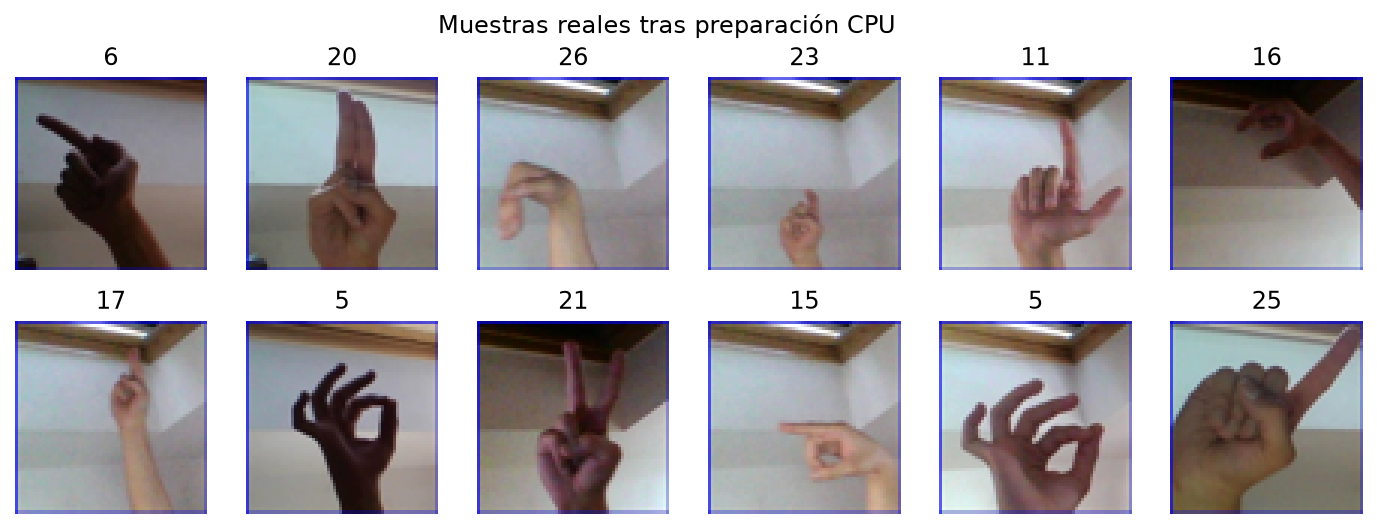

In [19]:
for etiqueta, (imagenes, clases_y) in inputs.items():
    print(etiqueta, "X", imagenes.shape, imagenes.dtype, "y", clases_y.shape, clases_y.dtype,
          "rango", float(imagenes.min()), float(imagenes.max()))
fig, axes = plt.subplots(2,6,figsize=(12,4))
for i,ax in enumerate(axes.flat):
    ax.imshow(x[i]); ax.set_title(str(y[i])); ax.axis("off")
fig.suptitle("Muestras reales tras preparación CPU")
from registro_notebook import mostrar_figura
mostrar_figura(fig)


## FASE GPU: entrenamiento CNN-B, 15 épocas

In [20]:
state('entrenamiento_CNN-B', epoca=1, pasos=0)

train_start_utc, train_start = (utc(), time.perf_counter_ns())

event_totals = {}

validations = 0.0

export_wall = 0.0

with net.timed('h2d_inicial'):
    net.restore()

for phase, seconds in net.drain_events().items():
    event_totals[phase] = event_totals.get(phase, 0.0) + seconds

rng = np.random.Generator(np.random.PCG64(43))

shuffle_hashes = []

for epoch in range(15):
    epoch_start = time.perf_counter()
    net.reset_metrics()
    order = rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j, begin in enumerate(range(0, len(x), 128)):
        indices = order[begin:begin + 128]
        timings = net.train_step(x[indices], y[indices], epoch, j)
        for phase, seconds in timings.items():
            event_totals[phase] = event_totals.get(phase, 0.0) + seconds
        if j % 12 == 0:
            state('entrenamiento_CNN-B', epoca=epoch + 1, pasos=net.steps)
    export_start = time.perf_counter()
    times, total = net.export()
    export_wall += time.perf_counter() - export_start
    for phase, seconds in times.items():
        event_totals[phase] = event_totals.get(phase, 0.0) + seconds
    if int(total[2]) != 12180:
        raise ValueError('Epoch sample counter differs')
    state('validacion_cpu', epoca=epoch + 1, pasos=net.steps)
    val_start = time.perf_counter()
    val = reference.evaluate(vx, vy, batch_size=128, verbose=0, return_dict=True)
    val_s = time.perf_counter() - val_start
    validations += val_s
    epoch_rows.append(dict(epoca=epoch + 1, pasos_acumulados=net.steps, train_loss=float(total[0] / total[2]), train_accuracy=float(total[1] / total[2]), val_loss=float(val['loss']), val_accuracy=float(val['accuracy']), pared_epoca_s=time.perf_counter() - epoch_start, validacion_cpu_s=val_s))
    write_csv(directory / 'epocas.csv', epoch_rows)
    print('EPOCH', epoch + 1, epoch_rows[-1], flush=True)

times, _ = net.export(optimizer=True)

for phase, seconds in times.items():
    event_totals[phase] = event_totals.get(phase, 0.0) + seconds

train_end, train_end_utc = (time.perf_counter_ns(), utc())

add('entrenamiento_CNN-B', (train_end - train_start) / 1000000000.0, start=train_start_utc, end=train_end_utc, epocas=15, pasos=1440, muestras=182700, batch_size=128, motivo='Incluye H2D,D2H,CPUstaging y validacion CPU')

add('validacion_anidada_CNN-B', validations, epocas=15, muestras=39150, motivo='Subintervalo entrenamiento: no sumar dos veces')

for phase, seconds in event_totals.items():
    add(phase, seconds, kind='evento_device', epocas=15, pasos=1440, motivo='Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host')

2026-11-18T04:46:47.375886+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 0}


2026-11-18T04:46:47.971198+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 1}


2026-11-18T04:46:51.117475+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 13}


2026-11-18T04:46:54.275764+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 25}


2026-11-18T04:46:57.432126+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 37}


2026-11-18T04:47:00.610672+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 49}


... (141 outputs left out)

2026-11-18T04:53:38.136107+00:00 entrenamiento_CNN-B {'epoca': 15, 'pasos': 1417}


2026-11-18T04:53:41.352247+00:00 entrenamiento_CNN-B {'epoca': 15, 'pasos': 1429}


2026-11-18T04:53:44.097757+00:00 validacion_cpu {'epoca': 15, 'pasos': 1440}


EPOCH 15 {'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 0.04032161831855774, 'train_accuracy': 0.9899014830589294, 'val_loss': 0.04838373884558678, 'val_accuracy': 0.9858237504959106, 'pared_epoca_s': 27.9680543000577, 'validacion_cpu_s': 2.177519300021231}


## FASE CPU: evaluación final tras D2H

In [21]:
state('evaluacion_final_cpu', pasos=net.steps)

eval_start_utc, eval_start = (utc(), time.perf_counter_ns())

test = reference.evaluate(tx, ty, batch_size=32, verbose=0, return_dict=True)

eval_seconds = (time.perf_counter_ns() - eval_start) / 1000000000.0

add('evaluacion_CNN-B', eval_seconds, start=eval_start_utc, end=utc(), muestras=2610, motivo='CPU tras D2H del modelo; no atribuir a inferencia CUDA')

pipeline_end, pipeline_end_utc = (time.perf_counter_ns(), utc())

add('pipeline_total_cnn_b', (pipeline_end - pipeline_start) / 1000000000.0, start=pipeline_start_utc, end=pipeline_end_utc, epocas=15, pasos=1440, muestras=17400, batch_size=128, motivo='Continuo: preparacion+auditoria explicita+entrenamiento+evaluacion; no baseline total adaptativo CPU')

if net.steps != 1440 or int(reference.optimizer.iterations.numpy()) != 1440:
    raise ValueError('Incorrect training step count')

metrics = dict(test={k: float(v) for k, v in test.items()}, epocas=15, pasos=net.steps, val_final=epoch_rows[-1], accuracy_historica_cpu_min=0.9287356, comparabilidad='Mismos datos,modelo,pasos; RNG/ejecucion diferentes, no identidad numerica')

write_json(directory / 'metricas.json', metrics)

write_json(directory / 'transferencias.json', dict(lotes=net.transfers[-1440:], h2d_estado_inicial_bytes=3 * 2245245 * 4 + 960 * 4 + 24, reinicios_metricas_h2d_bytes=15 * 12, modelo_d2h_copias=16, modelo_bytes_por_copia=2246205 * 4, optimizador_final_bytes=2 * 2245245 * 4 + 8, control_d2h_bytes=1440 * 4, aclaracion='Ultima copia extra de pesos por export final, incluida en pared y eventos'))

write_json(directory / 'ordenes.json', dict(seed=43, generador='PCG64', epocas_sha256=shuffle_hashes))

2026-11-18T04:53:46.336499+00:00 evaluacion_final_cpu {'pasos': 1440}


## Persistencia del modelo y configuración de kernels

In [22]:
state('guardado_fuera_de_timing', pasos=net.steps)

out = ROOT / 'data' / experiment / directory.name

out.mkdir(parents=True, exist_ok=False)

model_path = out / 'CNN-B-CUDA.keras'

reference.save(model_path)

write_json(directory / 'modelo-guardado.json', dict(ruta=model_path.relative_to(ROOT).as_posix(), sha256=sha(model_path), optimizer_iterations=1440, nota='Inferencia Keras CPU; reanudar entrenamiento CUDA requiere claves RNG y estado del adaptador'))

geometries = []

for op in net.ops:
    if op['kind'] == 'conv':
        geometries.append(dict(operacion='im2col', block=[256, 1, 1], grid=[min(4096, (128 * op['H'] * op['W'] * 9 * op['Ci'] + 255) // 256), 1, 1], forma=[128, op['H'], op['W'], op['Ci'], op['Co']]))

write_json(directory / 'lanzamientos.json', dict(propio=geometries, vector_block=256, reduccion_block=[32, 8, 1], reduccion_final_block=256, softmax_block=32, gemm='cuBLAS SGEMM: jerarquia interna gestionada por NVIDIA, no inventada por el equipo', recursos=compiled_resources()))

net.stream.synchronize()

net.blas.close()

state('completada', pasos=1440)

2026-11-18T04:53:48.721163+00:00 guardado_fuera_de_timing {'pasos': 1440}


2026-11-18T04:53:48.885209+00:00 completada {'pasos': 1440}


## Resultados completos de esta ejecución

In [23]:
print((directory / "metricas.json").read_text(encoding="utf8"))
display(pd.read_csv(directory / "tiempos.csv"))
display(pd.read_csv(directory / "epocas.csv"))


{
  "test": {
    "accuracy": 0.9862068891525269,
    "loss": 0.061565157026052475
  },
  "epocas": 15,
  "pasos": 1440,
  "val_final": {
    "epoca": 15,
    "pasos_acumulados": 1440,
    "train_loss": 0.04032161831855774,
    "train_accuracy": 0.9899014830589294,
    "val_loss": 0.04838373884558678,
    "val_accuracy": 0.9858237504959106,
    "pared_epoca_s": 27.9680543000577,
    "validacion_cpu_s": 2.177519300021231
  },
  "accuracy_historica_cpu_min": 0.9287356,
  "comparabilidad": "Mismos datos,modelo,pasos; RNG/ejecucion diferentes, no identidad numerica"
}



,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-009,RUN-20261118T041129Z-cuda-notebook-01,gpu,1,preparacion_cpu,pared,7.785280,2026-11-18T04:46:38.556325+00:00,2026-11-18T04:46:46.341702+00:00,NaN,NaN,17400.0,NaN,True,completada,e32ca585187dadefd17be06457de9aceafc048210ce755fb19b3de6777d3e50f,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-009/RUN-20261118T041129Z-cuda-notebook-01/tiempos.csv,CPU6workers; orden congelado; no atribuir mejora de esta fase a CUDA
1,EXP-009,RUN-20261118T041129Z-cuda-notebook-01,gpu,1,auditoria_tensores,pared,0.452097,NaN,NaN,NaN,NaN,NaN,NaN,True,completada,e32ca585187dadefd17be06457de9aceafc048210ce755fb19b3de6777d3e50f,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-009/RUN-20261118T041129Z-cuda-notebook-01/tiempos.csv,Anidado en pipeline; fuera de entrenamiento y suma comparable
2,EXP-009,RUN-20261118T041129Z-cuda-notebook-01,gpu,1,entrenamiento_CNN-B,pared,418.930299,2026-11-18T04:46:47.376698+00:00,2026-11-18T04:53:46.307015+00:00,15.0,1440.0,182700.0,128.0,True,completada,e32ca585187dadefd17be06457de9aceafc048210ce755fb19b3de6777d3e50f,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-009/RUN-20261118T041129Z-cuda-notebook-01/tiempos.csv,"Incluye H2D,D2H,CPUstaging y validacion CPU"
3,EXP-009,RUN-20261118T041129Z-cuda-notebook-01,gpu,1,validacion_anidada_CNN-B,pared,32.826802,NaN,NaN,15.0,NaN,39150.0,NaN,True,completada,e32ca585187dadefd17be06457de9aceafc048210ce755fb19b3de6777d3e50f,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-009/RUN-20261118T041129Z-cuda-notebook-01/tiempos.csv,Subintervalo entrenamiento: no sumar dos veces
4,EXP-009,RUN-20261118T041129Z-cuda-notebook-01,gpu,1,h2d_inicial,evento_device,0.023789,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,e32ca585187dadefd17be06457de9aceafc048210ce755fb19b3de6777d3e50f,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-009/RUN-20261118T041129Z-cuda-notebook-01/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
5,EXP-009,RUN-20261118T041129Z-cuda-notebook-01,gpu,1,h2d_lotes,evento_device,3.311838,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,e32ca585187dadefd17be06457de9aceafc048210ce755fb19b3de6777d3e50f,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-009/RUN-20261118T041129Z-cuda-notebook-01/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
6,EXP-009,RUN-20261118T041129Z-cuda-notebook-01,gpu,1,forward_loss,evento_device,133.486753,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,e32ca585187dadefd17be06457de9aceafc048210ce755fb19b3de6777d3e50f,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-009/RUN-20261118T041129Z-cuda-notebook-01/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
7,EXP-009,RUN-20261118T041129Z-cuda-notebook-01,gpu,1,backward,evento_device,205.697507,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,e32ca585187dadefd17be06457de9aceafc048210ce755fb19b3de6777d3e50f,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-009/RUN-20261118T041129Z-cuda-notebook-01/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
8,EXP-009,RUN-20261118T041129Z-cuda-notebook-01,gpu,1,adam_metricas,evento_device,0.791045,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,e32ca585187dadefd17be06457de9aceafc048210ce755fb19b3de6777d3e50f,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-009/RUN-20261118T041129Z-cuda-notebook-01/tiempos.csv,Intervalos stream anidados en entrenamiento

,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,1,96,2.756972,0.252463,21.913012,0.126054,27.549405,2.101967
1,2,192,1.388942,0.578325,8.168073,0.370498,27.683986,2.105973
2,3,288,0.815175,0.750575,2.586227,0.578544,27.802846,2.140683
3,4,384,0.525978,0.843596,1.015402,0.778927,28.446730,2.645050
4,5,480,0.343078,0.899097,0.310781,0.921073,27.964431,2.166040
5,6,576,0.239396,0.930706,0.514151,0.852874,27.852869,2.142444
6,7,672,0.185855,0.947373,0.399550,0.888123,27.942581,2.171653
7,8,768,0.141675,0.959113,0.370060,0.919923,27.982728,2.100511
8,9,864,0.110566,0.970197,0.676778,0.830651,27.901216,2.169779
9,10,960,0.093172,0.973645,0.191639,0.949042,27.894538,2.151431


Model: "CNN_B_regularizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         7,453 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,736,697 (25.70 MB)

 Trainable params: 2,245,245 (8.56 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 4,490,492 (17.13 MB)

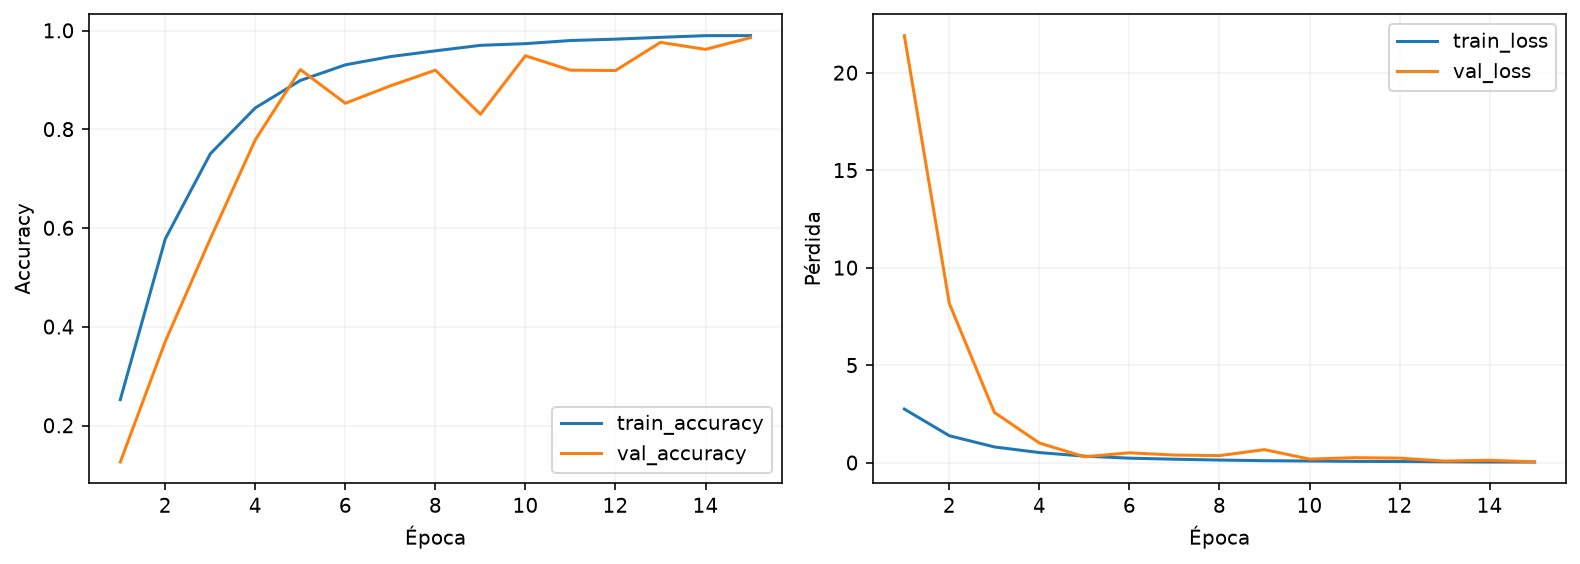


 transferencias.json
{
  "lotes": [
    {
      "batch": 128,
      "imagenes_bytes": 6291456,
      "etiquetas_bytes": 1024,
      "mascaras_bytes": 7372800
    },
    {
      "batch": 128,
      "imagenes_bytes": 6291456,
      "etiquetas_bytes": 1024,
      "mascaras_bytes": 7372800
    },
    {
      "batch": 128,
      "imagenes_bytes": 6291456,
      "etiquetas_bytes": 1024,
      "mascaras_bytes": 7372800
    },
    {
      "batch": 128,
      "imagenes_bytes": 6291456,
      "etiquetas_bytes": 1024,
      "mascaras_bytes": 7372800
    },
    {
      "batch": 128,
      "imagenes_bytes": 6291456,
      "etiquetas_bytes": 1024,
      "mascaras_bytes": 7372800
    },
    {
      "batch": 128,
      "imagenes_bytes": 6291456,
      "etiquetas_bytes": 1024,
      "mascaras_bytes": 7372800
    },
    {
      "batch": 128,
      "imagenes_bytes": 6291456,
      "etiquetas_bytes": 1024,
      "mascaras_bytes": 7372800
    },
    {
      "batch": 128,
      "imagenes_bytes": 6291456,
 

In [24]:
reference.summary()
epocas = pd.read_csv(directory / "epocas.csv")
fig, axes = plt.subplots(1,2,figsize=(11,4))
for name in ("train_accuracy","val_accuracy"): axes[0].plot(epocas.epoca,epocas[name],label=name)
for name in ("train_loss","val_loss"): axes[1].plot(epocas.epoca,epocas[name],label=name)
for ax in axes: ax.set_xlabel("Época");ax.grid(alpha=.15);ax.legend()
axes[0].set_ylabel("Accuracy");axes[1].set_ylabel("Pérdida");fig.tight_layout();mostrar_figura(fig)
for nombre in ("transferencias.json","lanzamientos.json","modelo-guardado.json","ordenes.json"):
    print("\n",nombre);print((directory/nombre).read_text(encoding="utf8"))


## Recursos utilizados, logs y cierre de la ejecución nueva

,utc,transcurrido_s,fase,modelo,epoca,cpu_procesos_pct,rss_bytes,gpu_util_pct,gpu_mem_util_pct,gpu_mem_used_mib,gpu_temperatura_c,cpu_logico_00_pct,cpu_logico_01_pct,cpu_logico_02_pct,cpu_logico_03_pct,cpu_logico_04_pct,cpu_logico_05_pct,cpu_logico_06_pct,cpu_logico_07_pct,cpu_logico_08_pct,cpu_logico_09_pct,cpu_logico_10_pct,cpu_logico_11_pct
0,2026-11-18T04:46:02.277102+00:00,0.001708,inicio,NaN,NaN,0.000000,137805824,0.0,0.0,0.0,49.0,0.0,40.0,20.0,20.0,40.0,0.0,0.0,0.0,50.0,40.0,16.7,0.0
1,2026-11-18T04:46:03.278950+00:00,1.011894,inicio,NaN,NaN,38.668633,160845824,0.0,0.0,0.0,49.0,36.8,48.4,53.1,30.3,20.3,23.1,28.1,18.8,30.8,26.2,36.9,37.5
2,2026-11-18T04:46:04.289337+00:00,2.020271,inicio,NaN,NaN,35.638963,190443520,0.0,0.0,0.0,49.0,23.9,28.1,57.6,15.6,19.7,25.4,47.0,26.2,44.6,31.8,38.8,49.3
3,2026-11-18T04:46:05.318716+00:00,3.033903,inicio,NaN,NaN,15.414852,203169792,0.0,0.0,0.0,49.0,35.2,20.9,34.8,16.4,16.7,9.1,34.8,21.5,21.2,6.1,11.9,44.8
4,2026-11-18T04:46:06.295097+00:00,4.044123,inicio,NaN,NaN,21.653710,214441984,0.0,0.0,0.0,49.0,40.0,38.1,45.2,16.1,33.9,9.7,17.7,7.9,16.1,14.5,19.0,14.5
5,2026-11-18T04:46:07.301224+00:00,5.052937,verificacion_fuentes_y_datos,NaN,NaN,78.991255,235945984,0.0,0.0,0.0,49.0,30.9,26.2,59.7,15.6,48.5,18.5,24.6,29.2,29.9,17.2,27.9,32.3
6,2026-11-18T04:46:08.325974+00:00,6.059462,verificacion_fuentes_y_datos,NaN,NaN,72.961463,235974656,0.0,0.0,0.0,49.0,4.6,12.1,70.8,4.5,9.2,7.6,13.6,6.1,13.8,13.4,3.1,10.6
7,2026-11-18T04:46:09.338041+00:00,7.069536,verificacion_fuentes_y_datos,NaN,NaN,57.235883,237010944,0.0,0.0,0.0,49.0,28.8,10.6,53.0,4.6,21.2,13.8,19.7,6.2,13.6,7.6,15.2,20.0
8,2026-11-18T04:46:10.336354+00:00,8.084895,verificacion_fuentes_y_datos,NaN,NaN,72.326664,237010944,0.0,0.0,0.0,49.0,4.7,7.8,55.4,0.0,31.2,1.5,4.6,7.8,4.7,9.4,7.7,9.4
9,2026-11-18T04:46:11.344009+00:00,9.092994,verificacion_fuentes_y_datos,NaN,NaN,77.497357,235974656,0.0,0.0,0.0,49.0,6.2,4.7,40.0,1.6,56.1,1.6,6.2,7.8,1.6,6.2,3.1,6.2


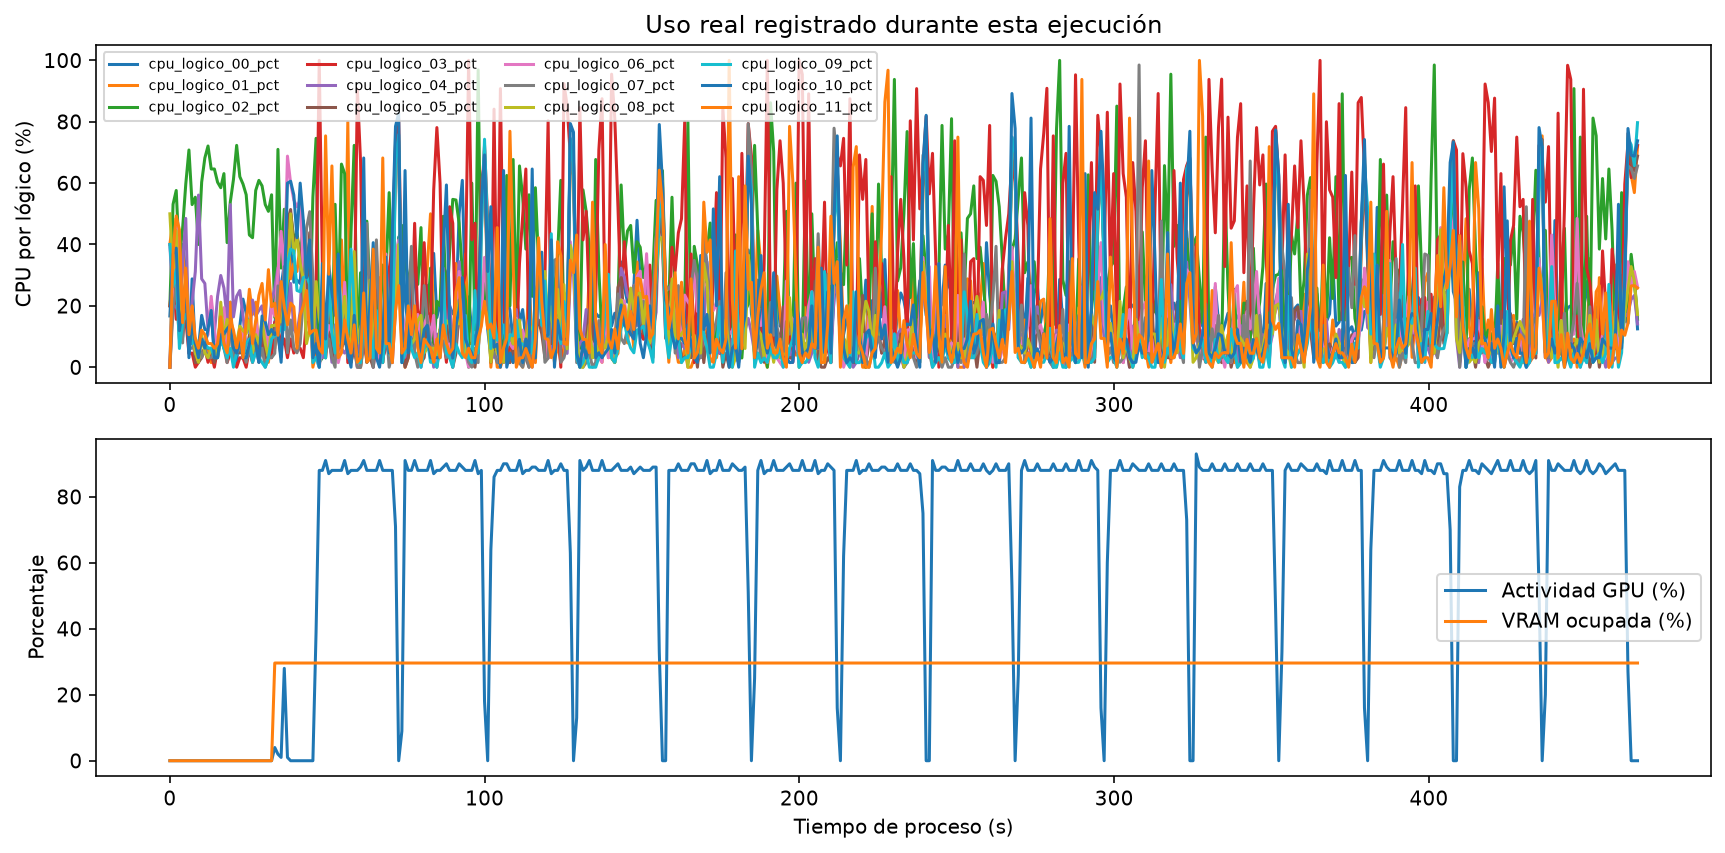

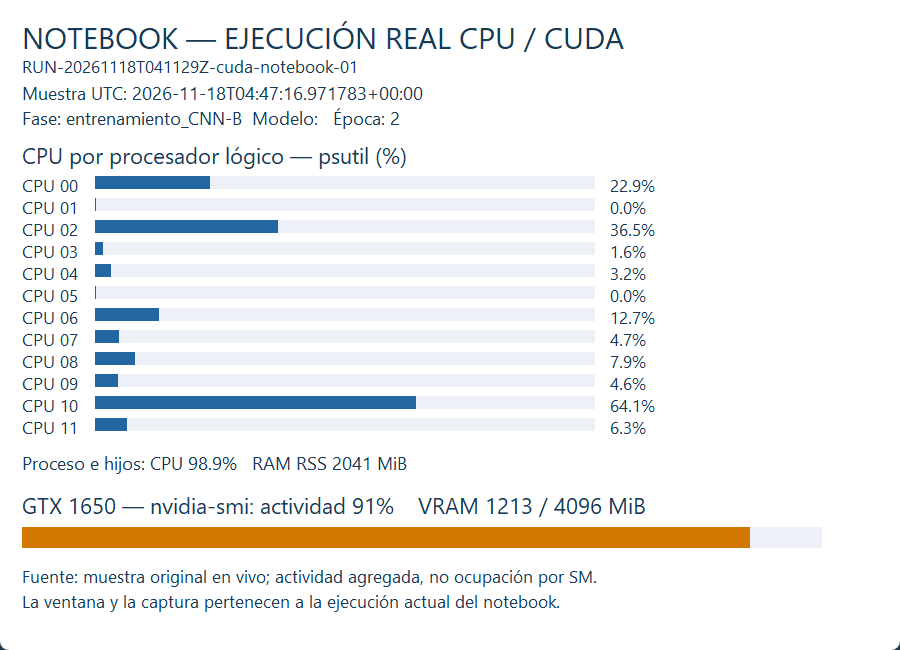

captura-cuda.png {
  "tipo": "captura_original_monitor_en_vivo",
  "captura_utc": "2026-11-18T04:47:18.130626+00:00",
  "run_id": "RUN-20261118T041129Z-cuda-notebook-01",
  "muestra_original": {
    "utc": "2026-11-18T04:47:16.971783+00:00",
    "transcurrido_s": "74.718877300038",
    "fase": "entrenamiento_CNN-B",
    "modelo": "",
    "epoca": "2",
    "cpu_procesos_pct": "98.91316195116735",
    "rss_bytes": "2140184576",
    "gpu_util_pct": "91.0",
    "gpu_mem_util_pct": "28.0",
    "gpu_mem_used_mib": "1213.0",
    "gpu_temperatura_c": "65.0",
    "cpu_logico_00_pct": "22.9",
    "cpu_logico_01_pct": "0.0",
    "cpu_logico_02_pct": "36.5",
    "cpu_logico_03_pct": "1.6",
    "cpu_logico_04_pct": "3.2",
    "cpu_logico_05_pct": "0.0",
    "cpu_logico_06_pct": "12.7",
    "cpu_logico_07_pct": "4.7",
    "cpu_logico_08_pct": "7.9",
    "cpu_logico_09_pct": "4.6",
    "cpu_logico_10_pct": "64.1",
    "cpu_logico_11_pct": "6.3"
  },
  "sha256": "cc9433b5523356312ae674fb338415f7c2704c

In [25]:
monitor_stop.set(); monitor_thread.join(timeout=15)
threadpool_guard.__exit__(None,None,None)
recursos_actuales = pd.read_csv(directory / "recursos.csv")
display(recursos_actuales)
columnas_cpu=[c for c in recursos_actuales if c.startswith("cpu_logico_")]
fig, axes = plt.subplots(2,1,figsize=(12,6))
for col in columnas_cpu: axes[0].plot(recursos_actuales.transcurrido_s,recursos_actuales[col],label=col)
axes[0].set(ylabel="CPU por lógico (%)",title="Uso real registrado durante esta ejecución")
axes[0].legend(ncol=4,fontsize=7)
axes[1].plot(recursos_actuales.transcurrido_s,recursos_actuales.gpu_util_pct,label="Actividad GPU (%)")
axes[1].plot(recursos_actuales.transcurrido_s,recursos_actuales.gpu_mem_used_mib/4096*100,label="VRAM ocupada (%)")
axes[1].set(xlabel="Tiempo de proceso (s)",ylabel="Porcentaje");axes[1].legend();fig.tight_layout();mostrar_figura(fig)
for captura in sorted(directory.glob("captura-*.png")):
    display(NotebookImage(filename=str(captura)))
    print(captura.name, (captura.with_suffix(".json")).read_text(encoding="utf8"))
write_json(directory / "salida.json",dict(codigo=0,fin_utc=utc(),tipo="ejecucion_directa_notebook"))
print("EJECUCIÓN NUEVA COMPLETA:", directory.name)


## Cinco mediciones históricas del informe — registros íntegros

Esta sección es histórica y está separada de la corrida nueva anterior. Se muestran stdout/stderr completos,épocas,métricas y tiempos de cada RUN. No se vuelven a entrenar ni se mezclan con el promedio original.

### Registro histórico RUN-20261117T231628Z-gpu-01

In [26]:
historico = ROOT / "resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T231628Z-gpu-01
2026-11-17T23:16:31.330749+00:00 verificacion_fuentes_y_datos {}
2026-11-17T23:16:54.451494+00:00 inicializacion_y_warmup {}
2026-11-17T23:17:04.606758+00:00 preparacion_cpu {'workers': 6}
2026-11-17T23:17:12.834798+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 0}
2026-11-17T23:17:13.405158+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 1}
2026-11-17T23:17:16.597342+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 13}
2026-11-17T23:17:19.796929+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 25}
2026-11-17T23:17:22.998253+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 37}
2026-11-17T23:17:26.201451+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 49}
2026-11-17T23:17:29.412332+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 61}
2026-11-17T23:17:32.625872+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 73}
2026-11-17T23:17:35.845104+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 85}
2026-11-17T23:17:38.590162+00:00 validacion_cpu {'epoca': 1, 'p

,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,1,96,2.756972,0.252463,21.913012,0.126054,27.751971,2.021026
1,2,192,1.388942,0.578325,8.168073,0.370498,27.498949,2.178709
2,3,288,0.815175,0.750575,2.586227,0.578544,27.563220,2.059548
3,4,384,0.525978,0.843596,1.015402,0.778927,27.582406,2.046511
4,5,480,0.343078,0.899097,0.310781,0.921073,27.655357,2.046862
5,6,576,0.239396,0.930706,0.514151,0.852874,27.732394,2.086313
6,7,672,0.185855,0.947373,0.399550,0.888123,27.692383,2.028168
7,8,768,0.141675,0.959113,0.370060,0.919923,27.728904,2.069489
8,9,864,0.110566,0.970197,0.676778,0.830651,27.694224,2.088270
9,10,960,0.093172,0.973645,0.191639,0.949042,27.787860,2.066184


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,preparacion_cpu,pared,7.785163,2026-11-17T23:17:04.606845+00:00,2026-11-17T23:17:12.392019+00:00,NaN,NaN,17400.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01/tiempos.csv,CPU6workers; orden congelado; no atribuir mejora de esta fase a CUDA
1,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,auditoria_tensores,pared,0.440732,NaN,NaN,NaN,NaN,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01/tiempos.csv,Anidado en pipeline; fuera de entrenamiento y suma comparable
2,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,entrenamiento_CNN-B,pared,415.499294,2026-11-17T23:17:12.834892+00:00,2026-11-17T23:24:08.334202+00:00,15.0,1440.0,182700.0,128.0,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01/tiempos.csv,"Incluye H2D,D2H,CPUstaging y validacion CPU"
3,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,validacion_anidada_CNN-B,pared,31.113583,NaN,NaN,15.0,NaN,39150.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01/tiempos.csv,Subintervalo entrenamiento: no sumar dos veces
4,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,h2d_inicial,evento_device,0.023897,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
5,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,h2d_lotes,evento_device,3.283287,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
6,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,forward_loss,evento_device,133.184236,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
7,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,backward,evento_device,204.880216,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
8,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,adam_metricas,evento_device,0.805197,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T231628Z-gpu-01/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
9,EXP-003,RUN-20261117T231628Z-gpu-01,gpu,1,d2h_control,evento_device,0.162847,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db1

{
  "test": {
    "accuracy": 0.9862068891525269,
    "loss": 0.061565157026052475
  },
  "epocas": 15,
  "pasos": 1440,
  "val_final": {
    "epoca": 15,
    "pasos_acumulados": 1440,
    "train_loss": 0.04032161831855774,
    "train_accuracy": 0.9899014830589294,
    "val_loss": 0.04838373884558678,
    "val_accuracy": 0.9858237504959106,
    "pared_epoca_s": 27.79496939998353,
    "validacion_cpu_s": 2.148753500019666
  },
  "accuracy_historica_cpu_min": 0.9287356,
  "comparabilidad": "Mismos datos,modelo,pasos; RNG/ejecucion diferentes, no identidad numerica"
}



### Registro histórico RUN-20261117T232412Z-gpu-02

In [27]:
historico = ROOT / "resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T232412Z-gpu-02
2026-11-17T23:24:14.734912+00:00 verificacion_fuentes_y_datos {}
2026-11-17T23:24:24.638460+00:00 inicializacion_y_warmup {}
2026-11-17T23:24:34.689876+00:00 preparacion_cpu {'workers': 6}
2026-11-17T23:24:43.133265+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 0}
2026-11-17T23:24:43.666055+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 1}
2026-11-17T23:24:46.842396+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 13}
2026-11-17T23:24:50.020846+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 25}
2026-11-17T23:24:53.203438+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 37}
2026-11-17T23:24:56.389344+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 49}
2026-11-17T23:24:59.581971+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 61}
2026-11-17T23:25:02.787700+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 73}
2026-11-17T23:25:05.987814+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 85}
2026-11-17T23:25:08.715253+00:00 validacion_cpu {'epoca': 1, 'p

,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,1,96,2.756972,0.252463,21.913012,0.126054,27.563200,2.004514
1,2,192,1.388942,0.578325,8.168073,0.370498,27.777895,2.065622
2,3,288,0.815175,0.750575,2.586227,0.578544,27.754054,2.070986
3,4,384,0.525978,0.843596,1.015402,0.778927,27.723567,1.971546
4,5,480,0.343078,0.899097,0.310781,0.921073,27.743603,2.029749
5,6,576,0.239396,0.930706,0.514151,0.852874,27.763307,2.053555
6,7,672,0.185855,0.947373,0.399550,0.888123,27.789903,2.011079
7,8,768,0.141675,0.959113,0.370060,0.919923,27.755190,2.074403
8,9,864,0.110566,0.970197,0.676778,0.830651,27.752685,2.004957
9,10,960,0.093172,0.973645,0.191639,0.949042,27.744608,2.043594


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,preparacion_cpu,pared,8.002736,2026-11-17T23:24:34.689965+00:00,2026-11-17T23:24:42.692713+00:00,NaN,NaN,17400.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02/tiempos.csv,CPU6workers; orden congelado; no atribuir mejora de esta fase a CUDA
1,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,auditoria_tensores,pared,0.438280,NaN,NaN,NaN,NaN,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02/tiempos.csv,Anidado en pipeline; fuera de entrenamiento y suma comparable
2,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,entrenamiento_CNN-B,pared,418.797018,2026-11-17T23:24:43.133354+00:00,2026-11-17T23:31:41.930385+00:00,15.0,1440.0,182700.0,128.0,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02/tiempos.csv,"Incluye H2D,D2H,CPUstaging y validacion CPU"
3,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,validacion_anidada_CNN-B,pared,32.533162,NaN,NaN,15.0,NaN,39150.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02/tiempos.csv,Subintervalo entrenamiento: no sumar dos veces
4,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,h2d_inicial,evento_device,0.022834,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
5,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,h2d_lotes,evento_device,3.291827,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
6,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,forward_loss,evento_device,133.597691,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
7,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,backward,evento_device,206.134463,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
8,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,adam_metricas,evento_device,0.791121,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T232412Z-gpu-02/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
9,EXP-003,RUN-20261117T232412Z-gpu-02,gpu,2,d2h_control,evento_device,0.158565,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db1

{
  "test": {
    "accuracy": 0.9862068891525269,
    "loss": 0.061565157026052475
  },
  "epocas": 15,
  "pasos": 1440,
  "val_final": {
    "epoca": 15,
    "pasos_acumulados": 1440,
    "train_loss": 0.04032161831855774,
    "train_accuracy": 0.9899014830589294,
    "val_loss": 0.04838373884558678,
    "val_accuracy": 0.9858237504959106,
    "pared_epoca_s": 28.68622009997489,
    "validacion_cpu_s": 2.7050629000295885
  },
  "accuracy_historica_cpu_min": 0.9287356,
  "comparabilidad": "Mismos datos,modelo,pasos; RNG/ejecucion diferentes, no identidad numerica"
}



### Registro histórico RUN-20261117T233146Z-gpu-03

In [28]:
historico = ROOT / "resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T233146Z-gpu-03
2026-11-17T23:31:49.463840+00:00 verificacion_fuentes_y_datos {}
2026-11-17T23:31:59.398980+00:00 inicializacion_y_warmup {}
2026-11-17T23:32:09.709757+00:00 preparacion_cpu {'workers': 6}
2026-11-17T23:32:18.845895+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 0}
2026-11-17T23:32:19.397456+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 1}
2026-11-17T23:32:22.579134+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 13}
2026-11-17T23:32:25.765332+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 25}
2026-11-17T23:32:28.952624+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 37}
2026-11-17T23:32:32.143401+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 49}
2026-11-17T23:32:35.342182+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 61}
2026-11-17T23:32:38.546365+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 73}
2026-11-17T23:32:41.752854+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 85}
2026-11-17T23:32:44.487741+00:00 validacion_cpu {'epoca': 1, 'p

I0000 00:00:1794958319.470012    9552 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794958323.347034    9552 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794958327.211808    9552 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
E0000 00:00:1794958364.584833    9552 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is

,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,1,96,2.756972,0.252463,21.913012,0.126054,28.103615,2.486517
1,2,192,1.388942,0.578325,8.168073,0.370498,27.756204,2.058934
2,3,288,0.815175,0.750575,2.586227,0.578544,28.054185,2.294939
3,4,384,0.525978,0.843596,1.015402,0.778927,28.024910,2.182495
4,5,480,0.343078,0.899097,0.310781,0.921073,27.979908,2.221994
5,6,576,0.239396,0.930706,0.514151,0.852874,28.234332,2.469687
6,7,672,0.185855,0.947373,0.399550,0.888123,28.030409,2.203914
7,8,768,0.141675,0.959113,0.370060,0.919923,27.867432,2.154597
8,9,864,0.110566,0.970197,0.676778,0.830651,27.828138,2.106647
9,10,960,0.093172,0.973645,0.191639,0.949042,27.841877,2.075366


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,preparacion_cpu,pared,8.693341,2026-11-17T23:32:09.709839+00:00,2026-11-17T23:32:18.403192+00:00,NaN,NaN,17400.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03/tiempos.csv,CPU6workers; orden congelado; no atribuir mejora de esta fase a CUDA
1,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,auditoria_tensores,pared,0.440558,NaN,NaN,NaN,NaN,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03/tiempos.csv,Anidado en pipeline; fuera de entrenamiento y suma comparable
2,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,entrenamiento_CNN-B,pared,420.508824,2026-11-17T23:32:18.845987+00:00,2026-11-17T23:39:19.354822+00:00,15.0,1440.0,182700.0,128.0,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03/tiempos.csv,"Incluye H2D,D2H,CPUstaging y validacion CPU"
3,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,validacion_anidada_CNN-B,pared,33.538533,NaN,NaN,15.0,NaN,39150.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03/tiempos.csv,Subintervalo entrenamiento: no sumar dos veces
4,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,h2d_inicial,evento_device,0.024227,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
5,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,h2d_lotes,evento_device,3.288332,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
6,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,forward_loss,evento_device,134.135618,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
7,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,backward,evento_device,206.643643,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
8,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,adam_metricas,evento_device,0.791997,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233146Z-gpu-03/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
9,EXP-003,RUN-20261117T233146Z-gpu-03,gpu,3,d2h_control,evento_device,0.157849,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db1

{
  "test": {
    "accuracy": 0.9862068891525269,
    "loss": 0.061565157026052475
  },
  "epocas": 15,
  "pasos": 1440,
  "val_final": {
    "epoca": 15,
    "pasos_acumulados": 1440,
    "train_loss": 0.04032161831855774,
    "train_accuracy": 0.9899014830589294,
    "val_loss": 0.04838373884558678,
    "val_accuracy": 0.9858237504959106,
    "pared_epoca_s": 28.275734700029716,
    "validacion_cpu_s": 2.3601692999945953
  },
  "accuracy_historica_cpu_min": 0.9287356,
  "comparabilidad": "Mismos datos,modelo,pasos; RNG/ejecucion diferentes, no identidad numerica"
}



### Registro histórico RUN-20261117T233923Z-gpu-04

In [29]:
historico = ROOT / "resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T233923Z-gpu-04
2026-11-17T23:39:26.120734+00:00 verificacion_fuentes_y_datos {}
2026-11-17T23:39:36.644197+00:00 inicializacion_y_warmup {}
2026-11-17T23:39:47.048265+00:00 preparacion_cpu {'workers': 6}
2026-11-17T23:39:55.277770+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 0}
2026-11-17T23:39:55.764710+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 1}
2026-11-17T23:39:58.970799+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 13}
2026-11-17T23:40:02.162452+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 25}
2026-11-17T23:40:05.358523+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 37}
2026-11-17T23:40:08.562871+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 49}
2026-11-17T23:40:11.767598+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 61}
2026-11-17T23:40:14.979846+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 73}
2026-11-17T23:40:18.193022+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 85}
2026-11-17T23:40:20.929671+00:00 validacion_cpu {'epoca': 1, 'p

I0000 00:00:1794958776.715104   27496 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794958780.627892   27496 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794958784.621445   27496 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
E0000 00:00:1794958821.015345   27496 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is

,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,1,96,2.756972,0.252463,21.913012,0.126054,27.813795,2.185542
1,2,192,1.388942,0.578325,8.168073,0.370498,28.045449,2.166653
2,3,288,0.815175,0.750575,2.586227,0.578544,28.005730,2.114507
3,4,384,0.525978,0.843596,1.015402,0.778927,28.100695,2.170820
4,5,480,0.343078,0.899097,0.310781,0.921073,27.986458,2.094298
5,6,576,0.239396,0.930706,0.514151,0.852874,27.944464,2.121543
6,7,672,0.185855,0.947373,0.399550,0.888123,28.048412,2.145788
7,8,768,0.141675,0.959113,0.370060,0.919923,27.874919,2.115297
8,9,864,0.110566,0.970197,0.676778,0.830651,27.958332,2.179029
9,10,960,0.093172,0.973645,0.191639,0.949042,28.030592,2.170981


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,preparacion_cpu,pared,7.785700,2026-11-17T23:39:47.048349+00:00,2026-11-17T23:39:54.834060+00:00,NaN,NaN,17400.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04/tiempos.csv,CPU6workers; orden congelado; no atribuir mejora de esta fase a CUDA
1,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,auditoria_tensores,pared,0.440925,NaN,NaN,NaN,NaN,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04/tiempos.csv,Anidado en pipeline; fuera de entrenamiento y suma comparable
2,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,entrenamiento_CNN-B,pared,419.771853,2026-11-17T23:39:55.277854+00:00,2026-11-17T23:46:55.049720+00:00,15.0,1440.0,182700.0,128.0,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04/tiempos.csv,"Incluye H2D,D2H,CPUstaging y validacion CPU"
3,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,validacion_anidada_CNN-B,pared,32.147011,NaN,NaN,15.0,NaN,39150.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04/tiempos.csv,Subintervalo entrenamiento: no sumar dos veces
4,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,h2d_inicial,evento_device,0.023148,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
5,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,h2d_lotes,evento_device,3.292517,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
6,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,forward_loss,evento_device,134.225176,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
7,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,backward,evento_device,207.137439,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
8,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,adam_metricas,evento_device,0.797226,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T233923Z-gpu-04/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
9,EXP-003,RUN-20261117T233923Z-gpu-04,gpu,4,d2h_control,evento_device,0.153510,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db1

{
  "test": {
    "accuracy": 0.9862068891525269,
    "loss": 0.061565157026052475
  },
  "epocas": 15,
  "pasos": 1440,
  "val_final": {
    "epoca": 15,
    "pasos_acumulados": 1440,
    "train_loss": 0.04032161831855774,
    "train_accuracy": 0.9899014830589294,
    "val_loss": 0.04838373884558678,
    "val_accuracy": 0.9858237504959106,
    "pared_epoca_s": 28.023385200009216,
    "validacion_cpu_s": 2.1438656999962404
  },
  "accuracy_historica_cpu_min": 0.9287356,
  "comparabilidad": "Mismos datos,modelo,pasos; RNG/ejecucion diferentes, no identidad numerica"
}



### Registro histórico RUN-20261117T234658Z-gpu-05

In [30]:
historico = ROOT / "resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T234658Z-gpu-05
2026-11-17T23:47:01.526435+00:00 verificacion_fuentes_y_datos {}
2026-11-17T23:47:11.975953+00:00 inicializacion_y_warmup {}
2026-11-17T23:47:22.002351+00:00 preparacion_cpu {'workers': 6}
2026-11-17T23:47:30.347437+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 0}
2026-11-17T23:47:30.951589+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 1}
2026-11-17T23:47:34.133008+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 13}
2026-11-17T23:47:37.318800+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 25}
2026-11-17T23:47:40.522054+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 37}
2026-11-17T23:47:43.718089+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 49}
2026-11-17T23:47:46.918084+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 61}
2026-11-17T23:47:50.121049+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 73}
2026-11-17T23:47:53.331215+00:00 entrenamiento_CNN-B {'epoca': 1, 'pasos': 85}
2026-11-17T23:47:56.065194+00:00 validacion_cpu {'epoca': 1, 'p

I0000 00:00:1794959232.047890   40004 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794959235.807508   40004 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794959239.564043   40004 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
E0000 00:00:1794959276.154769   40004 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is

,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,1,96,2.756972,0.252463,21.913012,0.126054,27.773231,2.082906
1,2,192,1.388942,0.578325,8.168073,0.370498,27.794675,2.111952
2,3,288,0.815175,0.750575,2.586227,0.578544,27.872142,2.087336
3,4,384,0.525978,0.843596,1.015402,0.778927,27.871395,2.100118
4,5,480,0.343078,0.899097,0.310781,0.921073,27.911686,2.122074
5,6,576,0.239396,0.930706,0.514151,0.852874,27.940437,2.167645
6,7,672,0.185855,0.947373,0.399550,0.888123,27.835304,2.121117
7,8,768,0.141675,0.959113,0.370060,0.919923,27.888761,2.168768
8,9,864,0.110566,0.970197,0.676778,0.830651,27.941438,2.239997
9,10,960,0.093172,0.973645,0.191639,0.949042,28.029956,2.241366


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,preparacion_cpu,pared,7.904785,2026-11-17T23:47:22.002457+00:00,2026-11-17T23:47:29.907258+00:00,NaN,NaN,17400.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05/tiempos.csv,CPU6workers; orden congelado; no atribuir mejora de esta fase a CUDA
1,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,auditoria_tensores,pared,0.437439,NaN,NaN,NaN,NaN,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05/tiempos.csv,Anidado en pipeline; fuera de entrenamiento y suma comparable
2,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,entrenamiento_CNN-B,pared,418.461426,2026-11-17T23:47:30.347606+00:00,2026-11-17T23:54:28.809055+00:00,15.0,1440.0,182700.0,128.0,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05/tiempos.csv,"Incluye H2D,D2H,CPUstaging y validacion CPU"
3,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,validacion_anidada_CNN-B,pared,32.285709,NaN,NaN,15.0,NaN,39150.0,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05/tiempos.csv,Subintervalo entrenamiento: no sumar dos veces
4,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,h2d_inicial,evento_device,0.026811,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
5,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,h2d_lotes,evento_device,3.287729,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
6,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,forward_loss,evento_device,133.872611,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
7,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,backward,evento_device,206.283012,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
8,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,adam_metricas,evento_device,0.794754,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db134fdbb866b91cce2006c0ee7fa43812476337970a6cfb583,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/paralelo/EXP-003/RUN-20261117T234658Z-gpu-05/tiempos.csv,Intervalos stream anidados en entrenamiento; incluyen posibles huecos de envio Host
9,EXP-003,RUN-20261117T234658Z-gpu-05,gpu,5,d2h_control,evento_device,0.152819,NaN,NaN,15.0,1440.0,NaN,NaN,True,completada,00866b6fa0d48db1

{
  "test": {
    "accuracy": 0.9862068891525269,
    "loss": 0.061565157026052475
  },
  "epocas": 15,
  "pasos": 1440,
  "val_final": {
    "epoca": 15,
    "pasos_acumulados": 1440,
    "train_loss": 0.04032161831855774,
    "train_accuracy": 0.9899014830589294,
    "val_loss": 0.04838373884558678,
    "val_accuracy": 0.9858237504959106,
    "pared_epoca_s": 27.875098299991805,
    "validacion_cpu_s": 2.159979399992153
  },
  "accuracy_historica_cpu_min": 0.9287356,
  "comparabilidad": "Mismos datos,modelo,pasos; RNG/ejecucion diferentes, no identidad numerica"
}



## Comparación histórica del informe (no incluye la corrida nueva)

In [31]:
display(pd.read_csv(ROOT/"resultados/paralelo/EXP-003/comparacion_cnn_b.csv"))
display(pd.read_csv(ROOT/"resultados/paralelo/EXP-003/speedup.csv"))
print("Solo CNN-B base comparable. Preparación1→6workers es mejoraCPU;referencia histórica,RNG distinto y sin afirmación de saturaciónSM/VRAM.")


,dispositivo,run_id,preparacion_cpu_s,entrenamiento_s,evaluacion_cpu_s,validacion_anidada_s,suma_comparable_s,total_continuo_gpu_s,h2d_eventos_s,d2h_eventos_s,computo_intervalos_stream_s,administracion_y_staging_s
0,cpu,RUN-20261117T171942Z-cpu-01,17.963012,803.847403,2.444951,31.305076,824.255365,NaN,NaN,NaN,NaN,NaN
1,cpu,RUN-20261117T175407Z-cpu-02,17.439833,806.869706,2.280797,32.114380,826.590335,NaN,NaN,NaN,NaN,NaN
2,cpu,RUN-20261117T182835Z-cpu-03,17.072772,802.320202,2.297889,31.500546,821.690863,NaN,NaN,NaN,NaN,NaN
3,cpu,RUN-20261117T190250Z-cpu-04,17.267030,809.363247,2.323036,31.299847,828.953313,NaN,NaN,NaN,NaN,NaN
4,cpu,RUN-20261117T192509Z-cpu-05,16.879898,805.848071,2.265277,32.353673,824.993247,NaN,NaN,NaN,NaN,NaN
5,gpu,RUN-20261117T231628Z-gpu-01,7.785163,415.499294,2.168861,31.113583,425.453318,425.904461,3.307184,0.220608,338.869649,41.988270
6,gpu,RUN-20261117T232412Z-gpu-02,8.002736,418.797018,3.144971,32.533162,429.944725,430.397394,3.314661,0.219393,340.523275,42.206527
7,gpu,RUN-20261117T233146Z-gpu-03,8.693341,420.508824,2.478408,33.538533,431.680572,432.131440,3.312559,0.214493,341.571258,41.871980
8,gpu,RUN-20261117T233923Z-gpu-04,7.785700,419.771853,2.313765,32.147011,429.871317,430.323723,3.315666,0.209487,342.159841,41.939848
9,gpu,RUN-20261117T234658Z-gpu-05,7.904785,418.461426,2.354958,32.285709,428.721169,429.172212,3.314539,0.210523,340.950377,41.700278


,fase,n_cpu,n_gpu,media_cpu_s,media_gpu_s,speedup,interpretacion
0,preparacion_cpu_s,5,5,17.324509,8.034345,2.156306,"CPU1vs6workers, no CUDA"
1,entrenamiento_s,5,5,805.649726,418.607683,1.924594,Mismo alcance; incluye transferencias y validacion
2,evaluacion_cpu_s,5,5,2.322390,2.492192,0.931866,Ambas evaluaciones CPU
3,suma_comparable_s,5,5,825.296624,429.134220,1.923167,Mismo alcance; incluye transferencias y validacion


Solo CNN-B base comparable. Preparación1→6workers es mejoraCPU;referencia histórica,RNG distinto y sin afirmación de saturaciónSM/VRAM.


## Alcance de esta ejecución adicional

Las celdas de cálculo anteriores fueron ejecutadas directamente con PCUDA y
conservan sus salidas nativas. Esta corrida adicional no reemplaza las cinco
mediciones históricas del informe. **Los totales continuos de este notebook
incluyen presentación de tablas/gráficas entre fases**; los intervalos fit/evaluate
individuales mantienen sus fronteras. No se mezclan alcances para calcular speedup.

La configuración y el RUN se conservan. Para repetir el entrenamiento debe
prepararse otro EXP/RUN; abrir el notebook permite leer todas sus salidas sin
volver a entrenar. Los avisos del kernel nativo se anexan abajo porque TensorFlow
puede escribir directamente a stderr del sistema, fuera del canal de salida de
las celdas. Este anexo documental no simula una ejecución de código.


## Diagnósticos nativos completos del kernel

Texto literal del tramo de stderr del supervisor correspondiente a este kernel. Los avisos se conservan; la corrida completó con código0.

```text
[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1794977185.386541   41264 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1794977190.659785   41264 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794977194.154967   41264 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
E0000 00:00:1794977232.940708   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977260.603483   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977288.374372   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977316.320373   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977344.762730   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977372.643640   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977400.561527   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977428.623671   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977456.448083   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977484.363157   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977512.314874   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977540.249116   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977568.123034   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977596.208523   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977624.172345   41264 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}

```

# Sesiones nuevas: extensión a FC-A y FC-B

Las celdas anteriores y sus salidas se conservan íntegramente como evidencia CNN-B. Se anexan las celdas reales de FC-A1 ya guardada, su cierre recuperado de archivos y las nueve corridas restantes. Los contadores nativos reinician en cada sesión. No se volvió a ejecutar CNN-B ni el notebook CPU. EXP-010 quedó incompleto por exportaciónCSV y no integra los promedios. EXP-011 aporta FC-A1 guardada; EXP-012 ejecuta exclusivamente FC-A2–5 yFC-B1–5.

# Ampliación CUDA: FC-A y FC-B

Ejecución nueva y nativa, exclusiva de estas dos redes. Cinco corridas por arquitectura. Las campañas CPU y CNN-B anteriores **no se ejecutan**. Preparación y validación en CPU; entrenamiento matemático en CUDA Python/cuBLAS. Datos e inicialización históricos verificados. Los contadores pertenecen a esta sesión nueva, distinta del notebook CNN-B previo.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, time, csv, gc, subprocess
ROOT=Path.cwd()
while not (ROOT/'docs/Proyecto 3 CUDA.pdf').is_file():
    if ROOT==ROOT.parent: raise FileNotFoundError('Raíz del proyecto')
    ROOT=ROOT.parent
sys.path[:0]=[str(ROOT/'src'),str(ROOT/'scripts')]
for key,value in {'OMP_NUM_THREADS':'6','MKL_NUM_THREADS':'6','OPENBLAS_NUM_THREADS':'6',
    'TF_NUM_INTRAOP_THREADS':'6','TF_NUM_INTEROP_THREADS':'1','TF_DETERMINISTIC_OPS':'1',
    'TF_ENABLE_ONEDNN_OPTS':'1','NUMBA_CUDA_LOW_OCCUPANCY_WARNINGS':'0'}.items():os.environ[key]=value
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Image
from threadpoolctl import threadpool_limits
from benchmark_cpu import sha,write_json,write_csv,utc
from benchmark_cuda import load_manifest,load_images
from registro_notebook import iniciar_monitor,mostrar_figura
CONFIG=ROOT/'configuraciones/EXP-011.json'
config=json.loads(CONFIG.read_text(encoding='utf8'))
for relative,digest in config['codigo']['fuentes'].items():
    assert sha(ROOT/relative)==digest,relative
assert sha(ROOT/config['validacion']['ruta'])==config['validacion']['sha256']
assert json.loads((ROOT/config['validacion']['ruta']).read_text(encoding='utf8'))['estado']=='aprobado'
manifest=load_manifest(config)
data_root=Path(config['datos']['ruta'])
for split in manifest.values():
    for row in split:
        assert sha(data_root/row['ruta_relativa'])==row['sha256'],row['ruta_relativa']
limits=threadpool_limits(limits=6);limits.__enter__()
print('EXP-011 | SOLO FC-A / FC-B CUDA | CPU y CNN-B anteriores NO ejecutados')
print('Configuración SHA-256:',sha(CONFIG),'Python:',sys.executable)
print(json.dumps(config,indent=2,ensure_ascii=False))


EXP-011 | SOLO FC-A / FC-B CUDA | CPU y CNN-B anteriores NO ejecutados
Configuración SHA-256: 9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f635232b74ca98135a5 Python: C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Scripts\python.exe
{
  "experimento_id": "EXP-011",
  "creado_utc": "2026-11-18T13:43:23.475345+00:00",
  "responsable": "Codex por instrucción del usuario",
  "decisiones": [
    "DEC-027"
  ],
  "cambios": [
    "CAM-012"
  ],
  "codigo": {
    "fuentes": {
      "scripts/preparar_experimento_fc_v2.py": "6395ae4dccc75109dec0582f0ddb96407cf9f10b303f1a1c693a8227a9a0e119",
      "scripts/ejecutar_fc_notebook_v2.py": "780c271c28488db6c2fe8e4faf934d8ecf160857a0f906b49429be2bee9e438a",
      "scripts/capturar_fc_real.py": "b076c03ed68e6d31ac12c26a85c1cd610bdf1422279d78a36bc9e6b09264ceae",
      "scripts/registro_notebook.py": "e3c86af1681993ccaf26da1568deac0ab9be5b4af4dcf9a6d5f6bbd1075ea9fd",
      "scripts/benchmark_cuda.py": "8165745290

## CUDA Python: código efectivamente definido en esta sesión

Se muestran las dependencias reutilizadas, sin instanciar ni entrenar CNN-B. El último módulo contiene la extensión FC y la corrección de momentum BN.

In [2]:
from IPython.core.magic import register_cell_magic
import types
@register_cell_magic
def modulo_fc(line,cell):
    name=line.strip();path=ROOT/'src'/Path(*name.split('.')).with_suffix('.py')
    module=types.ModuleType(name);module.__file__=str(path);module.__package__=name.rpartition('.')[0]
    sys.modules[name]=module
    exec(compile(cell,str(path),'exec'),module.__dict__)
    parent,_,attr=name.rpartition('.')
    if parent in sys.modules:setattr(sys.modules[parent],attr,module)
    print('Módulo CUDA Python definido:',name,'SHA-256',sha(path))
import asl_cuda


In [3]:
%%modulo_fc asl_cuda.runtime
"""Local toolkit discovery. Never installs packages or silently falls back to CPU."""
import os
from pathlib import Path

_DLL_HANDLES = []


def configure():
    if os.environ.get("NUMBA_ENABLE_CUDASIM", "0") != "0":
        raise RuntimeError("CUDA simulator is not a GPU benchmark.")
    if os.name == "nt":
        root = Path(os.environ.get("CUDA_HOME", "C:/Program Files/NVIDIA GPU Computing Toolkit/CUDA/v13.1"))
        os.environ.setdefault("CUDA_HOME", str(root))
        for folder in (root / "bin/x64", root / "bin", root / "nvvm/bin/x64", root / "nvvm/bin"):
            if folder.is_dir():
                _DLL_HANDLES.append(os.add_dll_directory(str(folder)))


configure()
# numba-cuda 0.30.4 still registers NumPy's retired row_stack alias at import.
# Preserve the installed NumPy 2.5.5: the alias is exactly vstack, not new math.
# Process-local compatibility only; no site-packages files are changed.
import numpy as np
if not hasattr(np, "row_stack"):
    np.row_stack = np.vstack
from numba import cuda  # noqa: E402


def device_info():
    if not cuda.is_available():
        raise RuntimeError("A real CUDA device is required.")
    d = cuda.get_current_device()
    free, total = cuda.current_context().get_memory_info()
    return dict(name=d.name.decode() if isinstance(d.name, bytes) else d.name,
                compute_capability=list(d.compute_capability), free_bytes=int(free), total_bytes=int(total),
                max_threads_per_block=int(d.MAX_THREADS_PER_BLOCK),
                max_shared_memory_per_block=int(d.MAX_SHARED_MEMORY_PER_BLOCK),
                simulator=False)


Módulo CUDA Python definido: asl_cuda.runtime SHA-256 90d0c6469d9e4ee15658375a5026307032068d875557d0084654b429889f97cb


In [4]:
%%modulo_fc asl_cuda.kernels
"""K01-K19, DIS-CUDA-001: FP32 NHWC, gather backward, explicit reductions.

Flat buffers have explicit active dimensions; capacity never defines batch size.
No floating point atomics or cross-block barriers. Partial gradients are unique.
"""
import math
from numba import float32
from .runtime import cuda


@cuda.jit(device=True, inline=True)
def _left(a, mode, m, k, H, W, Ci, Co, I, O):
    if mode == 0:  # virtual im2col
        n = m // (H * W)
        h = (m // W) % H + k // (3 * Ci) - 1
        w = m % W + (k // Ci) % 3 - 1
        if 0 <= h < H and 0 <= w < W:
            return a[((n * H + h) * W + w) * Ci + k % Ci]
        return float32(0)
    if mode == 1:  # gather dX, spatially reversed offsets
        n = m // (H * W)
        h = (m // W) % H - k // (3 * Co) + 1
        w = m % W - (k // Co) % 3 + 1
        if 0 <= h < H and 0 <= w < W:
            return a[((n * H + h) * W + w) * Co + k % Co]
        return float32(0)
    if mode == 2:  # im2col transpose without materializing it
        n = k // (H * W)
        h = (k // W) % H + m // (3 * Ci) - 1
        w = k % W + (m // Ci) % 3 - 1
        if 0 <= h < H and 0 <= w < W:
            return a[((n * H + h) * W + w) * Ci + m % Ci]
        return float32(0)
    if mode == 3:
        return a[m * I + k]
    if mode == 4:
        return a[m * O + k]
    return a[k * I + m]


@cuda.jit(device=True, inline=True)
def _right(v, mode, k, n, Ci, Co, I, O):
    if mode == 0 or mode == 2:
        return v[k * Co + n]
    if mode == 1:
        return v[((k // Co) * Ci + n) * Co + k % Co]
    if mode == 3 or mode == 5:
        return v[k * O + n]
    return v[n * O + k]


def _make_gemm(mode):
    @cuda.jit(cache=True, fastmath=False)
    def kernel(a, v, bias, out, M, N, K, H, W, Ci, Co, I, O, relu, m0):
        sa = cuda.shared.array((16, 16), float32)
        sb = cuda.shared.array((16, 16), float32)
        tx, ty = cuda.threadIdx.x, cuda.threadIdx.y
        m, n = m0 + cuda.blockIdx.y * 16 + ty, cuda.blockIdx.x * 16 + tx
        begin, end = 0, K
        if mode == 2 or mode == 5:
            begin = cuda.blockIdx.z * 2048
            end = min(K, begin + 2048)
        acc = float32(0)
        for k0 in range(begin, end, 16):
            sa[ty, tx] = float32(0)
            sb[ty, tx] = float32(0)
            if m < M and k0 + tx < end:
                sa[ty, tx] = _left(a, mode, m, k0 + tx, H, W, Ci, Co, I, O)
            if n < N and k0 + ty < end:
                sb[ty, tx] = _right(v, mode, k0 + ty, n, Ci, Co, I, O)
            cuda.syncthreads()
            for kk in range(16):
                acc += sa[ty, kk] * sb[kk, tx]
            cuda.syncthreads()
        if m < M and n < N:
            index = m * N + n
            if mode == 2 or mode == 5:
                index += cuda.blockIdx.z * M * N
            if mode == 0 or mode == 3:
                acc += bias[n]
                if relu and acc < 0:
                    acc = float32(0)
            out[index] = acc
    return kernel


GEMM = tuple(_make_gemm(i) for i in range(6))


@cuda.jit(cache=True)
def merge_partials(parts, out, E, P):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        value = float32(0)
        for p in range(P):
            value += parts[p * E + i]
        out[i] = value


@cuda.jit(cache=True)
def copy_flat(x, y, E):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        y[i] = x[i]


@cuda.jit(cache=True)
def relu_backward(grad, activation, E):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        if activation[i] <= 0:
            grad[i] = float32(0)


@cuda.jit(cache=True)
def dropout(x, mask, out, factor, E):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        out[i] = x[i] * float32(mask[i]) * factor


@cuda.jit(cache=True)
def pool_forward(x, y, arg, b, H, W, C):
    E = b * (H // 2) * (W // 2) * C
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        c = i % C
        w = (i // C) % (W // 2)
        h = (i // (C * (W // 2))) % (H // 2)
        n = i // (C * (W // 2) * (H // 2))
        base = ((n * H + 2 * h) * W + 2 * w) * C + c
        value, pos = x[base], 0
        for p in range(1, 4):
            candidate = x[base + (p // 2) * W * C + (p % 2) * C]
            if candidate > value:
                value, pos = candidate, p
        y[i], arg[i] = value, pos


@cuda.jit(cache=True)
def pool_backward(dy, arg, dx, b, H, W, C):
    for i in range(cuda.grid(1), b * H * W * C, cuda.gridsize(1)):
        c, w = i % C, (i // C) % W
        h, n = (i // (C * W)) % H, i // (C * W * H)
        out_i = ((n * (H // 2) + h // 2) * (W // 2) + w // 2) * C + c
        dx[i] = float32(0)
        if arg[out_i] == 2 * (h % 2) + w % 2:
            dx[i] = dy[out_i]


@cuda.jit(cache=True, fastmath=False)
def reduce_channels(x, dy, mean, inv, parts1, parts2, L, C, mode):
    # mode0 sum; mode1 centered variance; mode2 BN backward pair.
    s1 = cuda.shared.array((8, 32), float32)
    s2 = cuda.shared.array((8, 32), float32)
    tx, ty = cuda.threadIdx.x, cuda.threadIdx.y
    c = cuda.blockIdx.y * 32 + tx
    v1, v2 = float32(0), float32(0)
    if c < C:
        for j in range(256):
            l = cuda.blockIdx.x * 2048 + ty + 8 * j
            if l < L:
                value = x[l * C + c]
                if mode == 0:
                    v1 += value
                elif mode == 1:
                    centered = value - mean[c]
                    v1 += centered * centered
                else:
                    g = dy[l * C + c]
                    v1 += g
                    v2 += g * ((value - mean[c]) * inv[c])
    s1[ty, tx], s2[ty, tx] = v1, v2
    cuda.syncthreads()
    stride = 4
    while stride > 0:
        if ty < stride:
            s1[ty, tx] += s1[ty + stride, tx]
            s2[ty, tx] += s2[ty + stride, tx]
        cuda.syncthreads()
        stride //= 2
    if ty == 0 and c < C:
        parts1[cuda.blockIdx.x * C + c] = s1[0, tx]
        parts2[cuda.blockIdx.x * C + c] = s2[0, tx]


@cuda.jit(cache=True, fastmath=False)
def finish_channels(p1, p2, out1, out2, movmean, movvar, mean, inv, P, C, L, mode):
    # mode0 mean; mode1 variance+moving state; mode2 dbeta/dgamma; mode3 bias.
    s1 = cuda.shared.array(256, float32)
    s2 = cuda.shared.array(256, float32)
    t, c = cuda.threadIdx.x, cuda.blockIdx.x
    s1[t], s2[t] = float32(0), float32(0)
    if t < P:
        s1[t], s2[t] = p1[t * C + c], p2[t * C + c]
    cuda.syncthreads()
    stride = 128
    while stride > 0:
        if t < stride:
            s1[t] += s1[t + stride]
            s2[t] += s2[t + stride]
        cuda.syncthreads()
        stride //= 2
    if t == 0:
        if mode == 0:
            out1[c] = s1[0] / float32(L)
        elif mode == 1:
            var = s1[0] / float32(L)
            inv[c] = float32(1) / math.sqrt(var + float32(.001))
            movmean[c] = float32(.9) * movmean[c] + float32(.1) * mean[c]
            movvar[c] = float32(.9) * movvar[c] + float32(.1) * var
        elif mode == 2:
            out1[c], out2[c] = s1[0], s2[0]
        else:
            out1[c] = s1[0]


@cuda.jit(cache=True, fastmath=False)
def bn_forward(x, y, gamma, beta, mean, inv, E, C):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        c = i % C
        y[i] = gamma[c] * ((x[i] - mean[c]) * inv[c]) + beta[c]


@cuda.jit(cache=True, fastmath=False)
def bn_backward(x, dy, dx, gamma, mean, inv, dbeta, dgamma, L, C):
    for i in range(cuda.grid(1), L * C, cuda.gridsize(1)):
        c = i % C
        xhat = (x[i] - mean[c]) * inv[c]
        dx[i] = (gamma[c] * inv[c] / float32(L)) * (
            float32(L) * dy[i] - dbeta[c] - xhat * dgamma[c])


@cuda.jit(cache=True, fastmath=False)
def softmax_loss(logits, labels, probs, dlogits, loss, correct, b):
    s = cuda.shared.array(32, float32)
    t, n = cuda.threadIdx.x, cuda.blockIdx.x
    z = float32(-math.inf)
    if t < 29:
        z = logits[n * 29 + t]
    s[t] = z
    cuda.syncthreads()
    stride = 16
    while stride > 0:
        if t < stride:
            s[t] = max(s[t], s[t + stride])
        cuda.syncthreads()
        stride //= 2
    maximum = s[0]
    cuda.syncthreads()
    value = float32(0)
    if t < 29:
        value = math.exp(z - maximum)
    s[t] = value
    cuda.syncthreads()
    stride = 16
    while stride > 0:
        if t < stride:
            s[t] += s[t + stride]
        cuda.syncthreads()
        stride //= 2
    denominator = s[0]
    label = labels[n]
    if t < 29:
        probability = value / denominator
        probs[n * 29 + t] = probability
        dlogits[n * 29 + t] = (probability - float32(t == label)) / float32(b)
    if t == 0:
        loss[n] = (maximum - logits[n * 29 + label]) + math.log(denominator)
        winner = 0
        for c in range(1, 29):
            if logits[n * 29 + c] > logits[n * 29 + winner]:
                winner = c
        correct[n] = winner == label


@cuda.jit(cache=True, fastmath=False)
def adam(theta, grad, moment, velocity, alpha, E, error):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        g = grad[i]
        if not math.isfinite(g):
            cuda.atomic.max(error, 0, 1)
        if error[0] == 0:
            m = moment[i] + (g - moment[i]) * float32(.1)
            v = velocity[i] + (g * g - velocity[i]) * float32(.001)
            value = theta[i] - (m * alpha) / (math.sqrt(v) + float32(1e-7))
            if not math.isfinite(value):
                cuda.atomic.max(error, 0, 2)
            theta[i], moment[i], velocity[i] = value, m, v


@cuda.jit(cache=True)
def finite_check(x, E, error):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        if not math.isfinite(x[i]):
            cuda.atomic.max(error, 0, 3)


@cuda.jit(cache=True)
def metrics(loss, correct, b, total):
    s = cuda.shared.array(256, float32)
    q = cuda.shared.array(256, float32)
    t = cuda.threadIdx.x
    s[t], q[t] = float32(0), float32(0)
    if t < b:
        s[t], q[t] = loss[t], float32(correct[t])
    cuda.syncthreads()
    stride = 128
    while stride > 0:
        if t < stride:
            s[t] += s[t + stride]
            q[t] += q[t + stride]
        cuda.syncthreads()
        stride //= 2
    if t == 0:
        total[0] += s[0]
        total[1] += q[0]
        total[2] += float32(b)


@cuda.jit(cache=True)
def advance_step(counter):
    if cuda.grid(1) == 0:
        counter[0] += 1


@cuda.jit(cache=True)
def im2col(x, cols, R, H, W, Ci):
    K = 9 * Ci
    for i in range(cuda.grid(1), R * K, cuda.gridsize(1)):
        r, kk = i // K, i % K
        n = r // (H * W)
        h = (r // W) % H + kk // (3 * Ci) - 1
        w = r % W + (kk // Ci) % 3 - 1
        value = float32(0)
        if 0 <= h < H and 0 <= w < W:
            value = x[((n * H + h) * W + w) * Ci + kk % Ci]
        cols[i] = value


@cuda.jit(cache=True)
def col2im_gather(cols, dx, R, H, W, Ci):
    for i in range(cuda.grid(1), R * Ci, cuda.gridsize(1)):
        c = i % Ci
        w, h = (i // Ci) % W, (i // (Ci * W)) % H
        n = i // (Ci * W * H)
        value = float32(0)
        for kh in range(3):
            for kw in range(3):
                ho, wo = h - kh + 1, w - kw + 1
                if 0 <= ho < H and 0 <= wo < W:
                    row = (n * H + ho) * W + wo
                    value += cols[row * 9 * Ci + (kh * 3 + kw) * Ci + c]
        dx[i] = value


@cuda.jit(cache=True)
def bias_activation(y, bias, E, C, relu):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        value = y[i] + bias[i % C]
        if relu and value < 0:
            value = float32(0)
        y[i] = value


Módulo CUDA Python definido: asl_cuda.kernels SHA-256 3dc55a51bc4e2ece39c279ecf9d60956c06d4700a03603c44dda23f6dd100fec


In [5]:
%%modulo_fc asl_cuda.blas
"""FP32 cuBLAS SGEMM on Numba-owned device memory and the SAME CUDA stream.

The installed NVIDIA CUDA toolkit supplies the DLL. No tensor cores, no TF32,
no NumPy/CPU multiplication. Geometry inside cuBLAS belongs to NVIDIA's backend.
"""
import ctypes as ct
import os
from pathlib import Path


class Blas:
    def __init__(self, stream):
        root = Path(os.environ["CUDA_HOME"])
        self.path = root / "bin/x64/cublas64_13.dll"
        self.dll = ct.WinDLL(str(self.path))
        self.handle = ct.c_void_p()
        self._signature("cublasCreate_v2", [ct.POINTER(ct.c_void_p)])
        self._signature("cublasSetStream_v2", [ct.c_void_p, ct.c_void_p])
        self._signature("cublasSetMathMode", [ct.c_void_p, ct.c_int])
        self._signature("cublasSetAtomicsMode", [ct.c_void_p, ct.c_int])
        self._signature("cublasGetVersion_v2", [ct.c_void_p, ct.POINTER(ct.c_int)])
        self._signature("cublasDestroy_v2", [ct.c_void_p])
        self._signature("cublasSgemm_v2", [ct.c_void_p, ct.c_int, ct.c_int,
            ct.c_int, ct.c_int, ct.c_int, ct.POINTER(ct.c_float), ct.c_void_p, ct.c_int,
            ct.c_void_p, ct.c_int, ct.POINTER(ct.c_float), ct.c_void_p, ct.c_int])
        self._call("cublasCreate_v2", ct.byref(self.handle))
        raw = stream.handle
        self._call("cublasSetStream_v2", self.handle, ct.c_void_p(raw.value if hasattr(raw, "value") else int(raw)))
        self._call("cublasSetMathMode", self.handle, 2)  # CUBLAS_PEDANTIC_MATH
        self._call("cublasSetAtomicsMode", self.handle, 0)  # CUBLAS_ATOMICS_NOT_ALLOWED
        version = ct.c_int()
        self._call("cublasGetVersion_v2", self.handle, ct.byref(version))
        self.version = version.value

    def _signature(self, name, args):
        fn = getattr(self.dll, name)
        fn.argtypes, fn.restype = args, ct.c_int

    def _call(self, name, *args):
        status = getattr(self.dll, name)(*args)
        if status:
            raise RuntimeError(f"{name}: cuBLAS status {status}")

    @staticmethod
    def ptr(array):
        return ct.c_void_p(array.device_ctypes_pointer.value)

    def gemm(self, a, b, out, M, N, K, transpose_a=False, transpose_b=False):
        """C_row=op(A)_row @ op(B)_row, implemented as C_col=B_col @ A_col."""
        alpha, beta = ct.c_float(1.), ct.c_float(0.)
        self._call("cublasSgemm_v2", self.handle, int(transpose_b), int(transpose_a),
                   N, M, K, ct.byref(alpha), self.ptr(b), K if transpose_b else N,
                   self.ptr(a), M if transpose_a else K, ct.byref(beta), self.ptr(out), N)

    def close(self):
        if self.handle:
            self._call("cublasDestroy_v2", self.handle)
            self.handle = ct.c_void_p()


Módulo CUDA Python definido: asl_cuda.blas SHA-256 1ba799e3cb2d8856e3b7bd408ca2d8f6cd6cb840a0e326916c40f3bc021024b8


In [6]:
%%modulo_fc asl_cuda.model
"""Complete CNN-B training on explicitly launched CUDA Python kernels.

TensorFlow is used only as a CPU oracle and for CPU validation/checkpoint I/O.
The original network and its initial state are imported without editing them.
"""
from contextlib import contextmanager
from pathlib import Path
import hashlib
import json
import time
import numpy as np
from .runtime import cuda, device_info
from . import kernels as k

ROOT = Path(__file__).resolve().parents[2]
INITIAL = ROOT / "data/EXP-002/RUN-20261117T171942Z-cpu-01/CNN-B.estado-inicial.npz"
INITIAL_SHA = "10558d723213752b759626c3b196665f2547a0b65cbce296e47b3a4f992305fd"


def cpu_reference():
    """Build original definitions, confirm CPU placement and restore ALL 80 arrays."""
    import os
    for name, value in {"TF_NUM_INTRAOP_THREADS":"6", "TF_NUM_INTEROP_THREADS":"1",
                        "OMP_NUM_THREADS":"6", "OPENBLAS_NUM_THREADS":"6",
                        "MKL_NUM_THREADS":"6", "TF_DETERMINISTIC_OPS":"1",
                        "TF_ENABLE_ONEDNN_OPTS":"1"}.items():
        os.environ[name] = value
    import tensorflow as tf
    tf.config.set_visible_devices([], "GPU")
    tf.config.threading.set_intra_op_parallelism_threads(6)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    tf.keras.utils.set_random_seed(43)
    tf.keras.mixed_precision.set_global_policy("float32")
    import sys
    sys.path.insert(0, str(ROOT / "scripts"))
    from benchmark_cpu import original_namespace
    ns = original_namespace()
    ns.update(keras=tf.keras, layers=tf.keras.layers, NUM_CLASSES=29)
    model = ns["build_cnn_b"]()
    model.jit_compile = False
    model.optimizer.build(model.trainable_variables)
    if hashlib.sha256(INITIAL.read_bytes()).hexdigest() != INITIAL_SHA:
        raise ValueError("Initial checkpoint identity changed")
    with np.load(INITIAL, allow_pickle=False) as archive:
        variables = list(model.variables) + list(model.optimizer.variables)
        if len(variables) != len(archive.files):
            raise ValueError("Initial state variable count differs")
        for index, variable in enumerate(variables):
            value = archive[f"arr_{index}"]
            if tuple(variable.shape) != value.shape or str(variable.dtype) != str(value.dtype):
                raise ValueError(f"Incompatible state variable {index}")
            variable.assign(value)
    if int(model.optimizer.iterations.numpy()) != 0:
        raise ValueError("Expected optimizer iteration zero")
    if any(np.any(v.numpy()) for v in [*model.optimizer._momentums, *model.optimizer._velocities]):
        raise ValueError("Nonzero initial Adam requires explicit state mapping")
    return tf, model


def grid(E):
    return max(1, min(4096, (int(E) + 255) // 256))


def compiled_resources():
    """Numba-CUDA 0.30 API expects signature objects, not .signatures tuples."""
    result={}
    for name,kern in vars(k).items():
        if hasattr(kern,"get_regs_per_thread") and kern.signatures:
            regs=kern.get_regs_per_thread()
            shared=kern.get_shared_mem_per_block()
            local=kern.get_local_mem_per_thread()
            result[name]=[dict(firma=str(sig),registros=value,shared_bytes=shared[sig],local_bytes=local[sig])
                          for sig,value in regs.items()]
    return result


class Network:
    def __init__(self, reference, backend="explicit"):
        self.info = device_info()
        if self.info["free_bytes"] < 1536 * 2**20:
            raise MemoryError("Insufficient free VRAM for the frozen profile")
        self.stream = cuda.stream()
        if backend not in ("explicit", "cublas"):
            raise ValueError("Unknown backend")
        self.backend = backend
        self.allocations, self.params, self.ops, self.transfers = [], [], [], []
        self.reference = reference
        self.input = self.alloc(128 * 64 * 64 * 3)
        self.host_x = cuda.pinned_array(128 * 64 * 64 * 3, dtype=np.float32)
        self.labels = self.alloc(128, np.int64)
        self.host_y = cuda.pinned_array(128, dtype=np.int64)
        shape, previous = (64, 64, 3), self.input
        for layer in reference.layers:
            name = type(layer).__name__
            item = dict(input=previous, shape=shape, layer=layer)
            if name == "Conv2D":
                H, W, Ci = shape
                Co = layer.filters
                item.update(kind="conv", H=H, W=W, Ci=Ci, Co=Co,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias), relu=True)
                shape = (H, W, Co)
            elif name == "Dense":
                I, O = int(layer.kernel.shape[0]), int(layer.kernel.shape[1])
                item.update(kind="dense", I=I, O=O, relu=O != 29,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias))
                shape = (O,)
            elif name == "BatchNormalization":
                C = shape[-1]
                item.update(kind="bn", C=C, gamma=self.param(layer.gamma), beta=self.param(layer.beta),
                            moving_mean=self.alloc(C), moving_var=self.alloc(C),
                            initial_mean=layer.moving_mean.numpy().copy(), initial_var=layer.moving_variance.numpy().copy(),
                            mean=self.alloc(C), inv=self.alloc(C))
            elif name == "MaxPooling2D":
                H, W, C = shape
                item.update(kind="pool", H=H, W=W, C=C)
                shape = (H // 2, W // 2, C)
                item["arg"] = self.alloc(128 * int(np.prod(shape)), np.uint8)
            elif name == "Dropout":
                E = 128 * int(np.prod(shape))
                item.update(kind="drop", p=layer.rate, mask=self.alloc(E, np.uint8),
                            host_mask=cuda.pinned_array(E, dtype=np.uint8))
            elif name == "Flatten":
                shape = (int(np.prod(shape)),)
                continue
            elif name == "InputLayer":
                continue
            else:
                raise TypeError(f"Unsupported original layer {name}")
            item["sample_elements"] = int(np.prod(shape))
            item["output"] = self.alloc(128 * item["sample_elements"])
            self.ops.append(item)
            previous = item["output"]
        self.probs = self.alloc(128 * 29)
        self.loss, self.correct = self.alloc(128), self.alloc(128, np.uint8)
        self.g1, self.g2 = self.alloc(128 * 64 * 64 * 32), self.alloc(128 * 64 * 64 * 32)
        self.parts = self.alloc(16 * 2**20 // 4)
        self.p1, self.p2 = self.alloc(65536), self.alloc(65536)
        self.dummy = self.alloc(256)
        self.total = self.alloc(3)
        self.error = self.alloc(1, np.int32)
        self.counter = self.alloc(1, np.int64)
        self.host_error = cuda.pinned_array(1, dtype=np.int32)
        self.host_total = cuda.pinned_array(3, dtype=np.float32)
        if backend == "cublas":
            from .blas import Blas
            self.blas = Blas(self.stream)
            self.columns = self.alloc(128 * 64 * 64 * (9 * 32))
        self.bytes_allocated = sum(a.nbytes for a in self.allocations)
        if self.bytes_allocated > (1408 if backend == "cublas" else 768) * 2**20:
            raise MemoryError(f"Arena exceeds design: {self.bytes_allocated}")
        if sum(p["value"].size for p in self.params) != 2245245:
            raise ValueError("Architecture parameter count changed")
        self.events = []
        self.restore()

    def alloc(self, count, dtype=np.float32):
        array = cuda.device_array(int(count), dtype=dtype, stream=self.stream)
        self.allocations.append(array)
        return array

    def param(self, variable):
        values = variable.numpy().copy()
        p = dict(initial=values, value=self.alloc(values.size), grad=self.alloc(values.size),
                 m=self.alloc(values.size), v=self.alloc(values.size), variable=variable)
        self.params.append(p)
        return p

    def restore(self):
        for p in self.params:
            p["value"].copy_to_device(p["initial"].ravel(), stream=self.stream)
            for state in ("m", "v"):
                p[state].copy_to_device(np.zeros(p["initial"].size, np.float32), stream=self.stream)
        for op in self.ops:
            if op["kind"] == "bn":
                op["moving_mean"].copy_to_device(op["initial_mean"], stream=self.stream)
                op["moving_var"].copy_to_device(op["initial_var"], stream=self.stream)
        for a in (self.error, self.counter, self.total):
            a.copy_to_device(np.zeros(a.size, dtype=a.dtype), stream=self.stream)
        self.stream.synchronize()
        self.steps = 0
        self.events = []

    @contextmanager
    def timed(self, phase):
        start, end = cuda.event(timing=True), cuda.event(timing=True)
        start.record(self.stream)
        yield
        end.record(self.stream)
        self.events.append((phase, start, end))

    def drain_events(self):
        self.stream.synchronize()
        result = {}
        for phase, start, end in self.events:
            result[phase] = result.get(phase, 0.) + cuda.event_elapsed_time(start, end) / 1000.
        self.events.clear()
        return result

    def gemm(self, mode, a, v, bias, out, M, N, K, H=1, W=1, Ci=1, Co=1, I=1, O=1, relu=False):
        if self.backend == "cublas":
            if mode in (0, 2):
                R = M if mode == 0 else K
                width = 9 * Ci
                k.im2col[grid(R * width), 256, self.stream](a, self.columns, R, H, W, Ci)
                self.blas.gemm(self.columns, v, out, M, N, K, transpose_a=mode == 2)
            elif mode == 1:
                self.blas.gemm(a, v, self.columns, M, 9 * Ci, Co, transpose_b=True)
                k.col2im_gather[grid(M * Ci), 256, self.stream](self.columns, out, M, H, W, Ci)
            else:
                self.blas.gemm(a, v, out, M, N, K, transpose_a=mode == 5, transpose_b=mode == 4)
            if mode in (0, 3):
                k.bias_activation[grid(M * N), 256, self.stream](out, bias, M * N, N, relu)
            return
        P = (K + 2047) // 2048 if mode in (2, 5) else 1
        if mode in (2, 5) and P * M * N > self.parts.size:
            raise MemoryError("Partial gradient workspace exhausted")
        for m0 in range(0, M, 16384):
            geom = ((N + 15) // 16, (min(16384, M - m0) + 15) // 16, P)
            k.GEMM[mode][geom, (16, 16), self.stream](
                a, v, bias, out, M, N, K, H, W, Ci, Co, I, O, relu, m0)

    def reduce(self, x, dy, op, L, C, mode, out1, out2):
        P = (L + 2047) // 2048
        if P > 256 or P * C > self.p1.size:
            raise ValueError("Reduction shape exceeds frozen profile")
        mean, inv = op.get("mean", self.dummy), op.get("inv", self.dummy)
        k.reduce_channels[(P, (C + 31) // 32), (32, 8), self.stream](
            x, dy, mean, inv, self.p1, self.p2, L, C, 2 if mode == 2 else (1 if mode == 1 else 0))
        k.finish_channels[C, 256, self.stream](self.p1, self.p2, out1, out2,
            op.get("moving_mean", self.dummy), op.get("moving_var", self.dummy),
            mean, inv, P, C, L, mode)

    def upload(self, x, labels, epoch, batch_index):
        b = len(x)
        np.copyto(self.host_x[:x.size], x.ravel())
        np.copyto(self.host_y[:b], labels)
        drops = [op for op in self.ops if op["kind"] == "drop"]
        for d, op in enumerate(drops):
            E = b * op["sample_elements"]
            rng = np.random.Generator(np.random.PCG64(np.random.SeedSequence([43, epoch, batch_index, d + 1])))
            op["host_mask"][:E] = rng.random(E, dtype=np.float32) >= np.float32(op["p"])
        with self.timed("h2d_lotes"):
            self.input[:x.size].copy_to_device(self.host_x[:x.size], stream=self.stream)
            self.labels[:b].copy_to_device(self.host_y[:b], stream=self.stream)
            for op in drops:
                E = b * op["sample_elements"]
                op["mask"][:E].copy_to_device(op["host_mask"][:E], stream=self.stream)
        self.transfers.append(dict(batch=b, imagenes_bytes=x.nbytes, etiquetas_bytes=labels.nbytes,
                                   mascaras_bytes=sum(b * op["sample_elements"] for op in drops)))

    def forward(self, b):
        for op in self.ops:
            kind, x, y, E = op["kind"], op["input"], op["output"], b * op["sample_elements"]
            if kind == "conv":
                H, W, Ci, Co = (op[z] for z in ("H", "W", "Ci", "Co"))
                self.gemm(0, x, op["weights"]["value"], op["bias"]["value"], y,
                          b * H * W, Co, 9 * Ci, H, W, Ci, Co, relu=True)
            elif kind == "dense":
                self.gemm(3, x, op["weights"]["value"], op["bias"]["value"], y,
                          b, op["O"], op["I"], I=op["I"], O=op["O"], relu=op["relu"])
            elif kind == "bn":
                C, L = op["C"], E // op["C"]
                self.reduce(x, self.dummy, op, L, C, 0, op["mean"], self.dummy)
                self.reduce(x, self.dummy, op, L, C, 1, self.dummy, self.dummy)
                k.bn_forward[grid(E), 256, self.stream](x, y, op["gamma"]["value"],
                    op["beta"]["value"], op["mean"], op["inv"], E, C)
            elif kind == "pool":
                k.pool_forward[grid(E), 256, self.stream](x, y, op["arg"], b, op["H"], op["W"], op["C"])
            else:
                k.dropout[grid(E), 256, self.stream](x, op["mask"], y, np.float32(1 / (1 - op["p"])), E)
            k.finite_check[grid(E), 256, self.stream](y, E, self.error)
        k.softmax_loss[b, 32, self.stream](self.ops[-1]["output"], self.labels,
            self.probs, self.g1, self.loss, self.correct, b)
        k.finite_check[grid(b), 256, self.stream](self.loss, b, self.error)

    def backward(self, b, audit_hook=None):
        current, other = self.g1, self.g2
        for index in range(len(self.ops) - 1, -1, -1):
            op = self.ops[index]
            kind, x = op["kind"], op["input"]
            E = b * op["sample_elements"]
            if kind in ("conv", "dense"):
                if op["relu"]:
                    k.relu_backward[grid(E), 256, self.stream](current, op["output"], E)
                if kind == "conv":
                    H, W, Ci, Co = (op[z] for z in ("H", "W", "Ci", "Co"))
                    L = b * H * W
                    target = op["weights"]["grad"] if self.backend == "cublas" else self.parts
                    self.gemm(2, x, current, self.dummy, target, 9 * Ci, Co, L, H, W, Ci, Co)
                    if self.backend == "explicit":
                        k.merge_partials[grid(9 * Ci * Co), 256, self.stream](self.parts,
                            op["weights"]["grad"], 9 * Ci * Co, (L + 2047) // 2048)
                    if index:
                        self.gemm(1, current, op["weights"]["value"], self.dummy, other,
                                  L, Ci, 9 * Co, H, W, Ci, Co)
                    C = Co
                else:
                    I, O, L, C = op["I"], op["O"], b, op["O"]
                    target = op["weights"]["grad"] if self.backend == "cublas" else self.parts
                    self.gemm(5, x, current, self.dummy, target, I, O, b, I=I, O=O)
                    if self.backend == "explicit":
                        k.merge_partials[grid(I * O), 256, self.stream](self.parts, op["weights"]["grad"], I * O, 1)
                    self.gemm(4, current, op["weights"]["value"], self.dummy, other, b, I, O, I=I, O=O)
                self.reduce(current, self.dummy, {}, L, C, 3, op["bias"]["grad"], self.dummy)
            elif kind == "bn":
                C, L = op["C"], E // op["C"]
                self.reduce(x, current, op, L, C, 2, op["beta"]["grad"], op["gamma"]["grad"])
                k.bn_backward[grid(E), 256, self.stream](x, current, other, op["gamma"]["value"],
                    op["mean"], op["inv"], op["beta"]["grad"], op["gamma"]["grad"], L, C)
            elif kind == "pool":
                E_in = b * op["H"] * op["W"] * op["C"]
                k.pool_backward[grid(E_in), 256, self.stream](current, op["arg"], other,
                    b, op["H"], op["W"], op["C"])
            else:
                k.dropout[grid(E), 256, self.stream](current, op["mask"], other,
                    np.float32(1 / (1 - op["p"])), E)
            if audit_hook is not None:
                self.stream.synchronize()
                audit_hook(index, op, current, other)
            current, other = other, current

    def update(self, b):
        t = np.float32(self.steps + 1)
        alpha = np.float32(.001) * np.sqrt(np.float32(1) - np.float32(.999)**t) / (
            np.float32(1) - np.float32(.9)**t)
        for p in self.params:
            k.adam[grid(p["value"].size), 256, self.stream](p["value"], p["grad"],
                p["m"], p["v"], np.float32(alpha), p["value"].size, self.error)
        k.metrics[1, 256, self.stream](self.loss, self.correct, b, self.total)
        k.advance_step[1, 1, self.stream](self.counter)
        self.steps += 1

    def train_step(self, x, labels, epoch=0, batch_index=0):
        self.upload(x, labels, epoch, batch_index)
        with self.timed("forward_loss"):
            self.forward(len(x))
        with self.timed("backward"):
            self.backward(len(x))
        with self.timed("adam_metricas"):
            self.update(len(x))
        with self.timed("d2h_control"):
            self.error.copy_to_host(self.host_error, stream=self.stream)
        times = self.drain_events()
        if self.host_error[0]:
            raise FloatingPointError(f"CUDA sticky error {self.host_error[0]}, step {self.steps}")
        return times

    def reset_metrics(self):
        self.total.copy_to_device(np.zeros(3, np.float32), stream=self.stream)

    def export(self, optimizer=False):
        """D2H model state, then install CPU mirror outside the transfer interval."""
        host = []
        with self.timed("d2h_modelo"):
            for p in self.params:
                host.append((p["variable"], p["value"].copy_to_host(stream=self.stream).reshape(p["initial"].shape)))
            for op in self.ops:
                if op["kind"] == "bn":
                    host.append((op["layer"].moving_mean, op["moving_mean"].copy_to_host(stream=self.stream)))
                    host.append((op["layer"].moving_variance, op["moving_var"].copy_to_host(stream=self.stream)))
            self.total.copy_to_host(self.host_total, stream=self.stream)
        times = self.drain_events()
        for variable, value in host:
            variable.assign(value)
        if optimizer:
            with self.timed("d2h_optimizador"):
                states = [(p["m"].copy_to_host(stream=self.stream), p["v"].copy_to_host(stream=self.stream)) for p in self.params]
                count = self.counter.copy_to_host(stream=self.stream)
            extra = self.drain_events()
            times.update(extra)
            if int(count[0]) != self.steps:
                raise ValueError("Device update counter differs")
            self.reference.optimizer.iterations.assign(int(count[0]))
            for i, (moment, velocity) in enumerate(states):
                self.reference.optimizer._momentums[i].assign(moment.reshape(self.params[i]["initial"].shape))
                self.reference.optimizer._velocities[i].assign(velocity.reshape(self.params[i]["initial"].shape))
        return times, self.host_total.copy()


Módulo CUDA Python definido: asl_cuda.model SHA-256 9c474d9d20212177f44d1dafb26eef6427a70e89f60118d2b819d5f47a80a156


In [7]:
%%modulo_fc asl_cuda.fc
"""FC-A/FC-B CUDA extension. Frozen CNN-B code is reused, never edited.

All arithmetic training executes through explicit Numba CUDA launches and
cuBLAS FP32 SGEMM. CPU is restricted to preparation, validation and checkpoint I/O.
The BN finishing reduction uses one thread per input feature (12,288 features),
with momentum taken from the original FC layer, rather than CNN-B's 0.9.
"""
import hashlib
import json
import os
import sys
import numpy as np
from pathlib import Path
from .runtime import cuda, device_info
from .model import Network, grid, ROOT
from . import kernels as k
from numba import float32


@cuda.jit(cache=True, fastmath=False)
def finish_fc(p1,p2,out1,out2,movmean,movvar,mean,inv,P,C,L,mode,momentum):
    for c in range(cuda.grid(1),C,cuda.gridsize(1)):
        a,b=float32(0),float32(0)
        for p in range(P):
            a+=p1[p*C+c]
            b+=p2[p*C+c]
        if mode==0:
            out1[c]=a/float32(L)
        elif mode==1:
            var=a/float32(L)
            inv[c]=float32(1)/(var+float32(.001))**float32(.5)
            complement=float32(1)-momentum
            movmean[c]=momentum*movmean[c]+complement*mean[c]
            movvar[c]=momentum*movvar[c]+complement*var
        elif mode==2:
            out1[c],out2[c]=a,b
        else:
            out1[c]=a


def fc_reference(name):
    """Restore historical architecture, ALL variables and zero Adam state."""
    if name not in ('FC-A','FC-B'):raise ValueError(name)
    for key,value in {'TF_NUM_INTRAOP_THREADS':'6','TF_NUM_INTEROP_THREADS':'1',
        'OMP_NUM_THREADS':'6','OPENBLAS_NUM_THREADS':'6','MKL_NUM_THREADS':'6',
        'TF_DETERMINISTIC_OPS':'1','TF_ENABLE_ONEDNN_OPTS':'1'}.items():os.environ[key]=value
    import tensorflow as tf
    tf.config.set_visible_devices([], 'GPU')
    tf.config.threading.set_intra_op_parallelism_threads(6)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    tf.keras.mixed_precision.set_global_policy('float32')
    seed=44 if name=='FC-A' else 45
    tf.keras.utils.set_random_seed(seed)
    sys.path.insert(0,str(ROOT/'scripts'))
    from benchmark_cpu import original_namespace
    ns=original_namespace();ns.update(keras=tf.keras,layers=tf.keras.layers,NUM_CLASSES=29)
    model=ns['build_fc']([128,64] if name=='FC-A' else [512,256,128],
        dropout=.3 if name=='FC-A' else .4,name=name)
    model.jit_compile=False
    model.optimizer.build(model.trainable_variables)
    initial=ROOT/'data/EXP-002/RUN-20261117T171942Z-cpu-01'/f'{name}.estado-inicial.npz'
    index=json.loads((ROOT/'resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/estados-iniciales.json').read_text(encoding='utf8'))
    # Both the checkpoint bytes and its source metadata are frozen by EXP-010.
    with np.load(initial,allow_pickle=False) as data:
        variables=[*model.variables,*model.optimizer.variables]
        if len(variables)!=len(data.files):raise ValueError('Initial variable count')
        for i,v in enumerate(variables):
            a=data[f'arr_{i}']
            if tuple(v.shape)!=a.shape or str(v.dtype)!=str(a.dtype):raise ValueError('Initial shape/dtype')
            v.assign(a)
    if int(model.optimizer.iterations.numpy())!=0:raise ValueError('Nonzero initial step')
    if any(np.any(v.numpy()) for v in [*model.optimizer._momentums,*model.optimizer._velocities]):raise ValueError('Nonzero Adam')
    return tf,model,seed,initial


class FCNetwork(Network):
    def __init__(self, reference, seed):
        backend = "cublas"
        self.seed = int(seed)
        self.info = device_info()
        if self.info["free_bytes"] < 512 * 2**20:
            raise MemoryError("Insufficient free VRAM for the frozen profile")
        self.stream = cuda.stream()
        if backend not in ("explicit", "cublas"):
            raise ValueError("Unknown backend")
        self.backend = backend
        self.allocations, self.params, self.ops, self.transfers = [], [], [], []
        self.reference = reference
        self.input = self.alloc(128 * 64 * 64 * 3)
        self.host_x = cuda.pinned_array(128 * 64 * 64 * 3, dtype=np.float32)
        self.labels = self.alloc(128, np.int64)
        self.host_y = cuda.pinned_array(128, dtype=np.int64)
        shape, previous = (64, 64, 3), self.input
        for layer in reference.layers:
            name = type(layer).__name__
            item = dict(input=previous, shape=shape, layer=layer)
            if name == "Conv2D":
                H, W, Ci = shape
                Co = layer.filters
                item.update(kind="conv", H=H, W=W, Ci=Ci, Co=Co,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias), relu=True)
                shape = (H, W, Co)
            elif name == "Dense":
                I, O = int(layer.kernel.shape[0]), int(layer.kernel.shape[1])
                item.update(kind="dense", I=I, O=O, relu=O != 29,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias))
                shape = (O,)
            elif name == "BatchNormalization":
                C = shape[-1]
                item.update(kind="bn", C=C, momentum=float(layer.momentum), gamma=self.param(layer.gamma), beta=self.param(layer.beta),
                            moving_mean=self.alloc(C), moving_var=self.alloc(C),
                            initial_mean=layer.moving_mean.numpy().copy(), initial_var=layer.moving_variance.numpy().copy(),
                            mean=self.alloc(C), inv=self.alloc(C))
            elif name == "MaxPooling2D":
                H, W, C = shape
                item.update(kind="pool", H=H, W=W, C=C)
                shape = (H // 2, W // 2, C)
                item["arg"] = self.alloc(128 * int(np.prod(shape)), np.uint8)
            elif name == "Dropout":
                E = 128 * int(np.prod(shape))
                item.update(kind="drop", p=layer.rate, mask=self.alloc(E, np.uint8),
                            host_mask=cuda.pinned_array(E, dtype=np.uint8))
            elif name == "Flatten":
                shape = (int(np.prod(shape)),)
                continue
            elif name == "InputLayer":
                continue
            else:
                raise TypeError(f"Unsupported original layer {name}")
            item["sample_elements"] = int(np.prod(shape))
            item["output"] = self.alloc(128 * item["sample_elements"])
            self.ops.append(item)
            previous = item["output"]
        self.probs = self.alloc(128 * 29)
        self.loss, self.correct = self.alloc(128), self.alloc(128, np.uint8)
        self.g1, self.g2 = self.alloc(max(128 * 12288, max(128 * op["sample_elements"] for op in self.ops))), self.alloc(max(128 * 12288, max(128 * op["sample_elements"] for op in self.ops)))
        self.parts = self.alloc(256)
        self.p1, self.p2 = self.alloc(65536), self.alloc(65536)
        self.dummy = self.alloc(256)
        self.total = self.alloc(3)
        self.error = self.alloc(1, np.int32)
        self.counter = self.alloc(1, np.int64)
        self.host_error = cuda.pinned_array(1, dtype=np.int32)
        self.host_total = cuda.pinned_array(3, dtype=np.float32)
        if backend == "cublas":
            from .blas import Blas
            self.blas = Blas(self.stream)
            self.columns = None  # FC has no convolutions or im2col workspace
        self.bytes_allocated = sum(a.nbytes for a in self.allocations)
        if self.bytes_allocated > 384 * 2**20:
            raise MemoryError(f"Arena exceeds design: {self.bytes_allocated}")
        if sum(p["value"].size for p in self.params) != sum(int(np.prod(v.shape)) for v in reference.trainable_variables):
            raise ValueError("Architecture parameter count changed")
        if any(op["kind"] not in ("dense", "bn", "drop") for op in self.ops):
            raise TypeError("FC profile only")
        self.events = []
        self.restore()


    def upload(self, x, labels, epoch, batch_index):
        b = len(x)
        np.copyto(self.host_x[:x.size], x.ravel())
        np.copyto(self.host_y[:b], labels)
        drops = [op for op in self.ops if op["kind"] == "drop"]
        for d, op in enumerate(drops):
            E = b * op["sample_elements"]
            rng = np.random.Generator(np.random.PCG64(np.random.SeedSequence([self.seed, epoch, batch_index, d + 1])))
            op["host_mask"][:E] = rng.random(E, dtype=np.float32) >= np.float32(op["p"])
        with self.timed("h2d_lotes"):
            self.input[:x.size].copy_to_device(self.host_x[:x.size], stream=self.stream)
            self.labels[:b].copy_to_device(self.host_y[:b], stream=self.stream)
            for op in drops:
                E = b * op["sample_elements"]
                op["mask"][:E].copy_to_device(op["host_mask"][:E], stream=self.stream)
        self.transfers.append(dict(batch=b, imagenes_bytes=x.nbytes, etiquetas_bytes=labels.nbytes,
                                   mascaras_bytes=sum(b * op["sample_elements"] for op in drops)))

    def reduce(self,x,dy,op,L,C,mode,out1,out2):
        P=(L+2047)//2048
        if P*C>self.p1.size:raise ValueError('FC reduction workspace')
        mean,inv=op.get('mean',self.dummy),op.get('inv',self.dummy)
        k.reduce_channels[(P,(C+31)//32),(32,8),self.stream](
            x,dy,mean,inv,self.p1,self.p2,L,C,2 if mode==2 else (1 if mode==1 else 0))
        finish_fc[grid(C),256,self.stream](self.p1,self.p2,out1,out2,
            op.get('moving_mean',self.dummy),op.get('moving_var',self.dummy),
            mean,inv,P,C,L,mode,np.float32(op.get('momentum',.99)))


Módulo CUDA Python definido: asl_cuda.fc SHA-256 fb043eff0b143b1f22f9cd844e1cc5f215f30dcba5e3a0caa43a501c9fa7d266


In [8]:
from asl_cuda.fc import FCNetwork,fc_reference,finish_fc
from asl_cuda.model import compiled_resources
from asl_cuda.runtime import cuda
expected=json.loads((ROOT/'resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tensores.json').read_text(encoding='utf8'))
all_results=[]
def state(phase,**other):
    write_json(run/'estado.json',dict(utc=utc(),fase=phase,modelo=name,**other))
def add(phase,seconds,kind='pared',**other):
    timings.append(dict(experimento_id='EXP-011',run_id=run.name,modelo=name,repeticion=repetition,
        fase=phase,tipo_medicion=kind,duracion_s=float(seconds),configuracion_sha256=sha(CONFIG),**dict({'inicio_utc':'','fin_utc':''},**other)))
def total_events(extra):
    for key,value in extra.items():events[key]=events.get(key,0.)+float(value)


## FC-A — cinco ejecuciones nuevas

Batch128, último lote20, 15épocas, 1440actualizaciones. La medida pared incluye transferencias y validación CPU; guardado y gráficas quedan fuera. La primera corrida incorpora captura en vivo; su coste no se resta.

### FC-A: corrida 1

RUN: `RUN-20261118T134323Z-fc-a-01`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [9]:
name='FC-A';repetition=1;run_id='RUN-20261118T134323Z-fc-a-01'
run=ROOT/'resultados/paralelo/EXP-011'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 29)             │         1,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,847,705 (18.49 MB)

 Trainable params: 1,607,709 (6.13 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 3,215,420 (12.27 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3454795776, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 51864680 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [10]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [11]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-A 1 {'modelo': 'FC-A', 'repeticion': 1, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 4.118539810180664, 'train_accuracy': 0.07832512259483337, 'val_loss': 3.2670347690582275, 'val_accuracy': 0.07586207240819931, 'pared_epoca_s': 1.2061520999995992, 'validacion_cpu_s': 0.24646439997013658}


EPOCH FC-A 1 {'modelo': 'FC-A', 'repeticion': 1, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.082785129547119, 'train_accuracy': 0.1306239664554596, 'val_loss': 3.051234483718872, 'val_accuracy': 0.18160919845104218, 'pared_epoca_s': 0.9758173000300303, 'validacion_cpu_s': 0.23344099998939782}


EPOCH FC-A 1 {'modelo': 'FC-A', 'repeticion': 1, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 2.9082589149475098, 'train_accuracy': 0.16428571939468384, 'val_loss': 2.749790668487549, 'val_accuracy': 0.22720307111740112, 'pared_epoca_s': 0.993925099959597, 'validacion_cpu_s': 0.24510560010094196}


EPOCH FC-A 1 {'modelo': 'FC-A', 'repeticion': 1, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 2.7658119201660156, 'train_accuracy': 0.1868637055158615, 'val_loss': 2.5271878242492676, 'val_accuracy': 0.2459770143032074, 'pared_epoca_s': 0.9580163999926299, 'validacion_cpu_s': 0.2258622000226751}


EPOCH FC-A 1 {'modelo': 'FC-A', 'repeticion': 1, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.6709158420562744, 'train_accuracy': 0.20098522305488586, 'val_loss': 2.3656442165374756, 'val_accuracy': 0.28812259435653687, 'pared_epoca_s': 0.954282799968496, 'validacion_cpu_s': 0.22682340000756085}


EPOCH FC-A 1 {'modelo': 'FC-A', 'repeticion': 1, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.568258047103882, 'train_accuracy': 0.22413793206214905, 'val_loss': 2.312250852584839, 'val_accuracy': 0.3045977056026459, 'pared_epoca_s': 0.9515521000139415, 'validacion_cpu_s': 0.22745210002176464}


... (6 outputs left out)

EPOCH FC-A 1 {'modelo': 'FC-A', 'repeticion': 1, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.004786491394043, 'train_accuracy': 0.34688013792037964, 'val_loss': 1.6550549268722534, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 1.0017372999573126, 'validacion_cpu_s': 0.23716829996556044}


EPOCH FC-A 1 {'modelo': 'FC-A', 'repeticion': 1, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 1.984330415725708, 'train_accuracy': 0.3534482717514038, 'val_loss': 1.6590479612350464, 'val_accuracy': 0.48160919547080994, 'pared_epoca_s': 0.9492419000016525, 'validacion_cpu_s': 0.22478279995266348}


EPOCH FC-A 1 {'modelo': 'FC-A', 'repeticion': 1, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 1.9210010766983032, 'train_accuracy': 0.3697044253349304, 'val_loss': 1.6039336919784546, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 0.9692264000186697, 'validacion_cpu_s': 0.22423699998762459}


ENTRENAMIENTO CUDA REAL FC-A corrida 1 segundos 14.829318 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


## Cierre recuperado de FC-A, corrida1 — solo lectura

El entrenamiento, test y checkpoint terminaron antes de un fallo de presentación por Styler. El notebook fallido queda archivado. Estas celdas nuevas leen las salidas guardadas sin repetir cálculos del modelo.

In [1]:
from pathlib import Path
import pandas as pd,json,sys
import matplotlib.pyplot as plt
from IPython.display import display,Image
ROOT=Path.cwd();sys.path.insert(0,str(ROOT/'scripts'))
from registro_notebook import mostrar_figura
run=next((ROOT/'resultados/paralelo/EXP-011').glob('RUN-*-fc-a-01'))
dest=ROOT/'resultados/preparacion/ampliacion-fc/recuperacion-fc-a-01'
dest.mkdir(exist_ok=False)
print('Recuperación SIN reentrenar:',run.name)
print((run/'metricas.json').read_text(encoding='utf8'))
print((run/'modelo-guardado.json').read_text(encoding='utf8'))
display(pd.read_csv(run/'tiempos.csv'))
e=pd.read_csv(run/'epocas.csv');display(e)

Recuperación SIN reentrenar: RUN-20261118T134323Z-fc-a-01
{
  "modelo": "FC-A",
  "repeticion": 1,
  "test": {
    "accuracy": 0.517241358757019,
    "loss": 1.5723273754119873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 14.829318,
  "evaluacion_cpu_s": 0.3873936,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}

{
  "ruta": "data/EXP-011/RUN-20261118T134323Z-fc-a-01/FC-A-CUDA.keras",
  "sha256": "8e48d963c505b15e58b9d6955224d372ad7c40a26444bf9a2d6efe3744c80808",
  "estado_canonico_sha256": "c66c555884d37724a8666c9bdd52b891f4d9dc5b96bd82a5e1afe8d27f0b686d",
  "optimizer_iterations": 1440
}



,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,preparacion_cpu,pared,8.071974,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
1,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,entrenamiento_FC-A,pared,14.829318,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,2026-11-18T13:43:57.125623+00:00,2026-11-18T13:44:11.955015+00:00
2,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,validacion_anidada_FC-A,pared,3.468008,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
3,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,h2d_inicial,evento_device,0.014885,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
4,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,h2d_lotes,evento_device,1.717293,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
5,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,forward_loss,evento_device,1.927660,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
6,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,backward,evento_device,2.592832,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
7,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,adam_metricas,evento_device,0.791590,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
8,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,d2h_control,evento_device,0.147047,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
9,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,d2h_modelo,evento_device,0.029952,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-A,1,1,96,4.118540,0.078325,3.267035,0.075862,1.206152,0.246464
1,FC-A,1,2,192,3.082785,0.130624,3.051234,0.181609,0.975817,0.233441
2,FC-A,1,3,288,2.908259,0.164286,2.749791,0.227203,0.993925,0.245106
3,FC-A,1,4,384,2.765812,0.186864,2.527188,0.245977,0.958016,0.225862
4,FC-A,1,5,480,2.670916,0.200985,2.365644,0.288123,0.954283,0.226823
5,FC-A,1,6,576,2.568258,0.224138,2.312251,0.304598,0.951552,0.227452
6,FC-A,1,7,672,2.473478,0.247291,2.161073,0.358621,0.975409,0.226906
7,FC-A,1,8,768,2.351817,0.271921,2.005586,0.406130,0.968237,0.235531
8,FC-A,1,9,864,2.259944,0.293596,1.926897,0.406897,0.964973,0.228853
9,FC-A,1,10,960,2.213015,0.301149,1.895587,0.430651,0.964624,0.224245


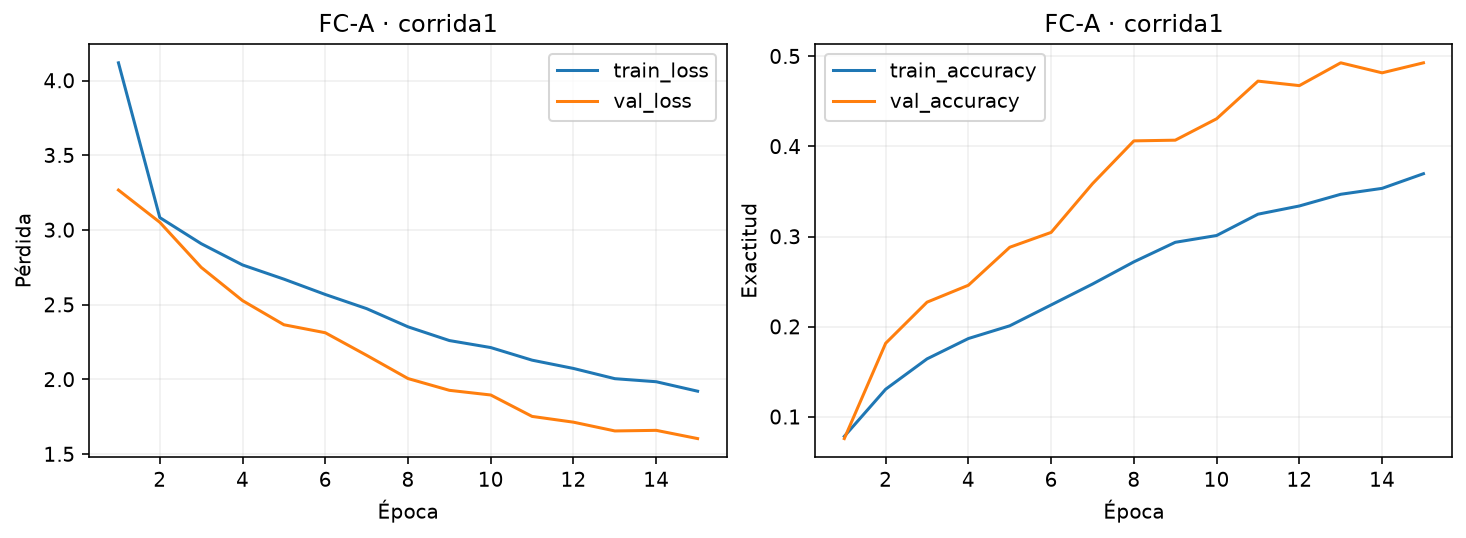

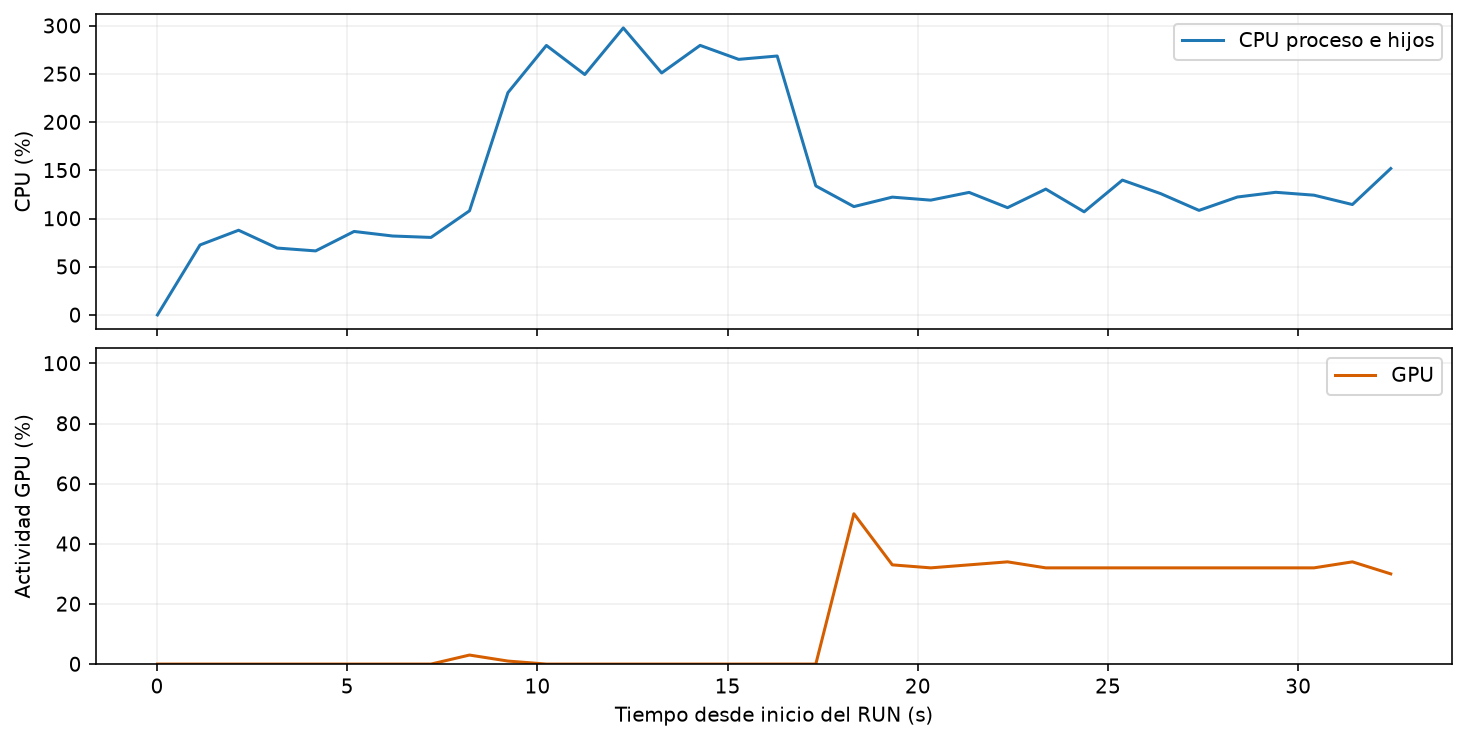

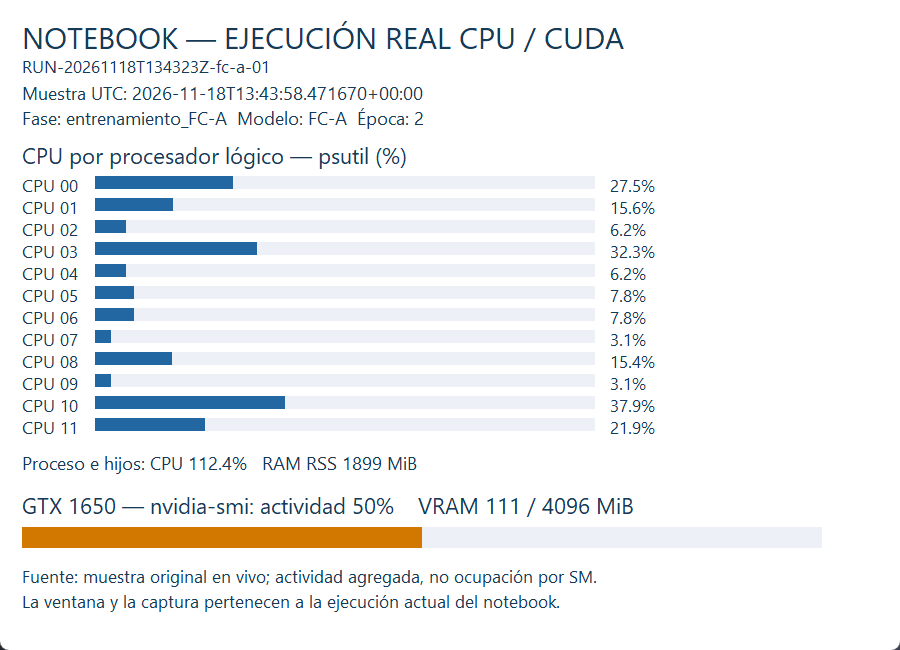

In [2]:
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(e.epoca,e[key],label=key)
    ax.set(xlabel='Época',ylabel=title,title='FC-A · corrida1');ax.legend();ax.grid(alpha=.2)
fig.savefig(dest/'curvas.png',dpi=160);fig.savefig(dest/'curvas.svg');mostrar_figura(fig)
r=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(r.transcurrido_s,r.cpu_procesos_pct,label='CPU proceso e hijos');axes[0].set(ylabel='CPU (%)')
axes[1].plot(r.transcurrido_s,r.gpu_util_pct,color='#D55E00',label='GPU');axes[1].set(xlabel='Tiempo desde inicio del RUN (s)',ylabel='Actividad GPU (%)',ylim=(0,105))
for ax in axes:ax.legend();ax.grid(alpha=.2)
fig.savefig(dest/'recursos.png',dpi=160);fig.savefig(dest/'recursos.svg');mostrar_figura(fig)
for image in run.glob('captura-*.png'):display(Image(filename=str(image)))

# Sesión nueva: las nueve corridas FC restantes

Los contadores reinician en1. El bootstrap verifica los datos y fuentes, y recupera la primera métrica guardada. Solo se entrenan las nueve repeticiones pendientes.

# Ampliación CUDA: FC-A y FC-B

Ejecución nueva y nativa, exclusiva de estas dos redes. Cinco corridas por arquitectura. Las campañas CPU y CNN-B anteriores **no se ejecutan**. Preparación y validación en CPU; entrenamiento matemático en CUDA Python/cuBLAS. Datos e inicialización históricos verificados. Los contadores pertenecen a esta sesión nueva, distinta del notebook CNN-B previo.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, time, csv, gc, subprocess
ROOT=Path.cwd()
while not (ROOT/'docs/Proyecto 3 CUDA.pdf').is_file():
    if ROOT==ROOT.parent: raise FileNotFoundError('Raíz del proyecto')
    ROOT=ROOT.parent
sys.path[:0]=[str(ROOT/'src'),str(ROOT/'scripts')]
for key,value in {'OMP_NUM_THREADS':'6','MKL_NUM_THREADS':'6','OPENBLAS_NUM_THREADS':'6',
    'TF_NUM_INTRAOP_THREADS':'6','TF_NUM_INTEROP_THREADS':'1','TF_DETERMINISTIC_OPS':'1',
    'TF_ENABLE_ONEDNN_OPTS':'1','NUMBA_CUDA_LOW_OCCUPANCY_WARNINGS':'0'}.items():os.environ[key]=value
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Image
from threadpoolctl import threadpool_limits
from benchmark_cpu import sha,write_json,write_csv,utc
from benchmark_cuda import load_manifest,load_images
from registro_notebook import iniciar_monitor,mostrar_figura
CONFIG=ROOT/'configuraciones/EXP-012.json'
config=json.loads(CONFIG.read_text(encoding='utf8'))
for relative,digest in config['codigo']['fuentes'].items():
    assert sha(ROOT/relative)==digest,relative
assert sha(ROOT/config['validacion']['ruta'])==config['validacion']['sha256']
assert json.loads((ROOT/config['validacion']['ruta']).read_text(encoding='utf8'))['estado']=='aprobado'
manifest=load_manifest(config)
data_root=Path(config['datos']['ruta'])
for split in manifest.values():
    for row in split:
        assert sha(data_root/row['ruta_relativa'])==row['sha256'],row['ruta_relativa']
limits=threadpool_limits(limits=6);limits.__enter__()
print('EXP-012 | SOLO FC-A / FC-B CUDA | CPU y CNN-B anteriores NO ejecutados')
print('Configuración SHA-256:',sha(CONFIG),'Python:',sys.executable)
print(json.dumps(config,indent=2,ensure_ascii=False))


EXP-012 | SOLO FC-A / FC-B CUDA | CPU y CNN-B anteriores NO ejecutados
Configuración SHA-256: 27d39f1099858c45a972f00ff99a7c6d1772fda80c36b99fa42c962c99c17497 Python: C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Scripts\python.exe
{
  "experimento_id": "EXP-012",
  "creado_utc": "2026-11-18T13:45:14.433962+00:00",
  "responsable": "Codex por instrucción del usuario",
  "decisiones": [
    "DEC-027"
  ],
  "cambios": [
    "CAM-012"
  ],
  "codigo": {
    "fuentes": {
      "scripts/preparar_experimento_fc_v3.py": "6695b5d08a21fed7d50161950ad01670886ee60148b8a96061841fad46b15ef7",
      "scripts/ejecutar_fc_notebook_v3.py": "744835b2d02c3120a921ad09aa85ec1d17511cf5b2b08edf0ac362c6d54456f8",
      "scripts/capturar_fc_real.py": "b076c03ed68e6d31ac12c26a85c1cd610bdf1422279d78a36bc9e6b09264ceae",
      "scripts/registro_notebook.py": "e3c86af1681993ccaf26da1568deac0ab9be5b4af4dcf9a6d5f6bbd1075ea9fd",
      "scripts/benchmark_cuda.py": "8165745290

## CUDA Python: código efectivamente definido en esta sesión

Se muestran las dependencias reutilizadas, sin instanciar ni entrenar CNN-B. El último módulo contiene la extensión FC y la corrección de momentum BN.

In [2]:
from IPython.core.magic import register_cell_magic
import types
@register_cell_magic
def modulo_fc(line,cell):
    name=line.strip();path=ROOT/'src'/Path(*name.split('.')).with_suffix('.py')
    module=types.ModuleType(name);module.__file__=str(path);module.__package__=name.rpartition('.')[0]
    sys.modules[name]=module
    exec(compile(cell,str(path),'exec'),module.__dict__)
    parent,_,attr=name.rpartition('.')
    if parent in sys.modules:setattr(sys.modules[parent],attr,module)
    print('Módulo CUDA Python definido:',name,'SHA-256',sha(path))
import asl_cuda


In [3]:
%%modulo_fc asl_cuda.runtime
"""Local toolkit discovery. Never installs packages or silently falls back to CPU."""
import os
from pathlib import Path

_DLL_HANDLES = []


def configure():
    if os.environ.get("NUMBA_ENABLE_CUDASIM", "0") != "0":
        raise RuntimeError("CUDA simulator is not a GPU benchmark.")
    if os.name == "nt":
        root = Path(os.environ.get("CUDA_HOME", "C:/Program Files/NVIDIA GPU Computing Toolkit/CUDA/v13.1"))
        os.environ.setdefault("CUDA_HOME", str(root))
        for folder in (root / "bin/x64", root / "bin", root / "nvvm/bin/x64", root / "nvvm/bin"):
            if folder.is_dir():
                _DLL_HANDLES.append(os.add_dll_directory(str(folder)))


configure()
# numba-cuda 0.30.4 still registers NumPy's retired row_stack alias at import.
# Preserve the installed NumPy 2.5.5: the alias is exactly vstack, not new math.
# Process-local compatibility only; no site-packages files are changed.
import numpy as np
if not hasattr(np, "row_stack"):
    np.row_stack = np.vstack
from numba import cuda  # noqa: E402


def device_info():
    if not cuda.is_available():
        raise RuntimeError("A real CUDA device is required.")
    d = cuda.get_current_device()
    free, total = cuda.current_context().get_memory_info()
    return dict(name=d.name.decode() if isinstance(d.name, bytes) else d.name,
                compute_capability=list(d.compute_capability), free_bytes=int(free), total_bytes=int(total),
                max_threads_per_block=int(d.MAX_THREADS_PER_BLOCK),
                max_shared_memory_per_block=int(d.MAX_SHARED_MEMORY_PER_BLOCK),
                simulator=False)


Módulo CUDA Python definido: asl_cuda.runtime SHA-256 90d0c6469d9e4ee15658375a5026307032068d875557d0084654b429889f97cb


In [4]:
%%modulo_fc asl_cuda.kernels
"""K01-K19, DIS-CUDA-001: FP32 NHWC, gather backward, explicit reductions.

Flat buffers have explicit active dimensions; capacity never defines batch size.
No floating point atomics or cross-block barriers. Partial gradients are unique.
"""
import math
from numba import float32
from .runtime import cuda


@cuda.jit(device=True, inline=True)
def _left(a, mode, m, k, H, W, Ci, Co, I, O):
    if mode == 0:  # virtual im2col
        n = m // (H * W)
        h = (m // W) % H + k // (3 * Ci) - 1
        w = m % W + (k // Ci) % 3 - 1
        if 0 <= h < H and 0 <= w < W:
            return a[((n * H + h) * W + w) * Ci + k % Ci]
        return float32(0)
    if mode == 1:  # gather dX, spatially reversed offsets
        n = m // (H * W)
        h = (m // W) % H - k // (3 * Co) + 1
        w = m % W - (k // Co) % 3 + 1
        if 0 <= h < H and 0 <= w < W:
            return a[((n * H + h) * W + w) * Co + k % Co]
        return float32(0)
    if mode == 2:  # im2col transpose without materializing it
        n = k // (H * W)
        h = (k // W) % H + m // (3 * Ci) - 1
        w = k % W + (m // Ci) % 3 - 1
        if 0 <= h < H and 0 <= w < W:
            return a[((n * H + h) * W + w) * Ci + m % Ci]
        return float32(0)
    if mode == 3:
        return a[m * I + k]
    if mode == 4:
        return a[m * O + k]
    return a[k * I + m]


@cuda.jit(device=True, inline=True)
def _right(v, mode, k, n, Ci, Co, I, O):
    if mode == 0 or mode == 2:
        return v[k * Co + n]
    if mode == 1:
        return v[((k // Co) * Ci + n) * Co + k % Co]
    if mode == 3 or mode == 5:
        return v[k * O + n]
    return v[n * O + k]


def _make_gemm(mode):
    @cuda.jit(cache=True, fastmath=False)
    def kernel(a, v, bias, out, M, N, K, H, W, Ci, Co, I, O, relu, m0):
        sa = cuda.shared.array((16, 16), float32)
        sb = cuda.shared.array((16, 16), float32)
        tx, ty = cuda.threadIdx.x, cuda.threadIdx.y
        m, n = m0 + cuda.blockIdx.y * 16 + ty, cuda.blockIdx.x * 16 + tx
        begin, end = 0, K
        if mode == 2 or mode == 5:
            begin = cuda.blockIdx.z * 2048
            end = min(K, begin + 2048)
        acc = float32(0)
        for k0 in range(begin, end, 16):
            sa[ty, tx] = float32(0)
            sb[ty, tx] = float32(0)
            if m < M and k0 + tx < end:
                sa[ty, tx] = _left(a, mode, m, k0 + tx, H, W, Ci, Co, I, O)
            if n < N and k0 + ty < end:
                sb[ty, tx] = _right(v, mode, k0 + ty, n, Ci, Co, I, O)
            cuda.syncthreads()
            for kk in range(16):
                acc += sa[ty, kk] * sb[kk, tx]
            cuda.syncthreads()
        if m < M and n < N:
            index = m * N + n
            if mode == 2 or mode == 5:
                index += cuda.blockIdx.z * M * N
            if mode == 0 or mode == 3:
                acc += bias[n]
                if relu and acc < 0:
                    acc = float32(0)
            out[index] = acc
    return kernel


GEMM = tuple(_make_gemm(i) for i in range(6))


@cuda.jit(cache=True)
def merge_partials(parts, out, E, P):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        value = float32(0)
        for p in range(P):
            value += parts[p * E + i]
        out[i] = value


@cuda.jit(cache=True)
def copy_flat(x, y, E):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        y[i] = x[i]


@cuda.jit(cache=True)
def relu_backward(grad, activation, E):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        if activation[i] <= 0:
            grad[i] = float32(0)


@cuda.jit(cache=True)
def dropout(x, mask, out, factor, E):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        out[i] = x[i] * float32(mask[i]) * factor


@cuda.jit(cache=True)
def pool_forward(x, y, arg, b, H, W, C):
    E = b * (H // 2) * (W // 2) * C
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        c = i % C
        w = (i // C) % (W // 2)
        h = (i // (C * (W // 2))) % (H // 2)
        n = i // (C * (W // 2) * (H // 2))
        base = ((n * H + 2 * h) * W + 2 * w) * C + c
        value, pos = x[base], 0
        for p in range(1, 4):
            candidate = x[base + (p // 2) * W * C + (p % 2) * C]
            if candidate > value:
                value, pos = candidate, p
        y[i], arg[i] = value, pos


@cuda.jit(cache=True)
def pool_backward(dy, arg, dx, b, H, W, C):
    for i in range(cuda.grid(1), b * H * W * C, cuda.gridsize(1)):
        c, w = i % C, (i // C) % W
        h, n = (i // (C * W)) % H, i // (C * W * H)
        out_i = ((n * (H // 2) + h // 2) * (W // 2) + w // 2) * C + c
        dx[i] = float32(0)
        if arg[out_i] == 2 * (h % 2) + w % 2:
            dx[i] = dy[out_i]


@cuda.jit(cache=True, fastmath=False)
def reduce_channels(x, dy, mean, inv, parts1, parts2, L, C, mode):
    # mode0 sum; mode1 centered variance; mode2 BN backward pair.
    s1 = cuda.shared.array((8, 32), float32)
    s2 = cuda.shared.array((8, 32), float32)
    tx, ty = cuda.threadIdx.x, cuda.threadIdx.y
    c = cuda.blockIdx.y * 32 + tx
    v1, v2 = float32(0), float32(0)
    if c < C:
        for j in range(256):
            l = cuda.blockIdx.x * 2048 + ty + 8 * j
            if l < L:
                value = x[l * C + c]
                if mode == 0:
                    v1 += value
                elif mode == 1:
                    centered = value - mean[c]
                    v1 += centered * centered
                else:
                    g = dy[l * C + c]
                    v1 += g
                    v2 += g * ((value - mean[c]) * inv[c])
    s1[ty, tx], s2[ty, tx] = v1, v2
    cuda.syncthreads()
    stride = 4
    while stride > 0:
        if ty < stride:
            s1[ty, tx] += s1[ty + stride, tx]
            s2[ty, tx] += s2[ty + stride, tx]
        cuda.syncthreads()
        stride //= 2
    if ty == 0 and c < C:
        parts1[cuda.blockIdx.x * C + c] = s1[0, tx]
        parts2[cuda.blockIdx.x * C + c] = s2[0, tx]


@cuda.jit(cache=True, fastmath=False)
def finish_channels(p1, p2, out1, out2, movmean, movvar, mean, inv, P, C, L, mode):
    # mode0 mean; mode1 variance+moving state; mode2 dbeta/dgamma; mode3 bias.
    s1 = cuda.shared.array(256, float32)
    s2 = cuda.shared.array(256, float32)
    t, c = cuda.threadIdx.x, cuda.blockIdx.x
    s1[t], s2[t] = float32(0), float32(0)
    if t < P:
        s1[t], s2[t] = p1[t * C + c], p2[t * C + c]
    cuda.syncthreads()
    stride = 128
    while stride > 0:
        if t < stride:
            s1[t] += s1[t + stride]
            s2[t] += s2[t + stride]
        cuda.syncthreads()
        stride //= 2
    if t == 0:
        if mode == 0:
            out1[c] = s1[0] / float32(L)
        elif mode == 1:
            var = s1[0] / float32(L)
            inv[c] = float32(1) / math.sqrt(var + float32(.001))
            movmean[c] = float32(.9) * movmean[c] + float32(.1) * mean[c]
            movvar[c] = float32(.9) * movvar[c] + float32(.1) * var
        elif mode == 2:
            out1[c], out2[c] = s1[0], s2[0]
        else:
            out1[c] = s1[0]


@cuda.jit(cache=True, fastmath=False)
def bn_forward(x, y, gamma, beta, mean, inv, E, C):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        c = i % C
        y[i] = gamma[c] * ((x[i] - mean[c]) * inv[c]) + beta[c]


@cuda.jit(cache=True, fastmath=False)
def bn_backward(x, dy, dx, gamma, mean, inv, dbeta, dgamma, L, C):
    for i in range(cuda.grid(1), L * C, cuda.gridsize(1)):
        c = i % C
        xhat = (x[i] - mean[c]) * inv[c]
        dx[i] = (gamma[c] * inv[c] / float32(L)) * (
            float32(L) * dy[i] - dbeta[c] - xhat * dgamma[c])


@cuda.jit(cache=True, fastmath=False)
def softmax_loss(logits, labels, probs, dlogits, loss, correct, b):
    s = cuda.shared.array(32, float32)
    t, n = cuda.threadIdx.x, cuda.blockIdx.x
    z = float32(-math.inf)
    if t < 29:
        z = logits[n * 29 + t]
    s[t] = z
    cuda.syncthreads()
    stride = 16
    while stride > 0:
        if t < stride:
            s[t] = max(s[t], s[t + stride])
        cuda.syncthreads()
        stride //= 2
    maximum = s[0]
    cuda.syncthreads()
    value = float32(0)
    if t < 29:
        value = math.exp(z - maximum)
    s[t] = value
    cuda.syncthreads()
    stride = 16
    while stride > 0:
        if t < stride:
            s[t] += s[t + stride]
        cuda.syncthreads()
        stride //= 2
    denominator = s[0]
    label = labels[n]
    if t < 29:
        probability = value / denominator
        probs[n * 29 + t] = probability
        dlogits[n * 29 + t] = (probability - float32(t == label)) / float32(b)
    if t == 0:
        loss[n] = (maximum - logits[n * 29 + label]) + math.log(denominator)
        winner = 0
        for c in range(1, 29):
            if logits[n * 29 + c] > logits[n * 29 + winner]:
                winner = c
        correct[n] = winner == label


@cuda.jit(cache=True, fastmath=False)
def adam(theta, grad, moment, velocity, alpha, E, error):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        g = grad[i]
        if not math.isfinite(g):
            cuda.atomic.max(error, 0, 1)
        if error[0] == 0:
            m = moment[i] + (g - moment[i]) * float32(.1)
            v = velocity[i] + (g * g - velocity[i]) * float32(.001)
            value = theta[i] - (m * alpha) / (math.sqrt(v) + float32(1e-7))
            if not math.isfinite(value):
                cuda.atomic.max(error, 0, 2)
            theta[i], moment[i], velocity[i] = value, m, v


@cuda.jit(cache=True)
def finite_check(x, E, error):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        if not math.isfinite(x[i]):
            cuda.atomic.max(error, 0, 3)


@cuda.jit(cache=True)
def metrics(loss, correct, b, total):
    s = cuda.shared.array(256, float32)
    q = cuda.shared.array(256, float32)
    t = cuda.threadIdx.x
    s[t], q[t] = float32(0), float32(0)
    if t < b:
        s[t], q[t] = loss[t], float32(correct[t])
    cuda.syncthreads()
    stride = 128
    while stride > 0:
        if t < stride:
            s[t] += s[t + stride]
            q[t] += q[t + stride]
        cuda.syncthreads()
        stride //= 2
    if t == 0:
        total[0] += s[0]
        total[1] += q[0]
        total[2] += float32(b)


@cuda.jit(cache=True)
def advance_step(counter):
    if cuda.grid(1) == 0:
        counter[0] += 1


@cuda.jit(cache=True)
def im2col(x, cols, R, H, W, Ci):
    K = 9 * Ci
    for i in range(cuda.grid(1), R * K, cuda.gridsize(1)):
        r, kk = i // K, i % K
        n = r // (H * W)
        h = (r // W) % H + kk // (3 * Ci) - 1
        w = r % W + (kk // Ci) % 3 - 1
        value = float32(0)
        if 0 <= h < H and 0 <= w < W:
            value = x[((n * H + h) * W + w) * Ci + kk % Ci]
        cols[i] = value


@cuda.jit(cache=True)
def col2im_gather(cols, dx, R, H, W, Ci):
    for i in range(cuda.grid(1), R * Ci, cuda.gridsize(1)):
        c = i % Ci
        w, h = (i // Ci) % W, (i // (Ci * W)) % H
        n = i // (Ci * W * H)
        value = float32(0)
        for kh in range(3):
            for kw in range(3):
                ho, wo = h - kh + 1, w - kw + 1
                if 0 <= ho < H and 0 <= wo < W:
                    row = (n * H + ho) * W + wo
                    value += cols[row * 9 * Ci + (kh * 3 + kw) * Ci + c]
        dx[i] = value


@cuda.jit(cache=True)
def bias_activation(y, bias, E, C, relu):
    for i in range(cuda.grid(1), E, cuda.gridsize(1)):
        value = y[i] + bias[i % C]
        if relu and value < 0:
            value = float32(0)
        y[i] = value


Módulo CUDA Python definido: asl_cuda.kernels SHA-256 3dc55a51bc4e2ece39c279ecf9d60956c06d4700a03603c44dda23f6dd100fec


In [5]:
%%modulo_fc asl_cuda.blas
"""FP32 cuBLAS SGEMM on Numba-owned device memory and the SAME CUDA stream.

The installed NVIDIA CUDA toolkit supplies the DLL. No tensor cores, no TF32,
no NumPy/CPU multiplication. Geometry inside cuBLAS belongs to NVIDIA's backend.
"""
import ctypes as ct
import os
from pathlib import Path


class Blas:
    def __init__(self, stream):
        root = Path(os.environ["CUDA_HOME"])
        self.path = root / "bin/x64/cublas64_13.dll"
        self.dll = ct.WinDLL(str(self.path))
        self.handle = ct.c_void_p()
        self._signature("cublasCreate_v2", [ct.POINTER(ct.c_void_p)])
        self._signature("cublasSetStream_v2", [ct.c_void_p, ct.c_void_p])
        self._signature("cublasSetMathMode", [ct.c_void_p, ct.c_int])
        self._signature("cublasSetAtomicsMode", [ct.c_void_p, ct.c_int])
        self._signature("cublasGetVersion_v2", [ct.c_void_p, ct.POINTER(ct.c_int)])
        self._signature("cublasDestroy_v2", [ct.c_void_p])
        self._signature("cublasSgemm_v2", [ct.c_void_p, ct.c_int, ct.c_int,
            ct.c_int, ct.c_int, ct.c_int, ct.POINTER(ct.c_float), ct.c_void_p, ct.c_int,
            ct.c_void_p, ct.c_int, ct.POINTER(ct.c_float), ct.c_void_p, ct.c_int])
        self._call("cublasCreate_v2", ct.byref(self.handle))
        raw = stream.handle
        self._call("cublasSetStream_v2", self.handle, ct.c_void_p(raw.value if hasattr(raw, "value") else int(raw)))
        self._call("cublasSetMathMode", self.handle, 2)  # CUBLAS_PEDANTIC_MATH
        self._call("cublasSetAtomicsMode", self.handle, 0)  # CUBLAS_ATOMICS_NOT_ALLOWED
        version = ct.c_int()
        self._call("cublasGetVersion_v2", self.handle, ct.byref(version))
        self.version = version.value

    def _signature(self, name, args):
        fn = getattr(self.dll, name)
        fn.argtypes, fn.restype = args, ct.c_int

    def _call(self, name, *args):
        status = getattr(self.dll, name)(*args)
        if status:
            raise RuntimeError(f"{name}: cuBLAS status {status}")

    @staticmethod
    def ptr(array):
        return ct.c_void_p(array.device_ctypes_pointer.value)

    def gemm(self, a, b, out, M, N, K, transpose_a=False, transpose_b=False):
        """C_row=op(A)_row @ op(B)_row, implemented as C_col=B_col @ A_col."""
        alpha, beta = ct.c_float(1.), ct.c_float(0.)
        self._call("cublasSgemm_v2", self.handle, int(transpose_b), int(transpose_a),
                   N, M, K, ct.byref(alpha), self.ptr(b), K if transpose_b else N,
                   self.ptr(a), M if transpose_a else K, ct.byref(beta), self.ptr(out), N)

    def close(self):
        if self.handle:
            self._call("cublasDestroy_v2", self.handle)
            self.handle = ct.c_void_p()


Módulo CUDA Python definido: asl_cuda.blas SHA-256 1ba799e3cb2d8856e3b7bd408ca2d8f6cd6cb840a0e326916c40f3bc021024b8


In [6]:
%%modulo_fc asl_cuda.model
"""Complete CNN-B training on explicitly launched CUDA Python kernels.

TensorFlow is used only as a CPU oracle and for CPU validation/checkpoint I/O.
The original network and its initial state are imported without editing them.
"""
from contextlib import contextmanager
from pathlib import Path
import hashlib
import json
import time
import numpy as np
from .runtime import cuda, device_info
from . import kernels as k

ROOT = Path(__file__).resolve().parents[2]
INITIAL = ROOT / "data/EXP-002/RUN-20261117T171942Z-cpu-01/CNN-B.estado-inicial.npz"
INITIAL_SHA = "10558d723213752b759626c3b196665f2547a0b65cbce296e47b3a4f992305fd"


def cpu_reference():
    """Build original definitions, confirm CPU placement and restore ALL 80 arrays."""
    import os
    for name, value in {"TF_NUM_INTRAOP_THREADS":"6", "TF_NUM_INTEROP_THREADS":"1",
                        "OMP_NUM_THREADS":"6", "OPENBLAS_NUM_THREADS":"6",
                        "MKL_NUM_THREADS":"6", "TF_DETERMINISTIC_OPS":"1",
                        "TF_ENABLE_ONEDNN_OPTS":"1"}.items():
        os.environ[name] = value
    import tensorflow as tf
    tf.config.set_visible_devices([], "GPU")
    tf.config.threading.set_intra_op_parallelism_threads(6)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    tf.keras.utils.set_random_seed(43)
    tf.keras.mixed_precision.set_global_policy("float32")
    import sys
    sys.path.insert(0, str(ROOT / "scripts"))
    from benchmark_cpu import original_namespace
    ns = original_namespace()
    ns.update(keras=tf.keras, layers=tf.keras.layers, NUM_CLASSES=29)
    model = ns["build_cnn_b"]()
    model.jit_compile = False
    model.optimizer.build(model.trainable_variables)
    if hashlib.sha256(INITIAL.read_bytes()).hexdigest() != INITIAL_SHA:
        raise ValueError("Initial checkpoint identity changed")
    with np.load(INITIAL, allow_pickle=False) as archive:
        variables = list(model.variables) + list(model.optimizer.variables)
        if len(variables) != len(archive.files):
            raise ValueError("Initial state variable count differs")
        for index, variable in enumerate(variables):
            value = archive[f"arr_{index}"]
            if tuple(variable.shape) != value.shape or str(variable.dtype) != str(value.dtype):
                raise ValueError(f"Incompatible state variable {index}")
            variable.assign(value)
    if int(model.optimizer.iterations.numpy()) != 0:
        raise ValueError("Expected optimizer iteration zero")
    if any(np.any(v.numpy()) for v in [*model.optimizer._momentums, *model.optimizer._velocities]):
        raise ValueError("Nonzero initial Adam requires explicit state mapping")
    return tf, model


def grid(E):
    return max(1, min(4096, (int(E) + 255) // 256))


def compiled_resources():
    """Numba-CUDA 0.30 API expects signature objects, not .signatures tuples."""
    result={}
    for name,kern in vars(k).items():
        if hasattr(kern,"get_regs_per_thread") and kern.signatures:
            regs=kern.get_regs_per_thread()
            shared=kern.get_shared_mem_per_block()
            local=kern.get_local_mem_per_thread()
            result[name]=[dict(firma=str(sig),registros=value,shared_bytes=shared[sig],local_bytes=local[sig])
                          for sig,value in regs.items()]
    return result


class Network:
    def __init__(self, reference, backend="explicit"):
        self.info = device_info()
        if self.info["free_bytes"] < 1536 * 2**20:
            raise MemoryError("Insufficient free VRAM for the frozen profile")
        self.stream = cuda.stream()
        if backend not in ("explicit", "cublas"):
            raise ValueError("Unknown backend")
        self.backend = backend
        self.allocations, self.params, self.ops, self.transfers = [], [], [], []
        self.reference = reference
        self.input = self.alloc(128 * 64 * 64 * 3)
        self.host_x = cuda.pinned_array(128 * 64 * 64 * 3, dtype=np.float32)
        self.labels = self.alloc(128, np.int64)
        self.host_y = cuda.pinned_array(128, dtype=np.int64)
        shape, previous = (64, 64, 3), self.input
        for layer in reference.layers:
            name = type(layer).__name__
            item = dict(input=previous, shape=shape, layer=layer)
            if name == "Conv2D":
                H, W, Ci = shape
                Co = layer.filters
                item.update(kind="conv", H=H, W=W, Ci=Ci, Co=Co,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias), relu=True)
                shape = (H, W, Co)
            elif name == "Dense":
                I, O = int(layer.kernel.shape[0]), int(layer.kernel.shape[1])
                item.update(kind="dense", I=I, O=O, relu=O != 29,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias))
                shape = (O,)
            elif name == "BatchNormalization":
                C = shape[-1]
                item.update(kind="bn", C=C, gamma=self.param(layer.gamma), beta=self.param(layer.beta),
                            moving_mean=self.alloc(C), moving_var=self.alloc(C),
                            initial_mean=layer.moving_mean.numpy().copy(), initial_var=layer.moving_variance.numpy().copy(),
                            mean=self.alloc(C), inv=self.alloc(C))
            elif name == "MaxPooling2D":
                H, W, C = shape
                item.update(kind="pool", H=H, W=W, C=C)
                shape = (H // 2, W // 2, C)
                item["arg"] = self.alloc(128 * int(np.prod(shape)), np.uint8)
            elif name == "Dropout":
                E = 128 * int(np.prod(shape))
                item.update(kind="drop", p=layer.rate, mask=self.alloc(E, np.uint8),
                            host_mask=cuda.pinned_array(E, dtype=np.uint8))
            elif name == "Flatten":
                shape = (int(np.prod(shape)),)
                continue
            elif name == "InputLayer":
                continue
            else:
                raise TypeError(f"Unsupported original layer {name}")
            item["sample_elements"] = int(np.prod(shape))
            item["output"] = self.alloc(128 * item["sample_elements"])
            self.ops.append(item)
            previous = item["output"]
        self.probs = self.alloc(128 * 29)
        self.loss, self.correct = self.alloc(128), self.alloc(128, np.uint8)
        self.g1, self.g2 = self.alloc(128 * 64 * 64 * 32), self.alloc(128 * 64 * 64 * 32)
        self.parts = self.alloc(16 * 2**20 // 4)
        self.p1, self.p2 = self.alloc(65536), self.alloc(65536)
        self.dummy = self.alloc(256)
        self.total = self.alloc(3)
        self.error = self.alloc(1, np.int32)
        self.counter = self.alloc(1, np.int64)
        self.host_error = cuda.pinned_array(1, dtype=np.int32)
        self.host_total = cuda.pinned_array(3, dtype=np.float32)
        if backend == "cublas":
            from .blas import Blas
            self.blas = Blas(self.stream)
            self.columns = self.alloc(128 * 64 * 64 * (9 * 32))
        self.bytes_allocated = sum(a.nbytes for a in self.allocations)
        if self.bytes_allocated > (1408 if backend == "cublas" else 768) * 2**20:
            raise MemoryError(f"Arena exceeds design: {self.bytes_allocated}")
        if sum(p["value"].size for p in self.params) != 2245245:
            raise ValueError("Architecture parameter count changed")
        self.events = []
        self.restore()

    def alloc(self, count, dtype=np.float32):
        array = cuda.device_array(int(count), dtype=dtype, stream=self.stream)
        self.allocations.append(array)
        return array

    def param(self, variable):
        values = variable.numpy().copy()
        p = dict(initial=values, value=self.alloc(values.size), grad=self.alloc(values.size),
                 m=self.alloc(values.size), v=self.alloc(values.size), variable=variable)
        self.params.append(p)
        return p

    def restore(self):
        for p in self.params:
            p["value"].copy_to_device(p["initial"].ravel(), stream=self.stream)
            for state in ("m", "v"):
                p[state].copy_to_device(np.zeros(p["initial"].size, np.float32), stream=self.stream)
        for op in self.ops:
            if op["kind"] == "bn":
                op["moving_mean"].copy_to_device(op["initial_mean"], stream=self.stream)
                op["moving_var"].copy_to_device(op["initial_var"], stream=self.stream)
        for a in (self.error, self.counter, self.total):
            a.copy_to_device(np.zeros(a.size, dtype=a.dtype), stream=self.stream)
        self.stream.synchronize()
        self.steps = 0
        self.events = []

    @contextmanager
    def timed(self, phase):
        start, end = cuda.event(timing=True), cuda.event(timing=True)
        start.record(self.stream)
        yield
        end.record(self.stream)
        self.events.append((phase, start, end))

    def drain_events(self):
        self.stream.synchronize()
        result = {}
        for phase, start, end in self.events:
            result[phase] = result.get(phase, 0.) + cuda.event_elapsed_time(start, end) / 1000.
        self.events.clear()
        return result

    def gemm(self, mode, a, v, bias, out, M, N, K, H=1, W=1, Ci=1, Co=1, I=1, O=1, relu=False):
        if self.backend == "cublas":
            if mode in (0, 2):
                R = M if mode == 0 else K
                width = 9 * Ci
                k.im2col[grid(R * width), 256, self.stream](a, self.columns, R, H, W, Ci)
                self.blas.gemm(self.columns, v, out, M, N, K, transpose_a=mode == 2)
            elif mode == 1:
                self.blas.gemm(a, v, self.columns, M, 9 * Ci, Co, transpose_b=True)
                k.col2im_gather[grid(M * Ci), 256, self.stream](self.columns, out, M, H, W, Ci)
            else:
                self.blas.gemm(a, v, out, M, N, K, transpose_a=mode == 5, transpose_b=mode == 4)
            if mode in (0, 3):
                k.bias_activation[grid(M * N), 256, self.stream](out, bias, M * N, N, relu)
            return
        P = (K + 2047) // 2048 if mode in (2, 5) else 1
        if mode in (2, 5) and P * M * N > self.parts.size:
            raise MemoryError("Partial gradient workspace exhausted")
        for m0 in range(0, M, 16384):
            geom = ((N + 15) // 16, (min(16384, M - m0) + 15) // 16, P)
            k.GEMM[mode][geom, (16, 16), self.stream](
                a, v, bias, out, M, N, K, H, W, Ci, Co, I, O, relu, m0)

    def reduce(self, x, dy, op, L, C, mode, out1, out2):
        P = (L + 2047) // 2048
        if P > 256 or P * C > self.p1.size:
            raise ValueError("Reduction shape exceeds frozen profile")
        mean, inv = op.get("mean", self.dummy), op.get("inv", self.dummy)
        k.reduce_channels[(P, (C + 31) // 32), (32, 8), self.stream](
            x, dy, mean, inv, self.p1, self.p2, L, C, 2 if mode == 2 else (1 if mode == 1 else 0))
        k.finish_channels[C, 256, self.stream](self.p1, self.p2, out1, out2,
            op.get("moving_mean", self.dummy), op.get("moving_var", self.dummy),
            mean, inv, P, C, L, mode)

    def upload(self, x, labels, epoch, batch_index):
        b = len(x)
        np.copyto(self.host_x[:x.size], x.ravel())
        np.copyto(self.host_y[:b], labels)
        drops = [op for op in self.ops if op["kind"] == "drop"]
        for d, op in enumerate(drops):
            E = b * op["sample_elements"]
            rng = np.random.Generator(np.random.PCG64(np.random.SeedSequence([43, epoch, batch_index, d + 1])))
            op["host_mask"][:E] = rng.random(E, dtype=np.float32) >= np.float32(op["p"])
        with self.timed("h2d_lotes"):
            self.input[:x.size].copy_to_device(self.host_x[:x.size], stream=self.stream)
            self.labels[:b].copy_to_device(self.host_y[:b], stream=self.stream)
            for op in drops:
                E = b * op["sample_elements"]
                op["mask"][:E].copy_to_device(op["host_mask"][:E], stream=self.stream)
        self.transfers.append(dict(batch=b, imagenes_bytes=x.nbytes, etiquetas_bytes=labels.nbytes,
                                   mascaras_bytes=sum(b * op["sample_elements"] for op in drops)))

    def forward(self, b):
        for op in self.ops:
            kind, x, y, E = op["kind"], op["input"], op["output"], b * op["sample_elements"]
            if kind == "conv":
                H, W, Ci, Co = (op[z] for z in ("H", "W", "Ci", "Co"))
                self.gemm(0, x, op["weights"]["value"], op["bias"]["value"], y,
                          b * H * W, Co, 9 * Ci, H, W, Ci, Co, relu=True)
            elif kind == "dense":
                self.gemm(3, x, op["weights"]["value"], op["bias"]["value"], y,
                          b, op["O"], op["I"], I=op["I"], O=op["O"], relu=op["relu"])
            elif kind == "bn":
                C, L = op["C"], E // op["C"]
                self.reduce(x, self.dummy, op, L, C, 0, op["mean"], self.dummy)
                self.reduce(x, self.dummy, op, L, C, 1, self.dummy, self.dummy)
                k.bn_forward[grid(E), 256, self.stream](x, y, op["gamma"]["value"],
                    op["beta"]["value"], op["mean"], op["inv"], E, C)
            elif kind == "pool":
                k.pool_forward[grid(E), 256, self.stream](x, y, op["arg"], b, op["H"], op["W"], op["C"])
            else:
                k.dropout[grid(E), 256, self.stream](x, op["mask"], y, np.float32(1 / (1 - op["p"])), E)
            k.finite_check[grid(E), 256, self.stream](y, E, self.error)
        k.softmax_loss[b, 32, self.stream](self.ops[-1]["output"], self.labels,
            self.probs, self.g1, self.loss, self.correct, b)
        k.finite_check[grid(b), 256, self.stream](self.loss, b, self.error)

    def backward(self, b, audit_hook=None):
        current, other = self.g1, self.g2
        for index in range(len(self.ops) - 1, -1, -1):
            op = self.ops[index]
            kind, x = op["kind"], op["input"]
            E = b * op["sample_elements"]
            if kind in ("conv", "dense"):
                if op["relu"]:
                    k.relu_backward[grid(E), 256, self.stream](current, op["output"], E)
                if kind == "conv":
                    H, W, Ci, Co = (op[z] for z in ("H", "W", "Ci", "Co"))
                    L = b * H * W
                    target = op["weights"]["grad"] if self.backend == "cublas" else self.parts
                    self.gemm(2, x, current, self.dummy, target, 9 * Ci, Co, L, H, W, Ci, Co)
                    if self.backend == "explicit":
                        k.merge_partials[grid(9 * Ci * Co), 256, self.stream](self.parts,
                            op["weights"]["grad"], 9 * Ci * Co, (L + 2047) // 2048)
                    if index:
                        self.gemm(1, current, op["weights"]["value"], self.dummy, other,
                                  L, Ci, 9 * Co, H, W, Ci, Co)
                    C = Co
                else:
                    I, O, L, C = op["I"], op["O"], b, op["O"]
                    target = op["weights"]["grad"] if self.backend == "cublas" else self.parts
                    self.gemm(5, x, current, self.dummy, target, I, O, b, I=I, O=O)
                    if self.backend == "explicit":
                        k.merge_partials[grid(I * O), 256, self.stream](self.parts, op["weights"]["grad"], I * O, 1)
                    self.gemm(4, current, op["weights"]["value"], self.dummy, other, b, I, O, I=I, O=O)
                self.reduce(current, self.dummy, {}, L, C, 3, op["bias"]["grad"], self.dummy)
            elif kind == "bn":
                C, L = op["C"], E // op["C"]
                self.reduce(x, current, op, L, C, 2, op["beta"]["grad"], op["gamma"]["grad"])
                k.bn_backward[grid(E), 256, self.stream](x, current, other, op["gamma"]["value"],
                    op["mean"], op["inv"], op["beta"]["grad"], op["gamma"]["grad"], L, C)
            elif kind == "pool":
                E_in = b * op["H"] * op["W"] * op["C"]
                k.pool_backward[grid(E_in), 256, self.stream](current, op["arg"], other,
                    b, op["H"], op["W"], op["C"])
            else:
                k.dropout[grid(E), 256, self.stream](current, op["mask"], other,
                    np.float32(1 / (1 - op["p"])), E)
            if audit_hook is not None:
                self.stream.synchronize()
                audit_hook(index, op, current, other)
            current, other = other, current

    def update(self, b):
        t = np.float32(self.steps + 1)
        alpha = np.float32(.001) * np.sqrt(np.float32(1) - np.float32(.999)**t) / (
            np.float32(1) - np.float32(.9)**t)
        for p in self.params:
            k.adam[grid(p["value"].size), 256, self.stream](p["value"], p["grad"],
                p["m"], p["v"], np.float32(alpha), p["value"].size, self.error)
        k.metrics[1, 256, self.stream](self.loss, self.correct, b, self.total)
        k.advance_step[1, 1, self.stream](self.counter)
        self.steps += 1

    def train_step(self, x, labels, epoch=0, batch_index=0):
        self.upload(x, labels, epoch, batch_index)
        with self.timed("forward_loss"):
            self.forward(len(x))
        with self.timed("backward"):
            self.backward(len(x))
        with self.timed("adam_metricas"):
            self.update(len(x))
        with self.timed("d2h_control"):
            self.error.copy_to_host(self.host_error, stream=self.stream)
        times = self.drain_events()
        if self.host_error[0]:
            raise FloatingPointError(f"CUDA sticky error {self.host_error[0]}, step {self.steps}")
        return times

    def reset_metrics(self):
        self.total.copy_to_device(np.zeros(3, np.float32), stream=self.stream)

    def export(self, optimizer=False):
        """D2H model state, then install CPU mirror outside the transfer interval."""
        host = []
        with self.timed("d2h_modelo"):
            for p in self.params:
                host.append((p["variable"], p["value"].copy_to_host(stream=self.stream).reshape(p["initial"].shape)))
            for op in self.ops:
                if op["kind"] == "bn":
                    host.append((op["layer"].moving_mean, op["moving_mean"].copy_to_host(stream=self.stream)))
                    host.append((op["layer"].moving_variance, op["moving_var"].copy_to_host(stream=self.stream)))
            self.total.copy_to_host(self.host_total, stream=self.stream)
        times = self.drain_events()
        for variable, value in host:
            variable.assign(value)
        if optimizer:
            with self.timed("d2h_optimizador"):
                states = [(p["m"].copy_to_host(stream=self.stream), p["v"].copy_to_host(stream=self.stream)) for p in self.params]
                count = self.counter.copy_to_host(stream=self.stream)
            extra = self.drain_events()
            times.update(extra)
            if int(count[0]) != self.steps:
                raise ValueError("Device update counter differs")
            self.reference.optimizer.iterations.assign(int(count[0]))
            for i, (moment, velocity) in enumerate(states):
                self.reference.optimizer._momentums[i].assign(moment.reshape(self.params[i]["initial"].shape))
                self.reference.optimizer._velocities[i].assign(velocity.reshape(self.params[i]["initial"].shape))
        return times, self.host_total.copy()


Módulo CUDA Python definido: asl_cuda.model SHA-256 9c474d9d20212177f44d1dafb26eef6427a70e89f60118d2b819d5f47a80a156


In [7]:
%%modulo_fc asl_cuda.fc
"""FC-A/FC-B CUDA extension. Frozen CNN-B code is reused, never edited.

All arithmetic training executes through explicit Numba CUDA launches and
cuBLAS FP32 SGEMM. CPU is restricted to preparation, validation and checkpoint I/O.
The BN finishing reduction uses one thread per input feature (12,288 features),
with momentum taken from the original FC layer, rather than CNN-B's 0.9.
"""
import hashlib
import json
import os
import sys
import numpy as np
from pathlib import Path
from .runtime import cuda, device_info
from .model import Network, grid, ROOT
from . import kernels as k
from numba import float32


@cuda.jit(cache=True, fastmath=False)
def finish_fc(p1,p2,out1,out2,movmean,movvar,mean,inv,P,C,L,mode,momentum):
    for c in range(cuda.grid(1),C,cuda.gridsize(1)):
        a,b=float32(0),float32(0)
        for p in range(P):
            a+=p1[p*C+c]
            b+=p2[p*C+c]
        if mode==0:
            out1[c]=a/float32(L)
        elif mode==1:
            var=a/float32(L)
            inv[c]=float32(1)/(var+float32(.001))**float32(.5)
            complement=float32(1)-momentum
            movmean[c]=momentum*movmean[c]+complement*mean[c]
            movvar[c]=momentum*movvar[c]+complement*var
        elif mode==2:
            out1[c],out2[c]=a,b
        else:
            out1[c]=a


def fc_reference(name):
    """Restore historical architecture, ALL variables and zero Adam state."""
    if name not in ('FC-A','FC-B'):raise ValueError(name)
    for key,value in {'TF_NUM_INTRAOP_THREADS':'6','TF_NUM_INTEROP_THREADS':'1',
        'OMP_NUM_THREADS':'6','OPENBLAS_NUM_THREADS':'6','MKL_NUM_THREADS':'6',
        'TF_DETERMINISTIC_OPS':'1','TF_ENABLE_ONEDNN_OPTS':'1'}.items():os.environ[key]=value
    import tensorflow as tf
    tf.config.set_visible_devices([], 'GPU')
    tf.config.threading.set_intra_op_parallelism_threads(6)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    tf.keras.mixed_precision.set_global_policy('float32')
    seed=44 if name=='FC-A' else 45
    tf.keras.utils.set_random_seed(seed)
    sys.path.insert(0,str(ROOT/'scripts'))
    from benchmark_cpu import original_namespace
    ns=original_namespace();ns.update(keras=tf.keras,layers=tf.keras.layers,NUM_CLASSES=29)
    model=ns['build_fc']([128,64] if name=='FC-A' else [512,256,128],
        dropout=.3 if name=='FC-A' else .4,name=name)
    model.jit_compile=False
    model.optimizer.build(model.trainable_variables)
    initial=ROOT/'data/EXP-002/RUN-20261117T171942Z-cpu-01'/f'{name}.estado-inicial.npz'
    index=json.loads((ROOT/'resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/estados-iniciales.json').read_text(encoding='utf8'))
    # Both the checkpoint bytes and its source metadata are frozen by EXP-010.
    with np.load(initial,allow_pickle=False) as data:
        variables=[*model.variables,*model.optimizer.variables]
        if len(variables)!=len(data.files):raise ValueError('Initial variable count')
        for i,v in enumerate(variables):
            a=data[f'arr_{i}']
            if tuple(v.shape)!=a.shape or str(v.dtype)!=str(a.dtype):raise ValueError('Initial shape/dtype')
            v.assign(a)
    if int(model.optimizer.iterations.numpy())!=0:raise ValueError('Nonzero initial step')
    if any(np.any(v.numpy()) for v in [*model.optimizer._momentums,*model.optimizer._velocities]):raise ValueError('Nonzero Adam')
    return tf,model,seed,initial


class FCNetwork(Network):
    def __init__(self, reference, seed):
        backend = "cublas"
        self.seed = int(seed)
        self.info = device_info()
        if self.info["free_bytes"] < 512 * 2**20:
            raise MemoryError("Insufficient free VRAM for the frozen profile")
        self.stream = cuda.stream()
        if backend not in ("explicit", "cublas"):
            raise ValueError("Unknown backend")
        self.backend = backend
        self.allocations, self.params, self.ops, self.transfers = [], [], [], []
        self.reference = reference
        self.input = self.alloc(128 * 64 * 64 * 3)
        self.host_x = cuda.pinned_array(128 * 64 * 64 * 3, dtype=np.float32)
        self.labels = self.alloc(128, np.int64)
        self.host_y = cuda.pinned_array(128, dtype=np.int64)
        shape, previous = (64, 64, 3), self.input
        for layer in reference.layers:
            name = type(layer).__name__
            item = dict(input=previous, shape=shape, layer=layer)
            if name == "Conv2D":
                H, W, Ci = shape
                Co = layer.filters
                item.update(kind="conv", H=H, W=W, Ci=Ci, Co=Co,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias), relu=True)
                shape = (H, W, Co)
            elif name == "Dense":
                I, O = int(layer.kernel.shape[0]), int(layer.kernel.shape[1])
                item.update(kind="dense", I=I, O=O, relu=O != 29,
                            weights=self.param(layer.kernel), bias=self.param(layer.bias))
                shape = (O,)
            elif name == "BatchNormalization":
                C = shape[-1]
                item.update(kind="bn", C=C, momentum=float(layer.momentum), gamma=self.param(layer.gamma), beta=self.param(layer.beta),
                            moving_mean=self.alloc(C), moving_var=self.alloc(C),
                            initial_mean=layer.moving_mean.numpy().copy(), initial_var=layer.moving_variance.numpy().copy(),
                            mean=self.alloc(C), inv=self.alloc(C))
            elif name == "MaxPooling2D":
                H, W, C = shape
                item.update(kind="pool", H=H, W=W, C=C)
                shape = (H // 2, W // 2, C)
                item["arg"] = self.alloc(128 * int(np.prod(shape)), np.uint8)
            elif name == "Dropout":
                E = 128 * int(np.prod(shape))
                item.update(kind="drop", p=layer.rate, mask=self.alloc(E, np.uint8),
                            host_mask=cuda.pinned_array(E, dtype=np.uint8))
            elif name == "Flatten":
                shape = (int(np.prod(shape)),)
                continue
            elif name == "InputLayer":
                continue
            else:
                raise TypeError(f"Unsupported original layer {name}")
            item["sample_elements"] = int(np.prod(shape))
            item["output"] = self.alloc(128 * item["sample_elements"])
            self.ops.append(item)
            previous = item["output"]
        self.probs = self.alloc(128 * 29)
        self.loss, self.correct = self.alloc(128), self.alloc(128, np.uint8)
        self.g1, self.g2 = self.alloc(max(128 * 12288, max(128 * op["sample_elements"] for op in self.ops))), self.alloc(max(128 * 12288, max(128 * op["sample_elements"] for op in self.ops)))
        self.parts = self.alloc(256)
        self.p1, self.p2 = self.alloc(65536), self.alloc(65536)
        self.dummy = self.alloc(256)
        self.total = self.alloc(3)
        self.error = self.alloc(1, np.int32)
        self.counter = self.alloc(1, np.int64)
        self.host_error = cuda.pinned_array(1, dtype=np.int32)
        self.host_total = cuda.pinned_array(3, dtype=np.float32)
        if backend == "cublas":
            from .blas import Blas
            self.blas = Blas(self.stream)
            self.columns = None  # FC has no convolutions or im2col workspace
        self.bytes_allocated = sum(a.nbytes for a in self.allocations)
        if self.bytes_allocated > 384 * 2**20:
            raise MemoryError(f"Arena exceeds design: {self.bytes_allocated}")
        if sum(p["value"].size for p in self.params) != sum(int(np.prod(v.shape)) for v in reference.trainable_variables):
            raise ValueError("Architecture parameter count changed")
        if any(op["kind"] not in ("dense", "bn", "drop") for op in self.ops):
            raise TypeError("FC profile only")
        self.events = []
        self.restore()


    def upload(self, x, labels, epoch, batch_index):
        b = len(x)
        np.copyto(self.host_x[:x.size], x.ravel())
        np.copyto(self.host_y[:b], labels)
        drops = [op for op in self.ops if op["kind"] == "drop"]
        for d, op in enumerate(drops):
            E = b * op["sample_elements"]
            rng = np.random.Generator(np.random.PCG64(np.random.SeedSequence([self.seed, epoch, batch_index, d + 1])))
            op["host_mask"][:E] = rng.random(E, dtype=np.float32) >= np.float32(op["p"])
        with self.timed("h2d_lotes"):
            self.input[:x.size].copy_to_device(self.host_x[:x.size], stream=self.stream)
            self.labels[:b].copy_to_device(self.host_y[:b], stream=self.stream)
            for op in drops:
                E = b * op["sample_elements"]
                op["mask"][:E].copy_to_device(op["host_mask"][:E], stream=self.stream)
        self.transfers.append(dict(batch=b, imagenes_bytes=x.nbytes, etiquetas_bytes=labels.nbytes,
                                   mascaras_bytes=sum(b * op["sample_elements"] for op in drops)))

    def reduce(self,x,dy,op,L,C,mode,out1,out2):
        P=(L+2047)//2048
        if P*C>self.p1.size:raise ValueError('FC reduction workspace')
        mean,inv=op.get('mean',self.dummy),op.get('inv',self.dummy)
        k.reduce_channels[(P,(C+31)//32),(32,8),self.stream](
            x,dy,mean,inv,self.p1,self.p2,L,C,2 if mode==2 else (1 if mode==1 else 0))
        finish_fc[grid(C),256,self.stream](self.p1,self.p2,out1,out2,
            op.get('moving_mean',self.dummy),op.get('moving_var',self.dummy),
            mean,inv,P,C,L,mode,np.float32(op.get('momentum',.99)))


Módulo CUDA Python definido: asl_cuda.fc SHA-256 fb043eff0b143b1f22f9cd844e1cc5f215f30dcba5e3a0caa43a501c9fa7d266


In [8]:
from asl_cuda.fc import FCNetwork,fc_reference,finish_fc
from asl_cuda.model import compiled_resources
from asl_cuda.runtime import cuda
expected=json.loads((ROOT/'resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tensores.json').read_text(encoding='utf8'))
all_results=[dict(run_id='RUN-20261118T134323Z-fc-a-01',**json.loads((ROOT/'resultados/paralelo/EXP-011/RUN-20261118T134323Z-fc-a-01/metricas.json').read_text(encoding='utf8')))]
def state(phase,**other):
    write_json(run/'estado.json',dict(utc=utc(),fase=phase,modelo=name,**other))
def add(phase,seconds,kind='pared',**other):
    timings.append(dict(experimento_id='EXP-012',run_id=run.name,modelo=name,repeticion=repetition,
        fase=phase,tipo_medicion=kind,duracion_s=float(seconds),configuracion_sha256=sha(CONFIG),**dict({'inicio_utc':'','fin_utc':''},**other)))
def total_events(extra):
    for key,value in extra.items():events[key]=events.get(key,0.)+float(value)


## FC-A — cinco ejecuciones nuevas

Batch128, último lote20, 15épocas, 1440actualizaciones. La medida pared incluye transferencias y validación CPU; guardado y gráficas quedan fuera. La primera corrida incorpora captura en vivo; su coste no se resta.

### FC-A: corrida 2

RUN: `RUN-20261118T134514Z-fc-a-02`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [9]:
name='FC-A';repetition=2;run_id='RUN-20261118T134514Z-fc-a-02'
run=ROOT/'resultados/paralelo/EXP-012'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 29)             │         1,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,847,705 (18.49 MB)

 Trainable params: 1,607,709 (6.13 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 3,215,420 (12.27 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3454795776, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 51864680 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [10]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [11]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-A 2 {'modelo': 'FC-A', 'repeticion': 2, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 4.118539810180664, 'train_accuracy': 0.07832512259483337, 'val_loss': 3.2670347690582275, 'val_accuracy': 0.07586207240819931, 'pared_epoca_s': 1.2685893999878317, 'validacion_cpu_s': 0.27377870003692806}


EPOCH FC-A 2 {'modelo': 'FC-A', 'repeticion': 2, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.082785129547119, 'train_accuracy': 0.1306239664554596, 'val_loss': 3.051234483718872, 'val_accuracy': 0.18160919845104218, 'pared_epoca_s': 1.0310452999547124, 'validacion_cpu_s': 0.2225024999352172}


EPOCH FC-A 2 {'modelo': 'FC-A', 'repeticion': 2, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 2.9082589149475098, 'train_accuracy': 0.16428571939468384, 'val_loss': 2.749790668487549, 'val_accuracy': 0.22720307111740112, 'pared_epoca_s': 0.9548888000426814, 'validacion_cpu_s': 0.21820990007836372}


EPOCH FC-A 2 {'modelo': 'FC-A', 'repeticion': 2, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 2.7658119201660156, 'train_accuracy': 0.1868637055158615, 'val_loss': 2.5271878242492676, 'val_accuracy': 0.2459770143032074, 'pared_epoca_s': 0.9872255999362096, 'validacion_cpu_s': 0.22606090002227575}


EPOCH FC-A 2 {'modelo': 'FC-A', 'repeticion': 2, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.6709158420562744, 'train_accuracy': 0.20098522305488586, 'val_loss': 2.3656442165374756, 'val_accuracy': 0.28812259435653687, 'pared_epoca_s': 0.9931405999232084, 'validacion_cpu_s': 0.22322700009681284}


EPOCH FC-A 2 {'modelo': 'FC-A', 'repeticion': 2, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.568258047103882, 'train_accuracy': 0.22413793206214905, 'val_loss': 2.312250852584839, 'val_accuracy': 0.3045977056026459, 'pared_epoca_s': 0.9568521999754012, 'validacion_cpu_s': 0.22280360001605004}


... (6 outputs left out)

EPOCH FC-A 2 {'modelo': 'FC-A', 'repeticion': 2, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.004786491394043, 'train_accuracy': 0.34688013792037964, 'val_loss': 1.6550549268722534, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 1.0321442000567913, 'validacion_cpu_s': 0.2488417000276968}


EPOCH FC-A 2 {'modelo': 'FC-A', 'repeticion': 2, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 1.984330415725708, 'train_accuracy': 0.3534482717514038, 'val_loss': 1.6590479612350464, 'val_accuracy': 0.48160919547080994, 'pared_epoca_s': 1.0321389000164345, 'validacion_cpu_s': 0.234187199966982}


EPOCH FC-A 2 {'modelo': 'FC-A', 'repeticion': 2, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 1.9210010766983032, 'train_accuracy': 0.3697044253349304, 'val_loss': 1.6039336919784546, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 1.0202177000464872, 'validacion_cpu_s': 0.24999240005854517}


ENTRENAMIENTO CUDA REAL FC-A corrida 2 segundos 15.6858155 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,preparacion_cpu,pared,8.333824,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
1,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,entrenamiento_FC-A,pared,15.685816,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,2026-11-18T13:45:47.872018+00:00,2026-11-18T13:46:03.557901+00:00
2,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,validacion_anidada_FC-A,pared,3.594276,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
3,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,h2d_inicial,evento_device,0.014410,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
4,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,h2d_lotes,evento_device,1.727296,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
5,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,forward_loss,evento_device,2.074955,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
6,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,backward,evento_device,2.864520,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
7,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,adam_metricas,evento_device,0.944614,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
8,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,d2h_control,evento_device,0.157928,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
9,EXP-012,RUN-20261118T134514Z-fc-a-02,FC-A,2,d2h_modelo,evento_device,0.032058,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-A,2,1,96,4.118540,0.078325,3.267035,0.075862,1.268589,0.273779
1,FC-A,2,2,192,3.082785,0.130624,3.051234,0.181609,1.031045,0.222502
2,FC-A,2,3,288,2.908259,0.164286,2.749791,0.227203,0.954889,0.218210
3,FC-A,2,4,384,2.765812,0.186864,2.527188,0.245977,0.987226,0.226061
4,FC-A,2,5,480,2.670916,0.200985,2.365644,0.288123,0.993141,0.223227
5,FC-A,2,6,576,2.568258,0.224138,2.312251,0.304598,0.956852,0.222804
6,FC-A,2,7,672,2.473478,0.247291,2.161073,0.358621,0.989307,0.221495
7,FC-A,2,8,768,2.351817,0.271921,2.005586,0.406130,1.021161,0.255722
8,FC-A,2,9,864,2.259944,0.293596,1.926897,0.406897,1.131150,0.244412
9,FC-A,2,10,960,2.213015,0.301149,1.895587,0.430651,1.030068,0.241350


MÉTRICAS REALES {
  "modelo": "FC-A",
  "repeticion": 2,
  "test": {
    "accuracy": 0.517241358757019,
    "loss": 1.5723273754119873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 15.6858155,
  "evaluacion_cpu_s": 0.390274,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}


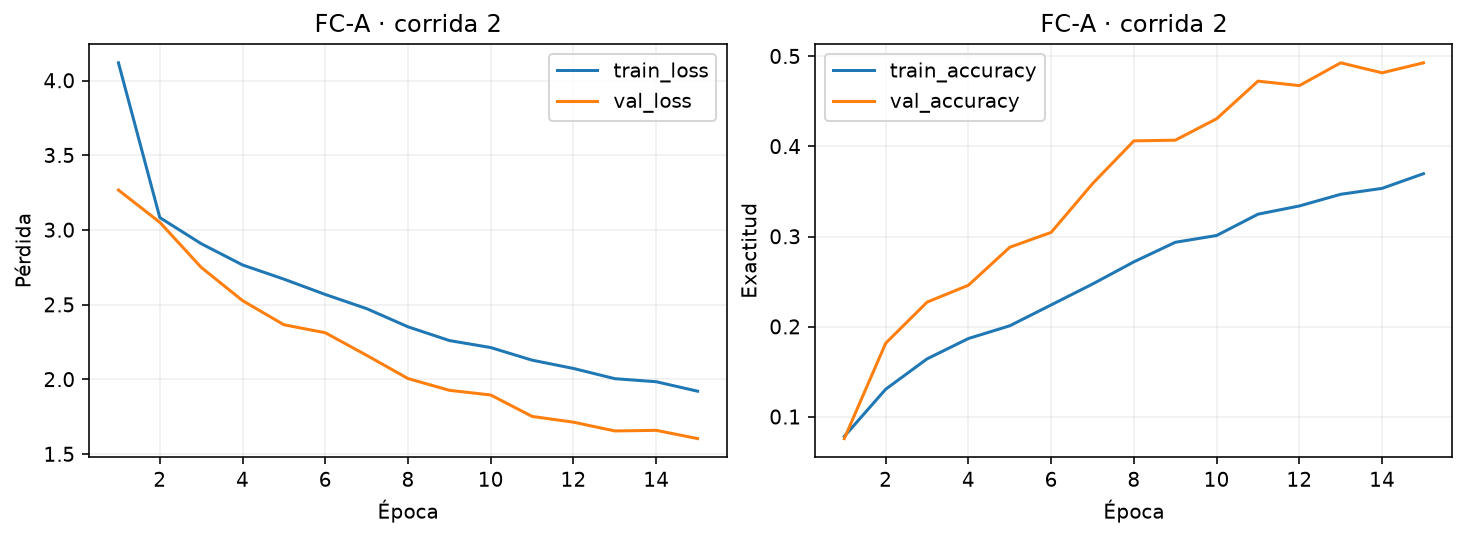

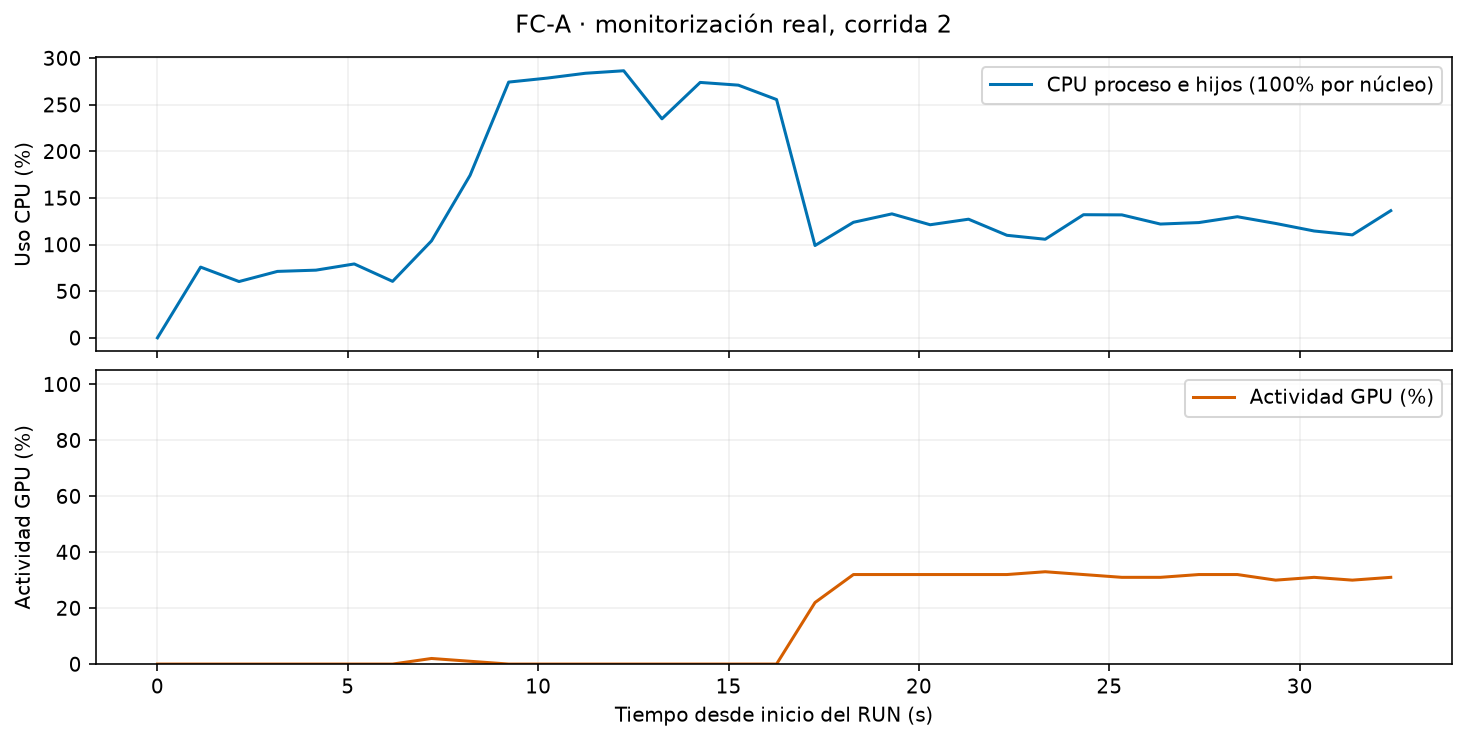

In [12]:
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-012'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna(''))
display(pd.DataFrame(epoch_rows))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-012/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()


### FC-A: corrida 3

RUN: `RUN-20261118T134514Z-fc-a-03`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [13]:
name='FC-A';repetition=3;run_id='RUN-20261118T134514Z-fc-a-03'
run=ROOT/'resultados/paralelo/EXP-012'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 29)             │         1,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,847,705 (18.49 MB)

 Trainable params: 1,607,709 (6.13 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 3,215,420 (12.27 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3450601472, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 51864680 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [14]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [15]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-A 3 {'modelo': 'FC-A', 'repeticion': 3, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 4.118539810180664, 'train_accuracy': 0.07832512259483337, 'val_loss': 3.2670347690582275, 'val_accuracy': 0.07586207240819931, 'pared_epoca_s': 1.1022567000472918, 'validacion_cpu_s': 0.22886920010205358}


EPOCH FC-A 3 {'modelo': 'FC-A', 'repeticion': 3, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.082785129547119, 'train_accuracy': 0.1306239664554596, 'val_loss': 3.051234483718872, 'val_accuracy': 0.18160919845104218, 'pared_epoca_s': 0.9958342999452725, 'validacion_cpu_s': 0.23659440001938492}


EPOCH FC-A 3 {'modelo': 'FC-A', 'repeticion': 3, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 2.9082589149475098, 'train_accuracy': 0.16428571939468384, 'val_loss': 2.749790668487549, 'val_accuracy': 0.22720307111740112, 'pared_epoca_s': 0.9808610000181943, 'validacion_cpu_s': 0.23115440004039556}


EPOCH FC-A 3 {'modelo': 'FC-A', 'repeticion': 3, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 2.7658119201660156, 'train_accuracy': 0.1868637055158615, 'val_loss': 2.5271878242492676, 'val_accuracy': 0.2459770143032074, 'pared_epoca_s': 0.9798138999613002, 'validacion_cpu_s': 0.2355837000068277}


EPOCH FC-A 3 {'modelo': 'FC-A', 'repeticion': 3, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.6709158420562744, 'train_accuracy': 0.20098522305488586, 'val_loss': 2.3656442165374756, 'val_accuracy': 0.28812259435653687, 'pared_epoca_s': 0.968916599988006, 'validacion_cpu_s': 0.22943199996370822}


EPOCH FC-A 3 {'modelo': 'FC-A', 'repeticion': 3, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.568258047103882, 'train_accuracy': 0.22413793206214905, 'val_loss': 2.312250852584839, 'val_accuracy': 0.3045977056026459, 'pared_epoca_s': 0.9888972999760881, 'validacion_cpu_s': 0.2307573000434786}


... (6 outputs left out)

EPOCH FC-A 3 {'modelo': 'FC-A', 'repeticion': 3, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.004786491394043, 'train_accuracy': 0.34688013792037964, 'val_loss': 1.6550549268722534, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 0.9779048999771476, 'validacion_cpu_s': 0.22646720008924603}


EPOCH FC-A 3 {'modelo': 'FC-A', 'repeticion': 3, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 1.984330415725708, 'train_accuracy': 0.3534482717514038, 'val_loss': 1.6590479612350464, 'val_accuracy': 0.48160919547080994, 'pared_epoca_s': 0.9908873999956995, 'validacion_cpu_s': 0.225028199958615}


EPOCH FC-A 3 {'modelo': 'FC-A', 'repeticion': 3, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 1.9210010766983032, 'train_accuracy': 0.3697044253349304, 'val_loss': 1.6039336919784546, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 0.9652876999462023, 'validacion_cpu_s': 0.21987700008321553}


ENTRENAMIENTO CUDA REAL FC-A corrida 3 segundos 14.969787 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,preparacion_cpu,pared,8.096807,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
1,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,entrenamiento_FC-A,pared,14.969787,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,2026-11-18T13:46:17.813773+00:00,2026-11-18T13:46:32.783627+00:00
2,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,validacion_anidada_FC-A,pared,3.427449,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
3,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,h2d_inicial,evento_device,0.014033,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
4,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,h2d_lotes,evento_device,1.718895,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
5,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,forward_loss,evento_device,1.926598,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
6,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,backward,evento_device,2.708026,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
7,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,adam_metricas,evento_device,0.830852,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
8,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,d2h_control,evento_device,0.150033,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
9,EXP-012,RUN-20261118T134514Z-fc-a-03,FC-A,3,d2h_modelo,evento_device,0.031098,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-A,3,1,96,4.118540,0.078325,3.267035,0.075862,1.102257,0.228869
1,FC-A,3,2,192,3.082785,0.130624,3.051234,0.181609,0.995834,0.236594
2,FC-A,3,3,288,2.908259,0.164286,2.749791,0.227203,0.980861,0.231154
3,FC-A,3,4,384,2.765812,0.186864,2.527188,0.245977,0.979814,0.235584
4,FC-A,3,5,480,2.670916,0.200985,2.365644,0.288123,0.968917,0.229432
5,FC-A,3,6,576,2.568258,0.224138,2.312251,0.304598,0.988897,0.230757
6,FC-A,3,7,672,2.473478,0.247291,2.161073,0.358621,0.981934,0.234137
7,FC-A,3,8,768,2.351817,0.271921,2.005586,0.406130,0.976250,0.222994
8,FC-A,3,9,864,2.259944,0.293596,1.926897,0.406897,0.991128,0.221921
9,FC-A,3,10,960,2.213015,0.301149,1.895587,0.430651,0.960354,0.226210


MÉTRICAS REALES {
  "modelo": "FC-A",
  "repeticion": 3,
  "test": {
    "accuracy": 0.517241358757019,
    "loss": 1.5723273754119873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 14.969787,
  "evaluacion_cpu_s": 0.3964019,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}


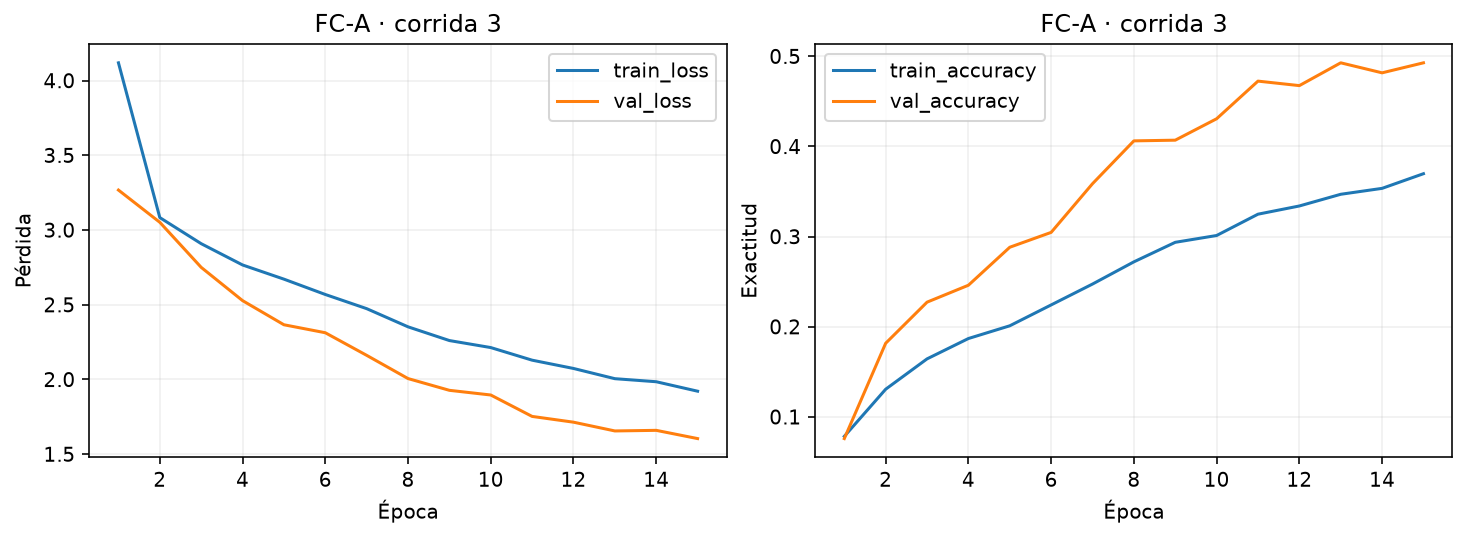

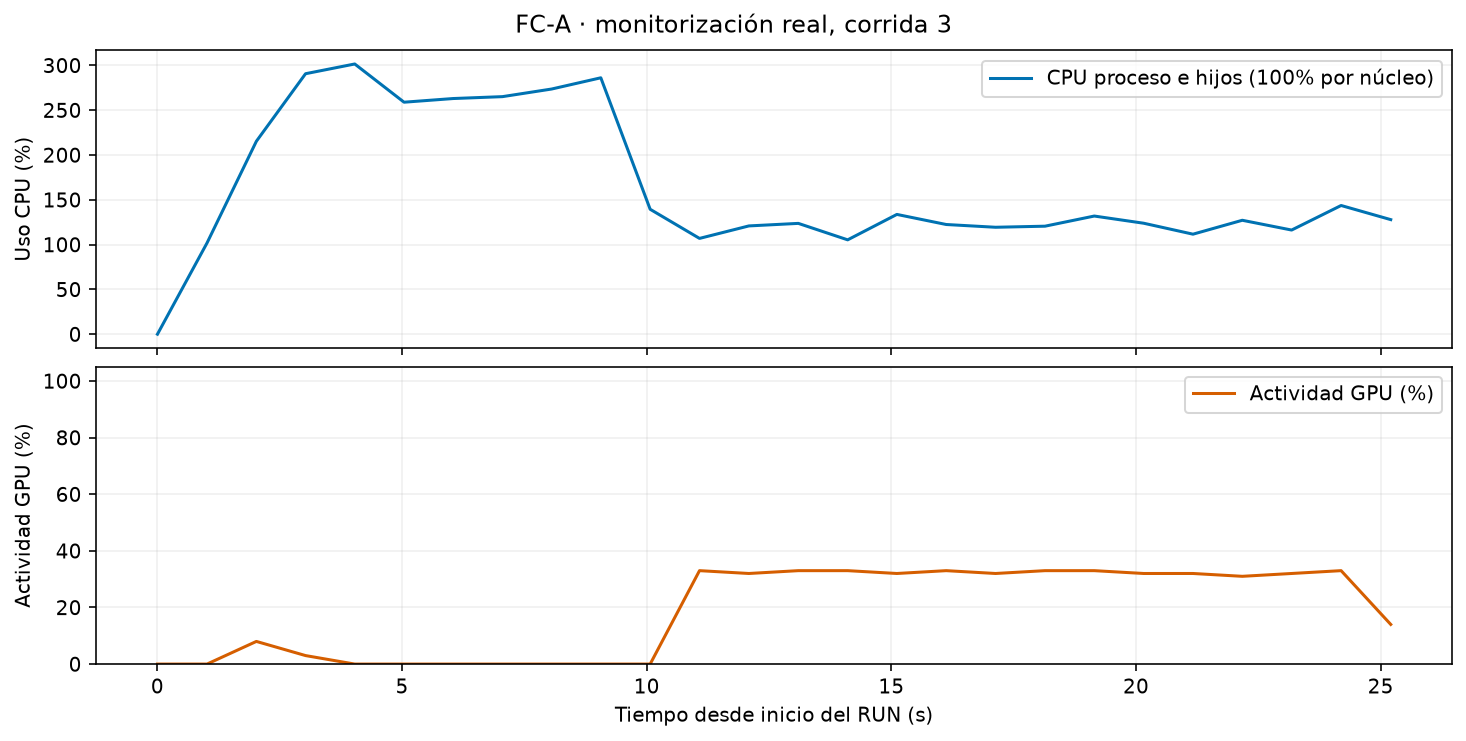

In [16]:
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-012'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna(''))
display(pd.DataFrame(epoch_rows))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-012/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()


### FC-A: corrida 4

RUN: `RUN-20261118T134514Z-fc-a-04`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [17]:
name='FC-A';repetition=4;run_id='RUN-20261118T134514Z-fc-a-04'
run=ROOT/'resultados/paralelo/EXP-012'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 29)             │         1,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,847,705 (18.49 MB)

 Trainable params: 1,607,709 (6.13 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 3,215,420 (12.27 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3450601472, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 51864680 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [18]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [19]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-A 4 {'modelo': 'FC-A', 'repeticion': 4, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 4.118539810180664, 'train_accuracy': 0.07832512259483337, 'val_loss': 3.2670347690582275, 'val_accuracy': 0.07586207240819931, 'pared_epoca_s': 1.156284400029108, 'validacion_cpu_s': 0.23248240002430975}


EPOCH FC-A 4 {'modelo': 'FC-A', 'repeticion': 4, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.082785129547119, 'train_accuracy': 0.1306239664554596, 'val_loss': 3.051234483718872, 'val_accuracy': 0.18160919845104218, 'pared_epoca_s': 0.9853574000298977, 'validacion_cpu_s': 0.2313553000567481}


EPOCH FC-A 4 {'modelo': 'FC-A', 'repeticion': 4, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 2.9082589149475098, 'train_accuracy': 0.16428571939468384, 'val_loss': 2.749790668487549, 'val_accuracy': 0.22720307111740112, 'pared_epoca_s': 0.9954636000329629, 'validacion_cpu_s': 0.23228989995550364}


EPOCH FC-A 4 {'modelo': 'FC-A', 'repeticion': 4, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 2.7658119201660156, 'train_accuracy': 0.1868637055158615, 'val_loss': 2.5271878242492676, 'val_accuracy': 0.2459770143032074, 'pared_epoca_s': 0.9795244000852108, 'validacion_cpu_s': 0.2319433999946341}


EPOCH FC-A 4 {'modelo': 'FC-A', 'repeticion': 4, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.6709158420562744, 'train_accuracy': 0.20098522305488586, 'val_loss': 2.3656442165374756, 'val_accuracy': 0.28812259435653687, 'pared_epoca_s': 0.985647700028494, 'validacion_cpu_s': 0.23985030001495034}


EPOCH FC-A 4 {'modelo': 'FC-A', 'repeticion': 4, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.568258047103882, 'train_accuracy': 0.22413793206214905, 'val_loss': 2.312250852584839, 'val_accuracy': 0.3045977056026459, 'pared_epoca_s': 1.0221411000238732, 'validacion_cpu_s': 0.22769930004142225}


... (6 outputs left out)

EPOCH FC-A 4 {'modelo': 'FC-A', 'repeticion': 4, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.004786491394043, 'train_accuracy': 0.34688013792037964, 'val_loss': 1.6550549268722534, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 1.0014680000022054, 'validacion_cpu_s': 0.24132249993272126}


EPOCH FC-A 4 {'modelo': 'FC-A', 'repeticion': 4, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 1.984330415725708, 'train_accuracy': 0.3534482717514038, 'val_loss': 1.6590479612350464, 'val_accuracy': 0.48160919547080994, 'pared_epoca_s': 0.9757283999351785, 'validacion_cpu_s': 0.22493490006309003}


EPOCH FC-A 4 {'modelo': 'FC-A', 'repeticion': 4, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 1.9210010766983032, 'train_accuracy': 0.3697044253349304, 'val_loss': 1.6039336919784546, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 0.969699899898842, 'validacion_cpu_s': 0.22428690001834184}


ENTRENAMIENTO CUDA REAL FC-A corrida 4 segundos 14.9999501 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,preparacion_cpu,pared,8.046609,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
1,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,entrenamiento_FC-A,pared,14.999950,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,2026-11-18T13:46:44.825604+00:00,2026-11-18T13:46:59.825622+00:00
2,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,validacion_anidada_FC-A,pared,3.467743,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
3,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,h2d_inicial,evento_device,0.014129,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
4,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,h2d_lotes,evento_device,1.713409,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
5,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,forward_loss,evento_device,1.925260,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
6,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,backward,evento_device,2.724813,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
7,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,adam_metricas,evento_device,0.858055,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
8,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,d2h_control,evento_device,0.148104,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
9,EXP-012,RUN-20261118T134514Z-fc-a-04,FC-A,4,d2h_modelo,evento_device,0.030086,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-A,4,1,96,4.118540,0.078325,3.267035,0.075862,1.156284,0.232482
1,FC-A,4,2,192,3.082785,0.130624,3.051234,0.181609,0.985357,0.231355
2,FC-A,4,3,288,2.908259,0.164286,2.749791,0.227203,0.995464,0.232290
3,FC-A,4,4,384,2.765812,0.186864,2.527188,0.245977,0.979524,0.231943
4,FC-A,4,5,480,2.670916,0.200985,2.365644,0.288123,0.985648,0.239850
5,FC-A,4,6,576,2.568258,0.224138,2.312251,0.304598,1.022141,0.227699
6,FC-A,4,7,672,2.473478,0.247291,2.161073,0.358621,0.970689,0.232899
7,FC-A,4,8,768,2.351817,0.271921,2.005586,0.406130,0.971814,0.228556
8,FC-A,4,9,864,2.259944,0.293596,1.926897,0.406897,0.974364,0.230712
9,FC-A,4,10,960,2.213015,0.301149,1.895587,0.430651,0.985756,0.232673


MÉTRICAS REALES {
  "modelo": "FC-A",
  "repeticion": 4,
  "test": {
    "accuracy": 0.517241358757019,
    "loss": 1.5723273754119873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 14.9999501,
  "evaluacion_cpu_s": 0.3900924,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}


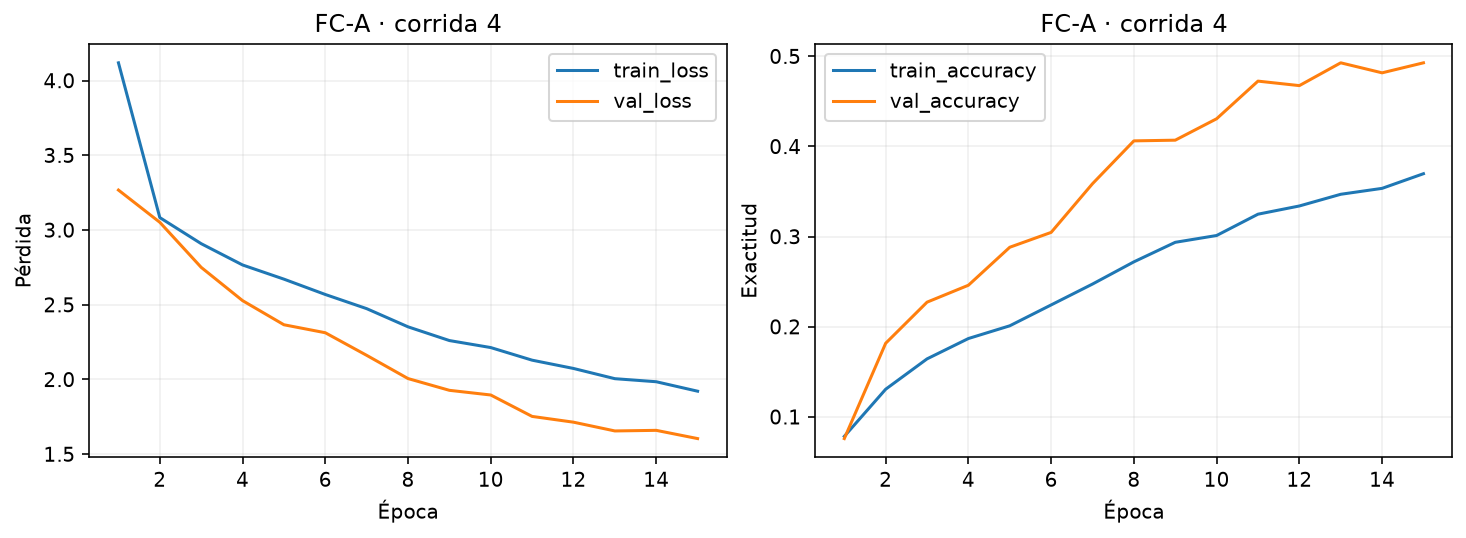

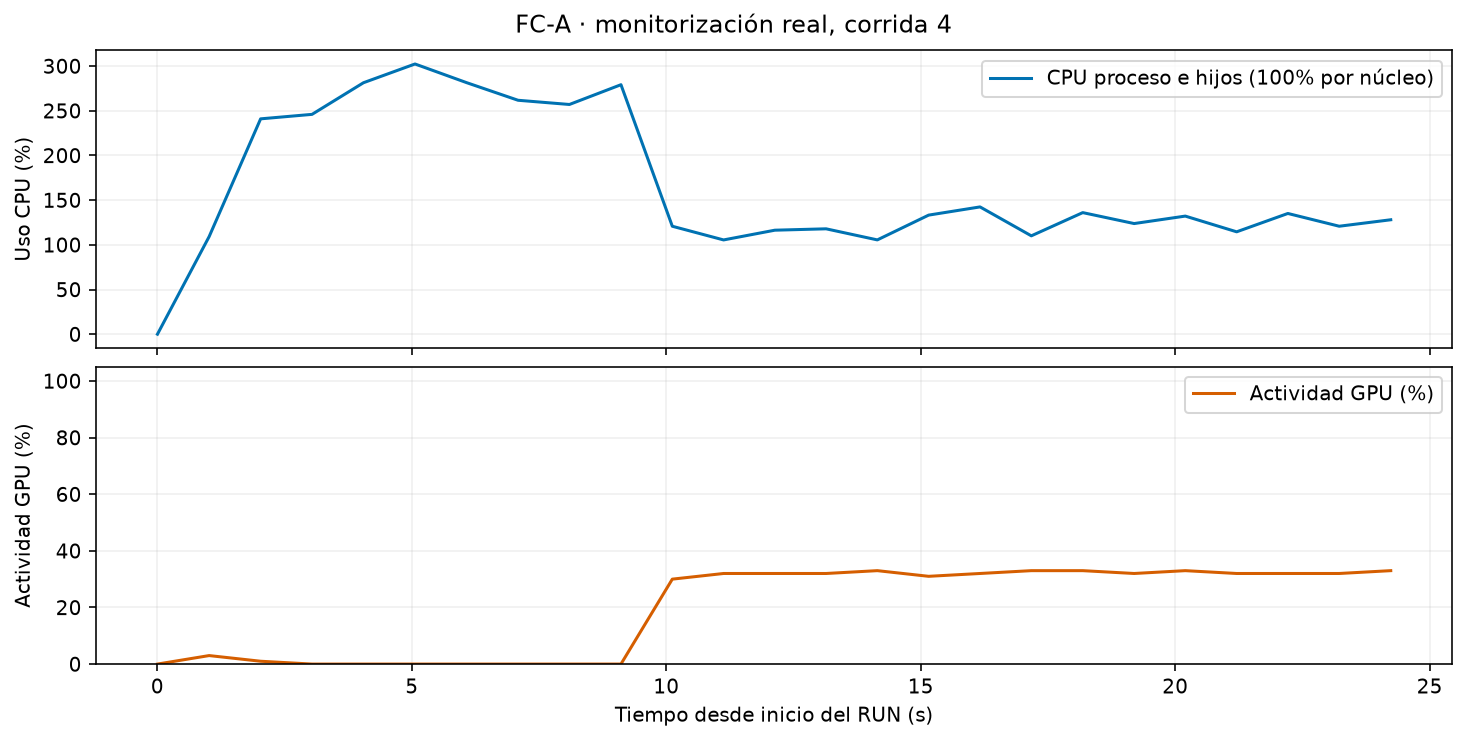

In [20]:
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-012'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna(''))
display(pd.DataFrame(epoch_rows))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-012/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()


### FC-A: corrida 5

RUN: `RUN-20261118T134514Z-fc-a-05`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [21]:
name='FC-A';repetition=5;run_id='RUN-20261118T134514Z-fc-a-05'
run=ROOT/'resultados/paralelo/EXP-012'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 29)             │         1,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,847,705 (18.49 MB)

 Trainable params: 1,607,709 (6.13 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 3,215,420 (12.27 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3450601472, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 51864680 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [22]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [23]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-A 5 {'modelo': 'FC-A', 'repeticion': 5, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 4.118539810180664, 'train_accuracy': 0.07832512259483337, 'val_loss': 3.2670347690582275, 'val_accuracy': 0.07586207240819931, 'pared_epoca_s': 1.1978128000628203, 'validacion_cpu_s': 0.23693499993532896}


EPOCH FC-A 5 {'modelo': 'FC-A', 'repeticion': 5, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.082785129547119, 'train_accuracy': 0.1306239664554596, 'val_loss': 3.051234483718872, 'val_accuracy': 0.18160919845104218, 'pared_epoca_s': 0.9888904000399634, 'validacion_cpu_s': 0.2277052999706939}


EPOCH FC-A 5 {'modelo': 'FC-A', 'repeticion': 5, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 2.9082589149475098, 'train_accuracy': 0.16428571939468384, 'val_loss': 2.749790668487549, 'val_accuracy': 0.22720307111740112, 'pared_epoca_s': 0.9729193000821397, 'validacion_cpu_s': 0.22714920004364103}


EPOCH FC-A 5 {'modelo': 'FC-A', 'repeticion': 5, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 2.7658119201660156, 'train_accuracy': 0.1868637055158615, 'val_loss': 2.5271878242492676, 'val_accuracy': 0.2459770143032074, 'pared_epoca_s': 0.9829977999906987, 'validacion_cpu_s': 0.23174630000721663}


EPOCH FC-A 5 {'modelo': 'FC-A', 'repeticion': 5, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.6709158420562744, 'train_accuracy': 0.20098522305488586, 'val_loss': 2.3656442165374756, 'val_accuracy': 0.28812259435653687, 'pared_epoca_s': 1.0095536999870092, 'validacion_cpu_s': 0.23770459997467697}


EPOCH FC-A 5 {'modelo': 'FC-A', 'repeticion': 5, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.568258047103882, 'train_accuracy': 0.22413793206214905, 'val_loss': 2.312250852584839, 'val_accuracy': 0.3045977056026459, 'pared_epoca_s': 0.9987356000347063, 'validacion_cpu_s': 0.22514909994788468}


... (6 outputs left out)

EPOCH FC-A 5 {'modelo': 'FC-A', 'repeticion': 5, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.004786491394043, 'train_accuracy': 0.34688013792037964, 'val_loss': 1.6550549268722534, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 0.9812829999718815, 'validacion_cpu_s': 0.23460669990163296}


EPOCH FC-A 5 {'modelo': 'FC-A', 'repeticion': 5, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 1.984330415725708, 'train_accuracy': 0.3534482717514038, 'val_loss': 1.6590479612350464, 'val_accuracy': 0.48160919547080994, 'pared_epoca_s': 0.975418199901469, 'validacion_cpu_s': 0.2274755999678746}


EPOCH FC-A 5 {'modelo': 'FC-A', 'repeticion': 5, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 1.9210010766983032, 'train_accuracy': 0.3697044253349304, 'val_loss': 1.6039336919784546, 'val_accuracy': 0.4927203059196472, 'pared_epoca_s': 0.9721604000078514, 'validacion_cpu_s': 0.2295992000726983}


ENTRENAMIENTO CUDA REAL FC-A corrida 5 segundos 15.1278363 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,preparacion_cpu,pared,8.220173,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
1,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,entrenamiento_FC-A,pared,15.127836,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,2026-11-18T13:47:12.036213+00:00,2026-11-18T13:47:27.164126+00:00
2,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,validacion_anidada_FC-A,pared,3.449421,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
3,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,h2d_inicial,evento_device,0.014703,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
4,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,h2d_lotes,evento_device,1.716719,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
5,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,forward_loss,evento_device,1.971370,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
6,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,backward,evento_device,2.754173,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
7,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,adam_metricas,evento_device,0.849114,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
8,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,d2h_control,evento_device,0.153953,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
9,EXP-012,RUN-20261118T134514Z-fc-a-05,FC-A,5,d2h_modelo,evento_device,0.029637,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-A,5,1,96,4.118540,0.078325,3.267035,0.075862,1.197813,0.236935
1,FC-A,5,2,192,3.082785,0.130624,3.051234,0.181609,0.988890,0.227705
2,FC-A,5,3,288,2.908259,0.164286,2.749791,0.227203,0.972919,0.227149
3,FC-A,5,4,384,2.765812,0.186864,2.527188,0.245977,0.982998,0.231746
4,FC-A,5,5,480,2.670916,0.200985,2.365644,0.288123,1.009554,0.237705
5,FC-A,5,6,576,2.568258,0.224138,2.312251,0.304598,0.998736,0.225149
6,FC-A,5,7,672,2.473478,0.247291,2.161073,0.358621,0.979819,0.224384
7,FC-A,5,8,768,2.351817,0.271921,2.005586,0.406130,1.015934,0.228075
8,FC-A,5,9,864,2.259944,0.293596,1.926897,0.406897,1.004736,0.226282
9,FC-A,5,10,960,2.213015,0.301149,1.895587,0.430651,0.980255,0.233172


MÉTRICAS REALES {
  "modelo": "FC-A",
  "repeticion": 5,
  "test": {
    "accuracy": 0.517241358757019,
    "loss": 1.5723273754119873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 15.1278363,
  "evaluacion_cpu_s": 0.3979068,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}


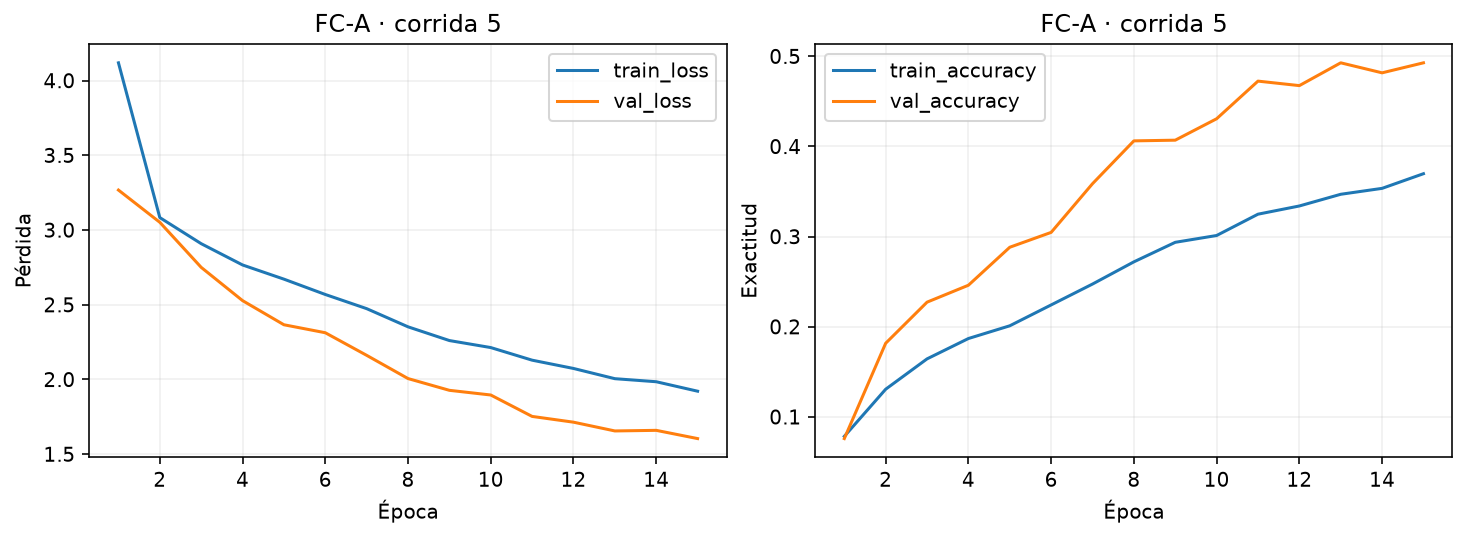

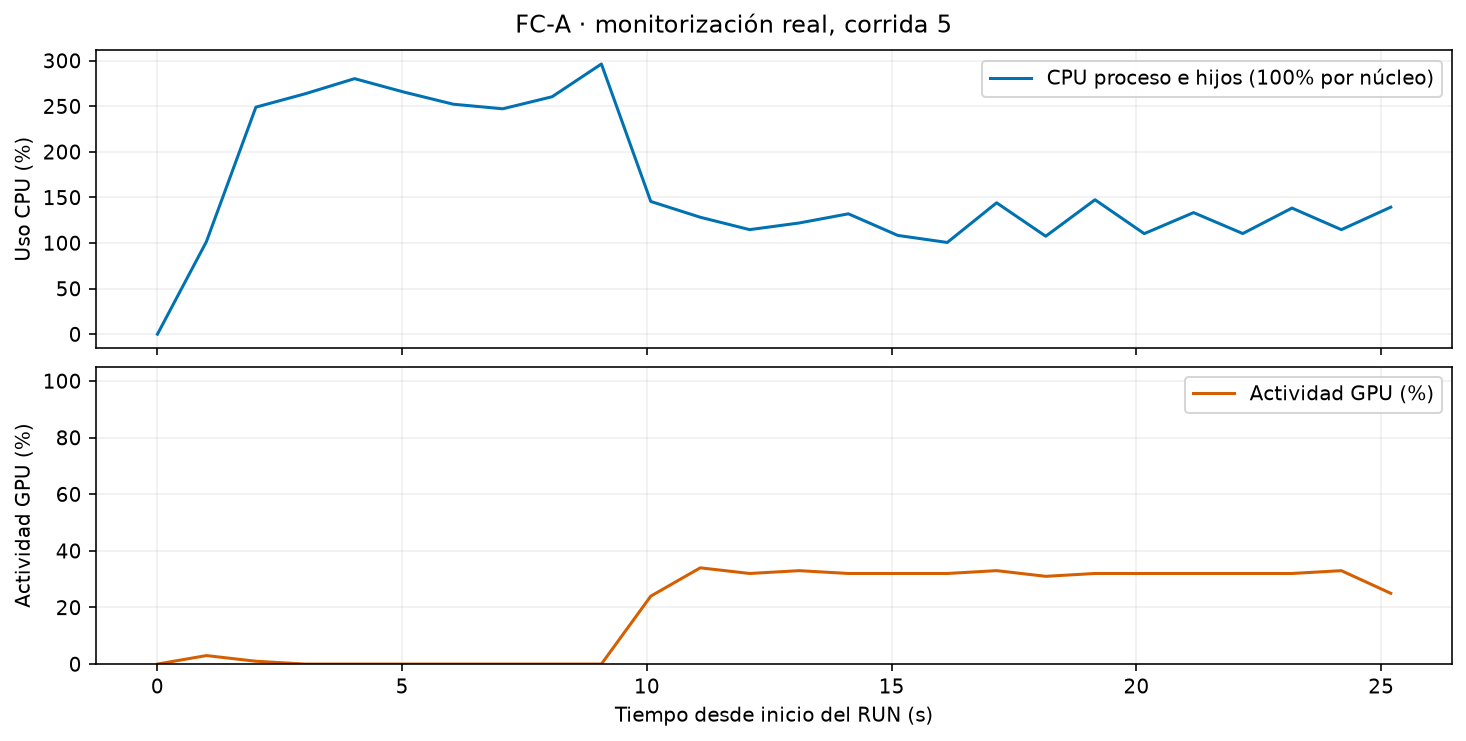

In [24]:
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-012'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna(''))
display(pd.DataFrame(epoch_rows))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-012/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()


## FC-B — cinco ejecuciones nuevas

Batch128, último lote20, 15épocas, 1440actualizaciones. La medida pared incluye transferencias y validación CPU; guardado y gráficas quedan fuera. La primera corrida incorpora captura en vivo; su coste no se resta.

### FC-B: corrida 1

RUN: `RUN-20261118T134514Z-fc-b-01`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [25]:
name='FC-B';repetition=1;run_id='RUN-20261118T134514Z-fc-b-01'
run=ROOT/'resultados/paralelo/EXP-012'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,478,105 (74.30 MB)

 Trainable params: 6,484,509 (24.74 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 12,969,020 (49.47 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3450601472, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 130704488 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [26]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [27]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-B 1 {'modelo': 'FC-B', 'repeticion': 1, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 5.114112377166748, 'train_accuracy': 0.04950739070773125, 'val_loss': 3.3247272968292236, 'val_accuracy': 0.0475095771253109, 'pared_epoca_s': 1.588294900022447, 'validacion_cpu_s': 0.40928969997912645}


EPOCH FC-B 1 {'modelo': 'FC-B', 'repeticion': 1, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.381804943084717, 'train_accuracy': 0.0714285746216774, 'val_loss': 3.245692253112793, 'val_accuracy': 0.08160919696092606, 'pared_epoca_s': 1.5987866000505164, 'validacion_cpu_s': 0.4300015999469906}


EPOCH FC-B 1 {'modelo': 'FC-B', 'repeticion': 1, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 3.192230224609375, 'train_accuracy': 0.09376025944948196, 'val_loss': 3.0364584922790527, 'val_accuracy': 0.1394636034965515, 'pared_epoca_s': 1.526204099995084, 'validacion_cpu_s': 0.43000060005579144}


EPOCH FC-B 1 {'modelo': 'FC-B', 'repeticion': 1, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 3.0399556159973145, 'train_accuracy': 0.1228243038058281, 'val_loss': 2.8100357055664062, 'val_accuracy': 0.17624521255493164, 'pared_epoca_s': 1.3729981000069529, 'validacion_cpu_s': 0.3064291999908164}


EPOCH FC-B 1 {'modelo': 'FC-B', 'repeticion': 1, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.9195146560668945, 'train_accuracy': 0.13612478971481323, 'val_loss': 2.60569429397583, 'val_accuracy': 0.230268195271492, 'pared_epoca_s': 1.3779785999795422, 'validacion_cpu_s': 0.3333707000128925}


EPOCH FC-B 1 {'modelo': 'FC-B', 'repeticion': 1, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.809615135192871, 'train_accuracy': 0.15985222160816193, 'val_loss': 2.513597011566162, 'val_accuracy': 0.22835248708724976, 'pared_epoca_s': 1.3632746000075713, 'validacion_cpu_s': 0.3060338000068441}


... (6 outputs left out)

EPOCH FC-B 1 {'modelo': 'FC-B', 'repeticion': 1, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.2342052459716797, 'train_accuracy': 0.27167487144470215, 'val_loss': 1.859998345375061, 'val_accuracy': 0.40229883790016174, 'pared_epoca_s': 1.3729646999854594, 'validacion_cpu_s': 0.3463415999431163}


EPOCH FC-B 1 {'modelo': 'FC-B', 'repeticion': 1, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 2.1608409881591797, 'train_accuracy': 0.28809523582458496, 'val_loss': 1.8032516241073608, 'val_accuracy': 0.38735631108283997, 'pared_epoca_s': 1.3561524000251666, 'validacion_cpu_s': 0.32025510002858937}


EPOCH FC-B 1 {'modelo': 'FC-B', 'repeticion': 1, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 2.106384754180908, 'train_accuracy': 0.3024630546569824, 'val_loss': 1.7751481533050537, 'val_accuracy': 0.4007662832736969, 'pared_epoca_s': 1.3787567999679595, 'validacion_cpu_s': 0.32694830000400543}


ENTRENAMIENTO CUDA REAL FC-B corrida 1 segundos 21.3026643 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,preparacion_cpu,pared,9.796823,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
1,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,entrenamiento_FC-B,pared,21.302664,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,2026-11-18T13:47:41.608665+00:00,2026-11-18T13:48:02.911399+00:00
2,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,validacion_anidada_FC-B,pared,5.165294,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
3,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,h2d_inicial,evento_device,0.051762,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
4,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,h2d_lotes,evento_device,1.801778,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
5,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,forward_loss,evento_device,2.977323,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
6,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,backward,evento_device,4.818071,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
7,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,adam_metricas,evento_device,1.599303,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
8,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,d2h_control,evento_device,0.117836,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
9,EXP-012,RUN-20261118T134514Z-fc-b-01,FC-B,1,d2h_modelo,evento_device,0.088596,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-B,1,1,96,5.114112,0.049507,3.324727,0.047510,1.588295,0.409290
1,FC-B,1,2,192,3.381805,0.071429,3.245692,0.081609,1.598787,0.430002
2,FC-B,1,3,288,3.192230,0.093760,3.036458,0.139464,1.526204,0.430001
3,FC-B,1,4,384,3.039956,0.122824,2.810036,0.176245,1.372998,0.306429
4,FC-B,1,5,480,2.919515,0.136125,2.605694,0.230268,1.377979,0.333371
5,FC-B,1,6,576,2.809615,0.159852,2.513597,0.228352,1.363275,0.306034
6,FC-B,1,7,672,2.699311,0.176601,2.359455,0.274713,1.373746,0.340615
7,FC-B,1,8,768,2.609292,0.191051,2.271174,0.286973,1.398534,0.330581
8,FC-B,1,9,864,2.523955,0.213957,2.193865,0.313027,1.359989,0.318580
9,FC-B,1,10,960,2.455426,0.228736,2.078432,0.356322,1.373545,0.344202


MÉTRICAS REALES {
  "modelo": "FC-B",
  "repeticion": 1,
  "test": {
    "accuracy": 0.39961686730384827,
    "loss": 1.759406566619873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 21.3026643,
  "evaluacion_cpu_s": 0.5177506,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}


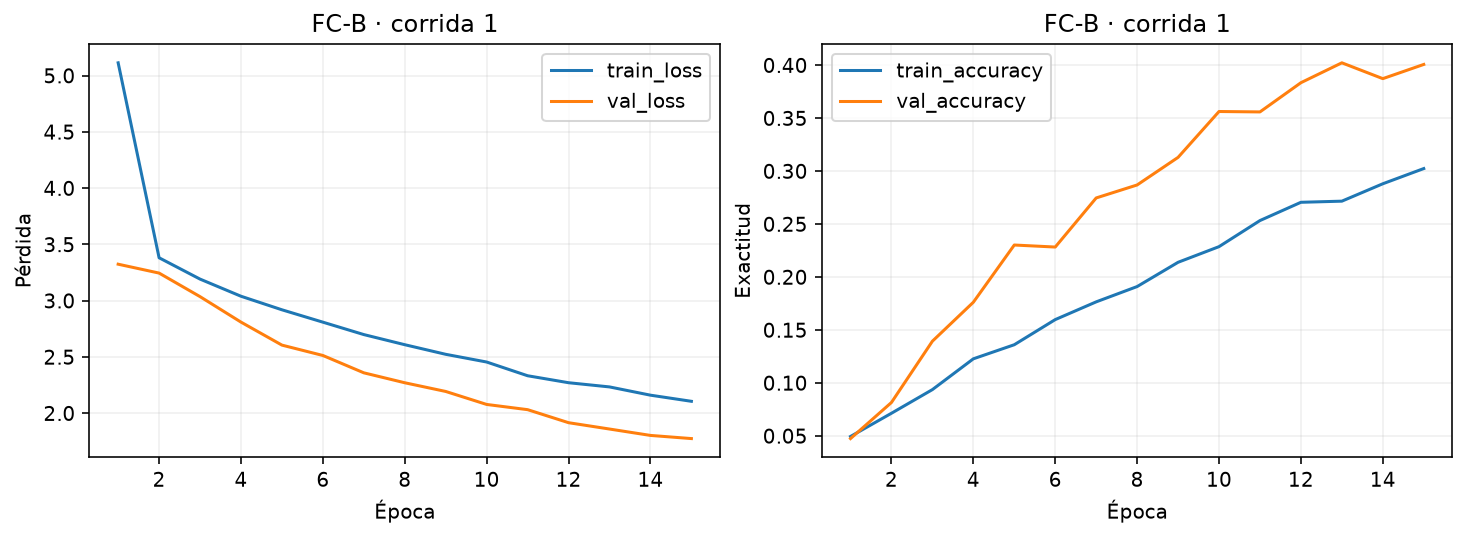

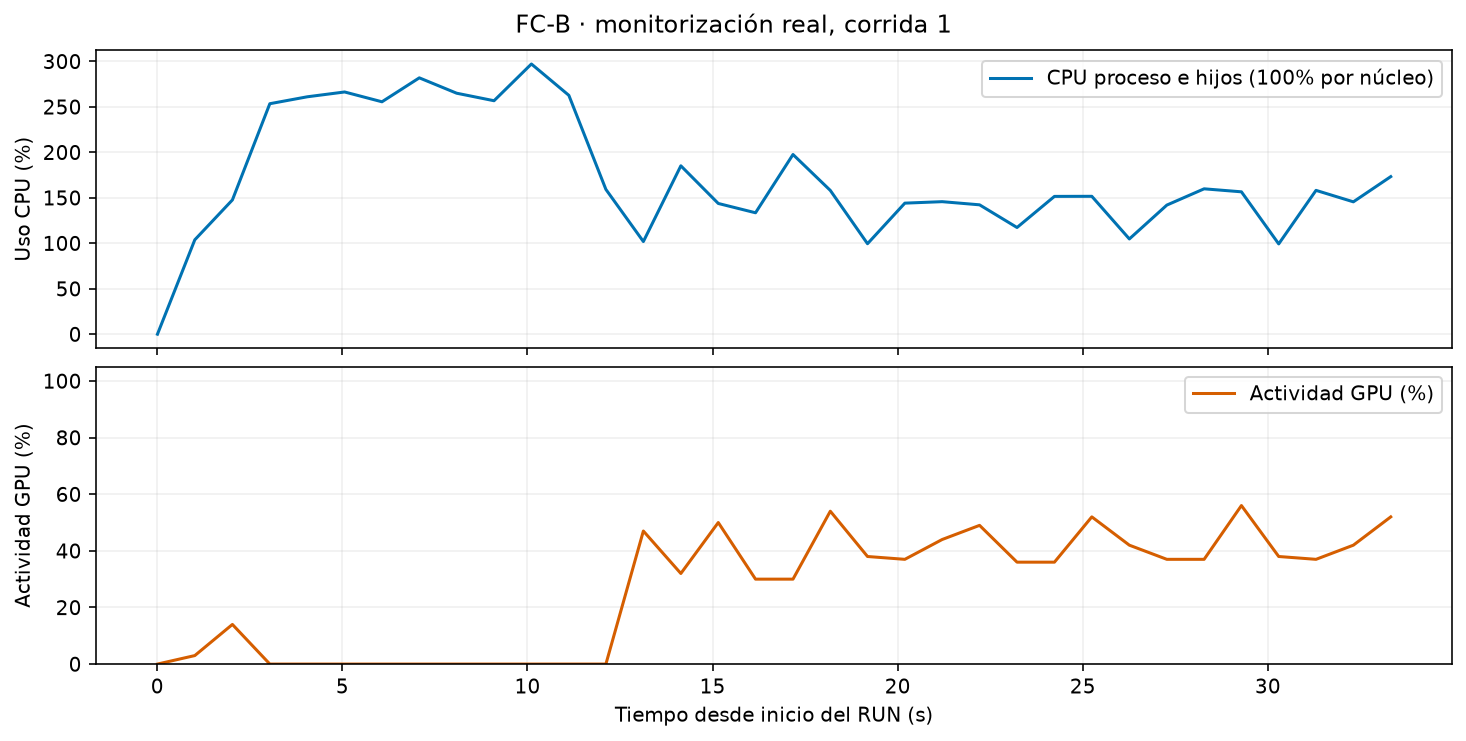

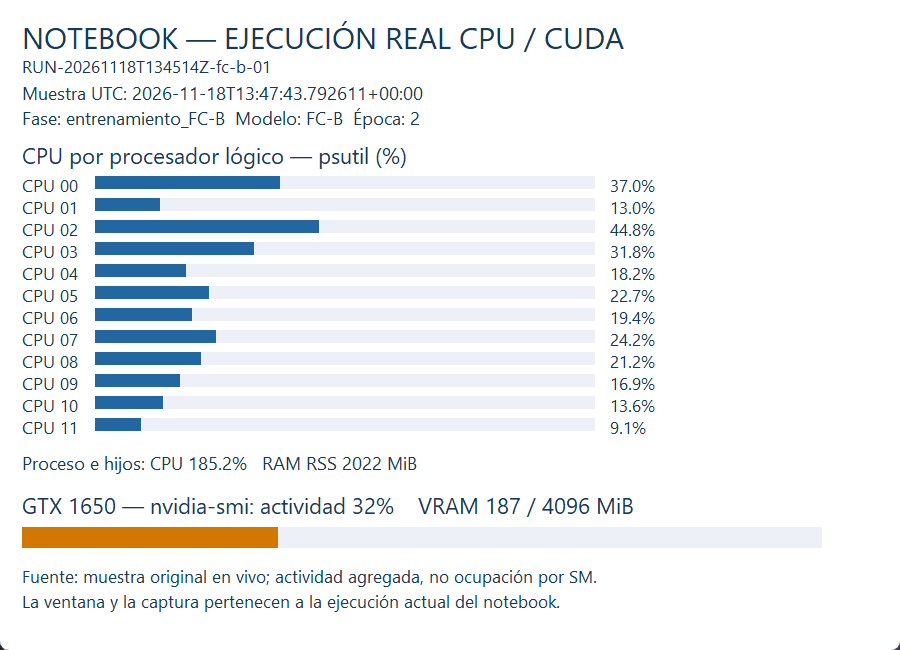

In [28]:
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-012'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna(''))
display(pd.DataFrame(epoch_rows))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-012/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()


### FC-B: corrida 2

RUN: `RUN-20261118T134514Z-fc-b-02`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [29]:
name='FC-B';repetition=2;run_id='RUN-20261118T134514Z-fc-b-02'
run=ROOT/'resultados/paralelo/EXP-012'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,478,105 (74.30 MB)

 Trainable params: 6,484,509 (24.74 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 12,969,020 (49.47 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3448504320, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 130704488 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [30]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [31]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-B 2 {'modelo': 'FC-B', 'repeticion': 2, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 5.114112377166748, 'train_accuracy': 0.04950739070773125, 'val_loss': 3.3247272968292236, 'val_accuracy': 0.0475095771253109, 'pared_epoca_s': 1.5916912000393495, 'validacion_cpu_s': 0.331556300050579}


EPOCH FC-B 2 {'modelo': 'FC-B', 'repeticion': 2, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.381804943084717, 'train_accuracy': 0.0714285746216774, 'val_loss': 3.245692253112793, 'val_accuracy': 0.08160919696092606, 'pared_epoca_s': 1.362608499941416, 'validacion_cpu_s': 0.30849840003065765}


EPOCH FC-B 2 {'modelo': 'FC-B', 'repeticion': 2, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 3.192230224609375, 'train_accuracy': 0.09376025944948196, 'val_loss': 3.0364584922790527, 'val_accuracy': 0.1394636034965515, 'pared_epoca_s': 1.3814386000158265, 'validacion_cpu_s': 0.3272263999097049}


EPOCH FC-B 2 {'modelo': 'FC-B', 'repeticion': 2, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 3.0399556159973145, 'train_accuracy': 0.1228243038058281, 'val_loss': 2.8100357055664062, 'val_accuracy': 0.17624521255493164, 'pared_epoca_s': 1.3616519999923185, 'validacion_cpu_s': 0.3102483000839129}


EPOCH FC-B 2 {'modelo': 'FC-B', 'repeticion': 2, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.9195146560668945, 'train_accuracy': 0.13612478971481323, 'val_loss': 2.60569429397583, 'val_accuracy': 0.230268195271492, 'pared_epoca_s': 1.3458561999723315, 'validacion_cpu_s': 0.3191050000023097}


EPOCH FC-B 2 {'modelo': 'FC-B', 'repeticion': 2, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.809615135192871, 'train_accuracy': 0.15985222160816193, 'val_loss': 2.513597011566162, 'val_accuracy': 0.22835248708724976, 'pared_epoca_s': 1.3614131999202073, 'validacion_cpu_s': 0.32328469993080944}


... (6 outputs left out)

EPOCH FC-B 2 {'modelo': 'FC-B', 'repeticion': 2, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.2342052459716797, 'train_accuracy': 0.27167487144470215, 'val_loss': 1.859998345375061, 'val_accuracy': 0.40229883790016174, 'pared_epoca_s': 1.355373500031419, 'validacion_cpu_s': 0.3106781999813393}


EPOCH FC-B 2 {'modelo': 'FC-B', 'repeticion': 2, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 2.1608409881591797, 'train_accuracy': 0.28809523582458496, 'val_loss': 1.8032516241073608, 'val_accuracy': 0.38735631108283997, 'pared_epoca_s': 1.3421227999497205, 'validacion_cpu_s': 0.31035210005939007}


EPOCH FC-B 2 {'modelo': 'FC-B', 'repeticion': 2, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 2.106384754180908, 'train_accuracy': 0.3024630546569824, 'val_loss': 1.7751481533050537, 'val_accuracy': 0.4007662832736969, 'pared_epoca_s': 1.3642112000379711, 'validacion_cpu_s': 0.3320852000033483}


ENTRENAMIENTO CUDA REAL FC-B corrida 2 segundos 20.9450619 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,preparacion_cpu,pared,7.993484,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
1,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,entrenamiento_FC-B,pared,20.945062,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,2026-11-18T13:48:15.801347+00:00,2026-11-18T13:48:36.746478+00:00
2,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,validacion_anidada_FC-B,pared,4.898155,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
3,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,h2d_inicial,evento_device,0.054568,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
4,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,h2d_lotes,evento_device,1.799696,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
5,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,forward_loss,evento_device,2.962225,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
6,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,backward,evento_device,4.746297,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
7,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,adam_metricas,evento_device,1.627663,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
8,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,d2h_control,evento_device,0.120421,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
9,EXP-012,RUN-20261118T134514Z-fc-b-02,FC-B,2,d2h_modelo,evento_device,0.089873,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-B,2,1,96,5.114112,0.049507,3.324727,0.047510,1.591691,0.331556
1,FC-B,2,2,192,3.381805,0.071429,3.245692,0.081609,1.362608,0.308498
2,FC-B,2,3,288,3.192230,0.093760,3.036458,0.139464,1.381439,0.327226
3,FC-B,2,4,384,3.039956,0.122824,2.810036,0.176245,1.361652,0.310248
4,FC-B,2,5,480,2.919515,0.136125,2.605694,0.230268,1.345856,0.319105
5,FC-B,2,6,576,2.809615,0.159852,2.513597,0.228352,1.361413,0.323285
6,FC-B,2,7,672,2.699311,0.176601,2.359455,0.274713,1.345294,0.298784
7,FC-B,2,8,768,2.609292,0.191051,2.271174,0.286973,1.382831,0.310426
8,FC-B,2,9,864,2.523955,0.213957,2.193865,0.313027,1.361773,0.333678
9,FC-B,2,10,960,2.455426,0.228736,2.078432,0.356322,1.435189,0.385598


MÉTRICAS REALES {
  "modelo": "FC-B",
  "repeticion": 2,
  "test": {
    "accuracy": 0.39961686730384827,
    "loss": 1.759406566619873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 20.9450619,
  "evaluacion_cpu_s": 0.5312584,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}


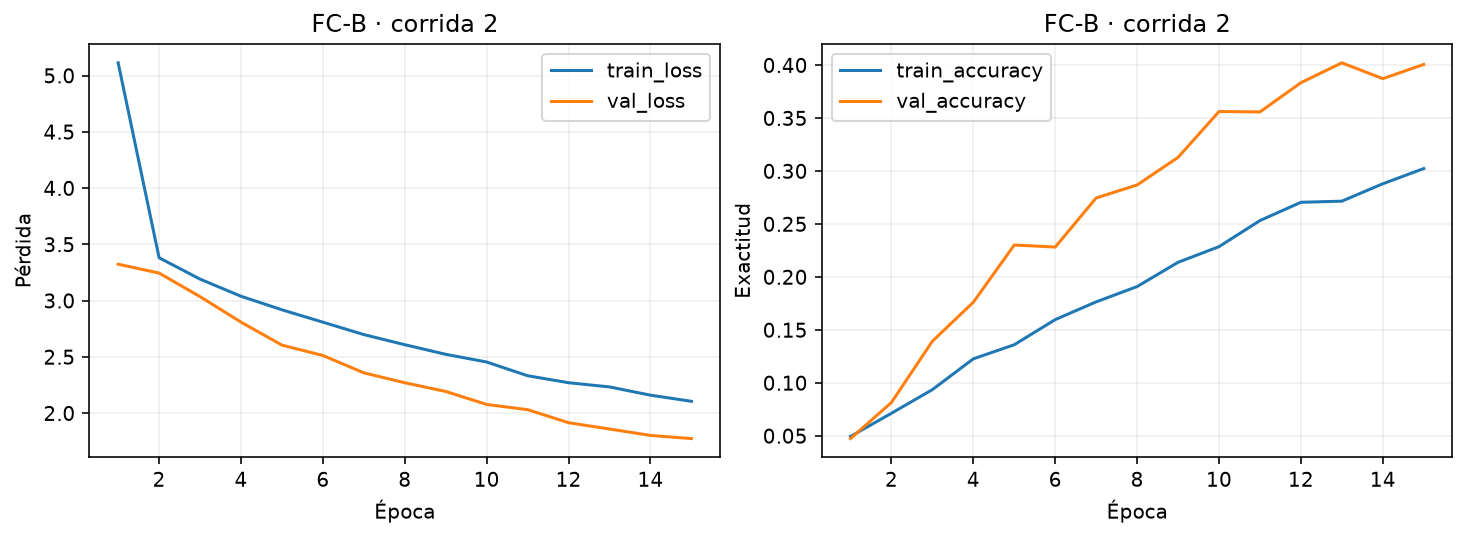

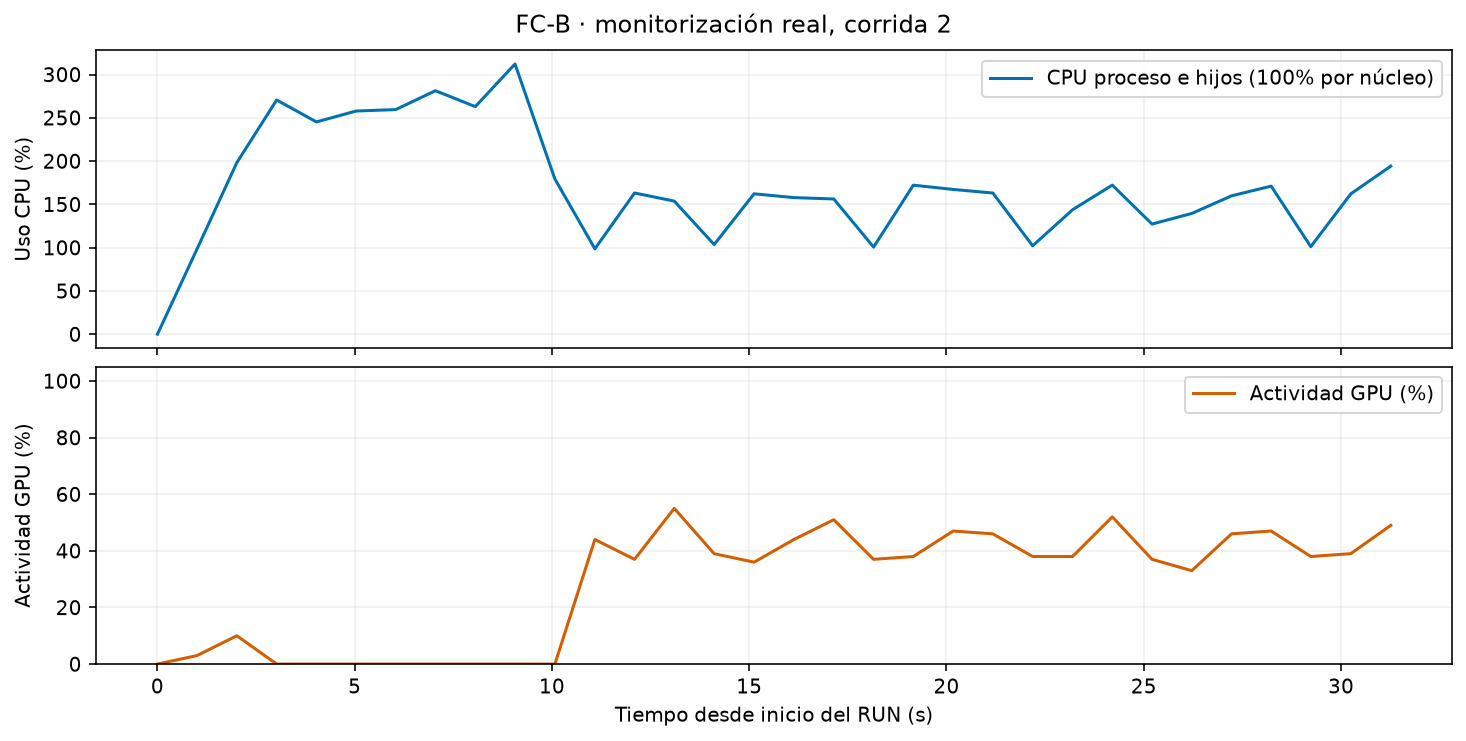

In [32]:
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-012'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna(''))
display(pd.DataFrame(epoch_rows))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-012/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()


### FC-B: corrida 3

RUN: `RUN-20261118T134514Z-fc-b-03`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [33]:
name='FC-B';repetition=3;run_id='RUN-20261118T134514Z-fc-b-03'
run=ROOT/'resultados/paralelo/EXP-012'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,478,105 (74.30 MB)

 Trainable params: 6,484,509 (24.74 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 12,969,020 (49.47 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3450601472, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 130704488 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [34]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [35]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-B 3 {'modelo': 'FC-B', 'repeticion': 3, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 5.114112377166748, 'train_accuracy': 0.04950739070773125, 'val_loss': 3.3247272968292236, 'val_accuracy': 0.0475095771253109, 'pared_epoca_s': 1.548382299952209, 'validacion_cpu_s': 0.34454289998393506}


EPOCH FC-B 3 {'modelo': 'FC-B', 'repeticion': 3, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.381804943084717, 'train_accuracy': 0.0714285746216774, 'val_loss': 3.245692253112793, 'val_accuracy': 0.08160919696092606, 'pared_epoca_s': 1.3603323999559507, 'validacion_cpu_s': 0.3243243000470102}


EPOCH FC-B 3 {'modelo': 'FC-B', 'repeticion': 3, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 3.192230224609375, 'train_accuracy': 0.09376025944948196, 'val_loss': 3.0364584922790527, 'val_accuracy': 0.1394636034965515, 'pared_epoca_s': 1.3526339000090957, 'validacion_cpu_s': 0.3243825000245124}


EPOCH FC-B 3 {'modelo': 'FC-B', 'repeticion': 3, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 3.0399556159973145, 'train_accuracy': 0.1228243038058281, 'val_loss': 2.8100357055664062, 'val_accuracy': 0.17624521255493164, 'pared_epoca_s': 1.3585641999961808, 'validacion_cpu_s': 0.3138947000261396}


EPOCH FC-B 3 {'modelo': 'FC-B', 'repeticion': 3, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.9195146560668945, 'train_accuracy': 0.13612478971481323, 'val_loss': 2.60569429397583, 'val_accuracy': 0.230268195271492, 'pared_epoca_s': 1.4647621000185609, 'validacion_cpu_s': 0.383318500011228}


EPOCH FC-B 3 {'modelo': 'FC-B', 'repeticion': 3, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.809615135192871, 'train_accuracy': 0.15985222160816193, 'val_loss': 2.513597011566162, 'val_accuracy': 0.22835248708724976, 'pared_epoca_s': 1.4730512999230996, 'validacion_cpu_s': 0.38707360008265823}


... (6 outputs left out)

EPOCH FC-B 3 {'modelo': 'FC-B', 'repeticion': 3, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.2342052459716797, 'train_accuracy': 0.27167487144470215, 'val_loss': 1.859998345375061, 'val_accuracy': 0.40229883790016174, 'pared_epoca_s': 1.4678898999700323, 'validacion_cpu_s': 0.3491063000401482}


EPOCH FC-B 3 {'modelo': 'FC-B', 'repeticion': 3, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 2.1608409881591797, 'train_accuracy': 0.28809523582458496, 'val_loss': 1.8032516241073608, 'val_accuracy': 0.38735631108283997, 'pared_epoca_s': 1.3497950000455603, 'validacion_cpu_s': 0.30734539998229593}


EPOCH FC-B 3 {'modelo': 'FC-B', 'repeticion': 3, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 2.106384754180908, 'train_accuracy': 0.3024630546569824, 'val_loss': 1.7751481533050537, 'val_accuracy': 0.4007662832736969, 'pared_epoca_s': 1.3894083000486717, 'validacion_cpu_s': 0.3259338999632746}


ENTRENAMIENTO CUDA REAL FC-B corrida 3 segundos 21.251391 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,preparacion_cpu,pared,8.233045,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
1,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,entrenamiento_FC-B,pared,21.251391,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,2026-11-18T13:48:49.896389+00:00,2026-11-18T13:49:11.147848+00:00
2,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,validacion_anidada_FC-B,pared,5.098655,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
3,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,h2d_inicial,evento_device,0.051651,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
4,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,h2d_lotes,evento_device,1.824647,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
5,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,forward_loss,evento_device,3.012794,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
6,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,backward,evento_device,4.794546,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
7,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,adam_metricas,evento_device,1.628329,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
8,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,d2h_control,evento_device,0.132226,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
9,EXP-012,RUN-20261118T134514Z-fc-b-03,FC-B,3,d2h_modelo,evento_device,0.087699,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-B,3,1,96,5.114112,0.049507,3.324727,0.047510,1.548382,0.344543
1,FC-B,3,2,192,3.381805,0.071429,3.245692,0.081609,1.360332,0.324324
2,FC-B,3,3,288,3.192230,0.093760,3.036458,0.139464,1.352634,0.324383
3,FC-B,3,4,384,3.039956,0.122824,2.810036,0.176245,1.358564,0.313895
4,FC-B,3,5,480,2.919515,0.136125,2.605694,0.230268,1.464762,0.383319
5,FC-B,3,6,576,2.809615,0.159852,2.513597,0.228352,1.473051,0.387074
6,FC-B,3,7,672,2.699311,0.176601,2.359455,0.274713,1.438140,0.396275
7,FC-B,3,8,768,2.609292,0.191051,2.271174,0.286973,1.372937,0.299552
8,FC-B,3,9,864,2.523955,0.213957,2.193865,0.313027,1.365826,0.319314
9,FC-B,3,10,960,2.455426,0.228736,2.078432,0.356322,1.391923,0.343057


MÉTRICAS REALES {
  "modelo": "FC-B",
  "repeticion": 3,
  "test": {
    "accuracy": 0.39961686730384827,
    "loss": 1.759406566619873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 21.251391,
  "evaluacion_cpu_s": 0.5258163,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}


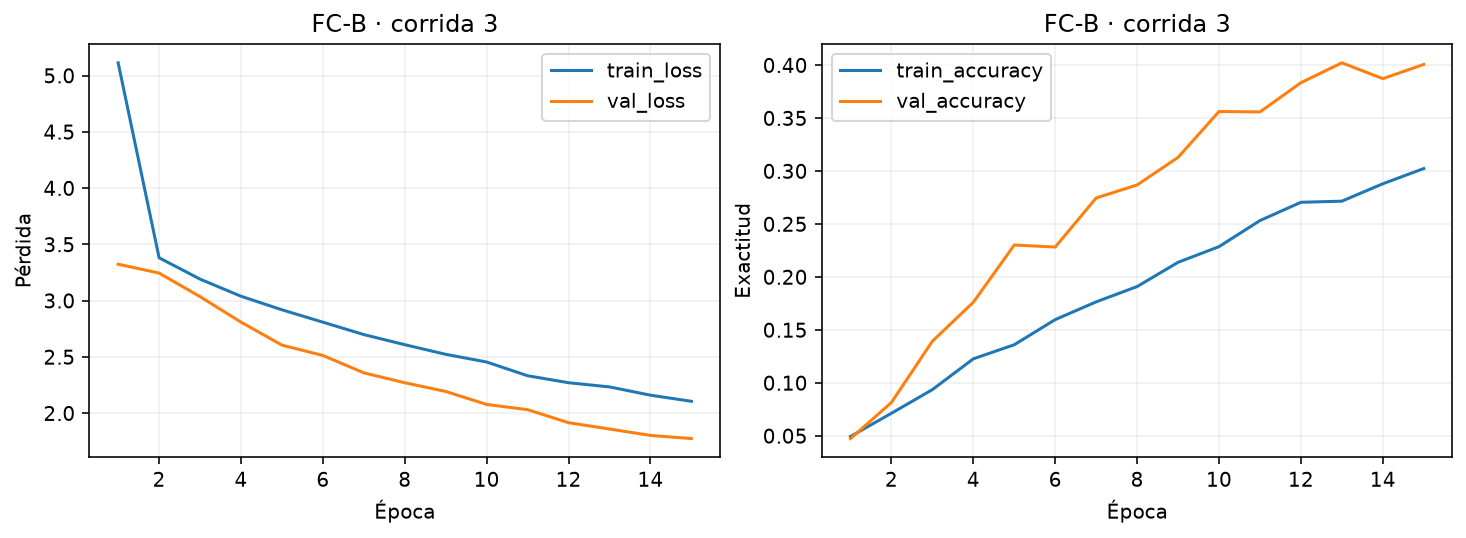

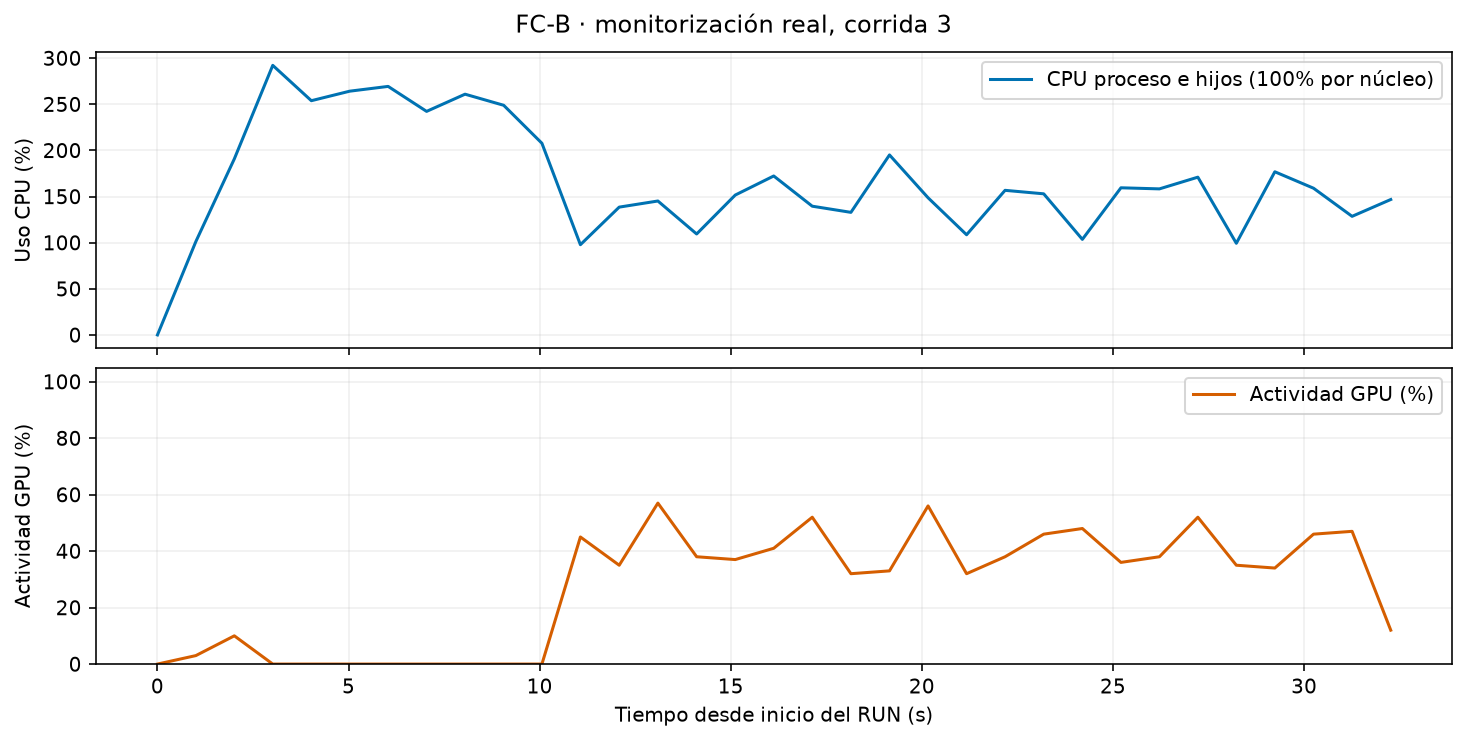

In [36]:
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-012'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna(''))
display(pd.DataFrame(epoch_rows))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-012/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()


### FC-B: corrida 4

RUN: `RUN-20261118T134514Z-fc-b-04`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [37]:
name='FC-B';repetition=4;run_id='RUN-20261118T134514Z-fc-b-04'
run=ROOT/'resultados/paralelo/EXP-012'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,478,105 (74.30 MB)

 Trainable params: 6,484,509 (24.74 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 12,969,020 (49.47 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3452698624, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 130704488 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [38]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [39]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-B 4 {'modelo': 'FC-B', 'repeticion': 4, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 5.114112377166748, 'train_accuracy': 0.04950739070773125, 'val_loss': 3.3247272968292236, 'val_accuracy': 0.0475095771253109, 'pared_epoca_s': 1.6431643000105396, 'validacion_cpu_s': 0.32559719996061176}


EPOCH FC-B 4 {'modelo': 'FC-B', 'repeticion': 4, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.381804943084717, 'train_accuracy': 0.0714285746216774, 'val_loss': 3.245692253112793, 'val_accuracy': 0.08160919696092606, 'pared_epoca_s': 1.359677999978885, 'validacion_cpu_s': 0.32419399998616427}


EPOCH FC-B 4 {'modelo': 'FC-B', 'repeticion': 4, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 3.192230224609375, 'train_accuracy': 0.09376025944948196, 'val_loss': 3.0364584922790527, 'val_accuracy': 0.1394636034965515, 'pared_epoca_s': 1.3588407000061125, 'validacion_cpu_s': 0.3255012999288738}


EPOCH FC-B 4 {'modelo': 'FC-B', 'repeticion': 4, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 3.0399556159973145, 'train_accuracy': 0.1228243038058281, 'val_loss': 2.8100357055664062, 'val_accuracy': 0.17624521255493164, 'pared_epoca_s': 1.3657489999895915, 'validacion_cpu_s': 0.34271680004894733}


EPOCH FC-B 4 {'modelo': 'FC-B', 'repeticion': 4, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.9195146560668945, 'train_accuracy': 0.13612478971481323, 'val_loss': 2.60569429397583, 'val_accuracy': 0.230268195271492, 'pared_epoca_s': 1.403727800003253, 'validacion_cpu_s': 0.3564245000015944}


EPOCH FC-B 4 {'modelo': 'FC-B', 'repeticion': 4, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.809615135192871, 'train_accuracy': 0.15985222160816193, 'val_loss': 2.513597011566162, 'val_accuracy': 0.22835248708724976, 'pared_epoca_s': 1.3757733999518678, 'validacion_cpu_s': 0.3297628000145778}


... (6 outputs left out)

EPOCH FC-B 4 {'modelo': 'FC-B', 'repeticion': 4, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.2342052459716797, 'train_accuracy': 0.27167487144470215, 'val_loss': 1.859998345375061, 'val_accuracy': 0.40229883790016174, 'pared_epoca_s': 1.3817834999645129, 'validacion_cpu_s': 0.34350369998719543}


EPOCH FC-B 4 {'modelo': 'FC-B', 'repeticion': 4, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 2.1608409881591797, 'train_accuracy': 0.28809523582458496, 'val_loss': 1.8032516241073608, 'val_accuracy': 0.38735631108283997, 'pared_epoca_s': 1.3316179000539705, 'validacion_cpu_s': 0.3036096999421716}


EPOCH FC-B 4 {'modelo': 'FC-B', 'repeticion': 4, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 2.106384754180908, 'train_accuracy': 0.3024630546569824, 'val_loss': 1.7751481533050537, 'val_accuracy': 0.4007662832736969, 'pared_epoca_s': 1.3505069999955595, 'validacion_cpu_s': 0.3119558999314904}


ENTRENAMIENTO CUDA REAL FC-B corrida 4 segundos 20.9591045 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,preparacion_cpu,pared,8.299453,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
1,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,entrenamiento_FC-B,pared,20.959104,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,2026-11-18T13:49:24.333702+00:00,2026-11-18T13:49:45.292875+00:00
2,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,validacion_anidada_FC-B,pared,4.966636,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
3,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,h2d_inicial,evento_device,0.051545,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
4,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,h2d_lotes,evento_device,1.808304,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
5,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,forward_loss,evento_device,2.971081,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
6,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,backward,evento_device,4.727185,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
7,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,adam_metricas,evento_device,1.630700,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
8,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,d2h_control,evento_device,0.125961,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
9,EXP-012,RUN-20261118T134514Z-fc-b-04,FC-B,4,d2h_modelo,evento_device,0.085276,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-B,4,1,96,5.114112,0.049507,3.324727,0.047510,1.643164,0.325597
1,FC-B,4,2,192,3.381805,0.071429,3.245692,0.081609,1.359678,0.324194
2,FC-B,4,3,288,3.192230,0.093760,3.036458,0.139464,1.358841,0.325501
3,FC-B,4,4,384,3.039956,0.122824,2.810036,0.176245,1.365749,0.342717
4,FC-B,4,5,480,2.919515,0.136125,2.605694,0.230268,1.403728,0.356425
5,FC-B,4,6,576,2.809615,0.159852,2.513597,0.228352,1.375773,0.329763
6,FC-B,4,7,672,2.699311,0.176601,2.359455,0.274713,1.444256,0.402257
7,FC-B,4,8,768,2.609292,0.191051,2.271174,0.286973,1.371360,0.317387
8,FC-B,4,9,864,2.523955,0.213957,2.193865,0.313027,1.349749,0.316159
9,FC-B,4,10,960,2.455426,0.228736,2.078432,0.356322,1.348234,0.325760


MÉTRICAS REALES {
  "modelo": "FC-B",
  "repeticion": 4,
  "test": {
    "accuracy": 0.39961686730384827,
    "loss": 1.759406566619873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 20.9591045,
  "evaluacion_cpu_s": 0.5110136,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}


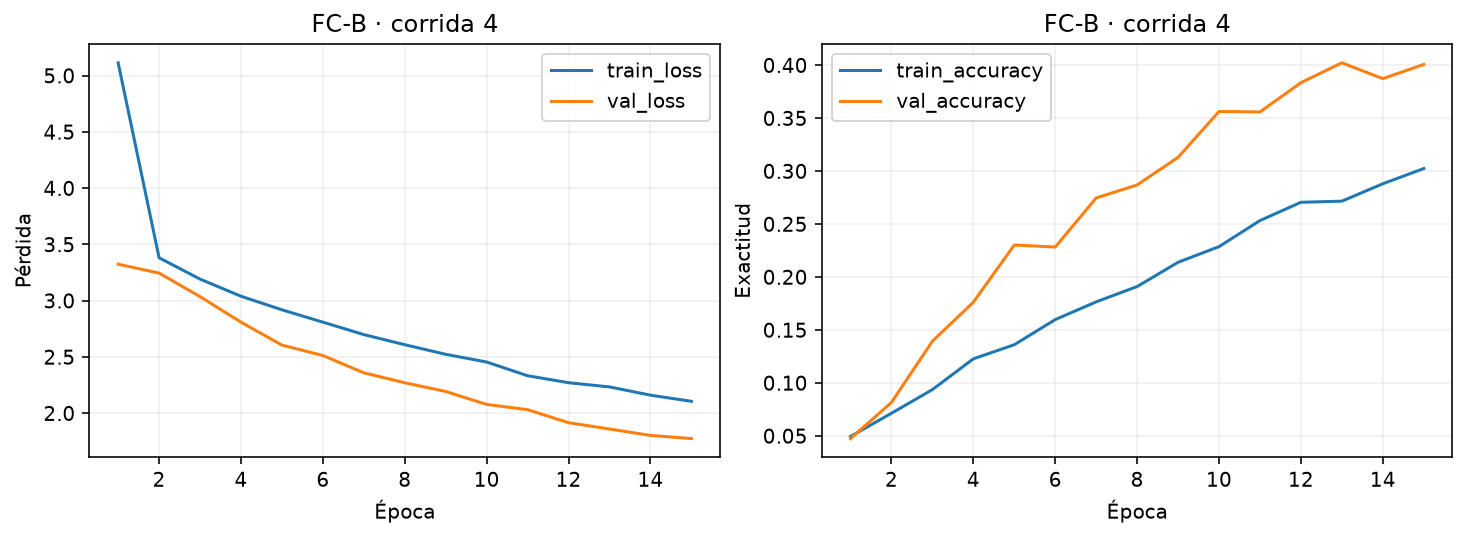

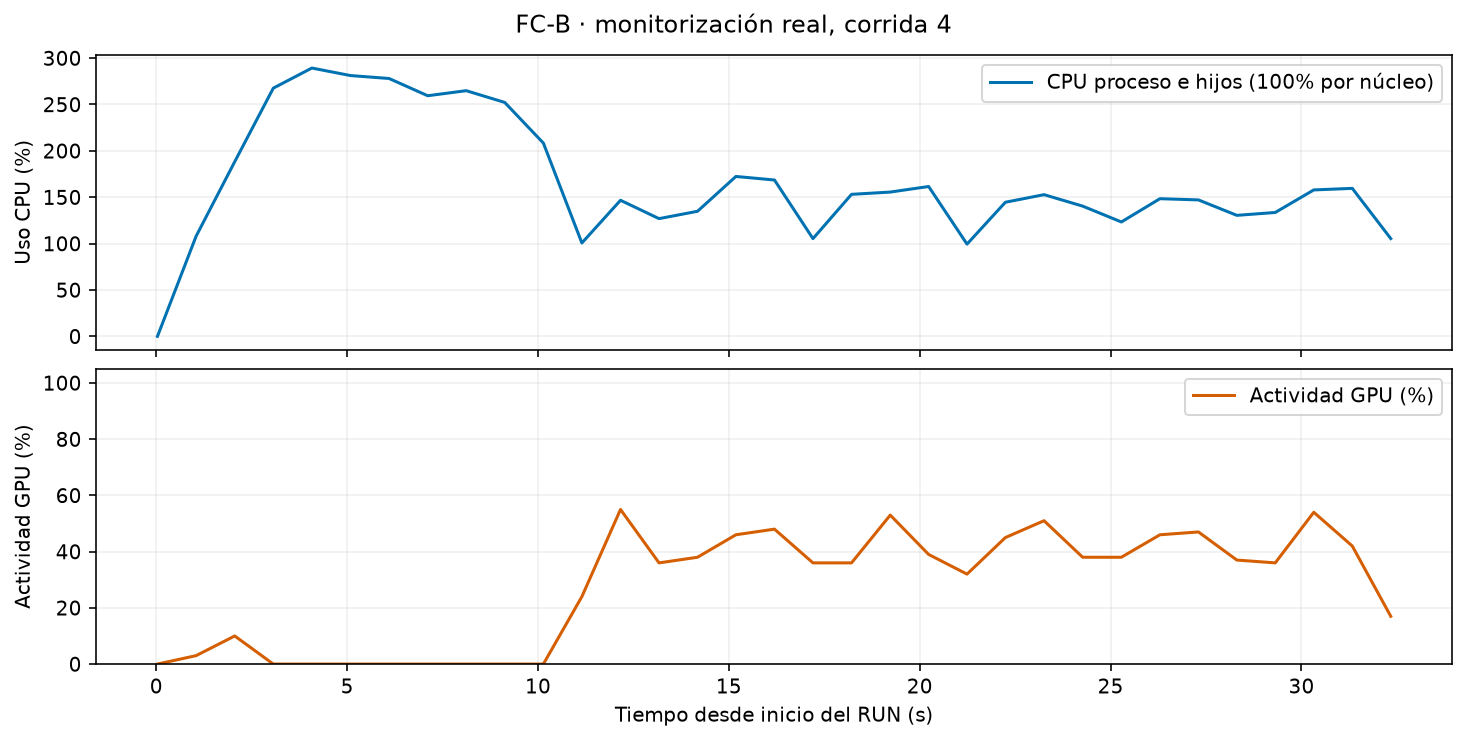

In [40]:
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-012'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna(''))
display(pd.DataFrame(epoch_rows))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-012/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()


### FC-B: corrida 5

RUN: `RUN-20261118T134514Z-fc-b-05`. Inicialización/restauración → preparación CPU → entrenamiento CUDA → evaluación CPU y evidencias.

In [41]:
name='FC-B';repetition=5;run_id='RUN-20261118T134514Z-fc-b-05'
run=ROOT/'resultados/paralelo/EXP-012'/run_id
run.mkdir(exist_ok=False)
timings=[];epoch_rows=[];events={};shuffle_hashes=[]
state('inicializacion')
stop,monitor=iniciar_monitor(run)
if repetition==1:
    capture_log=(run/'capturador.log').open('x',encoding='utf8')
    capture=subprocess.Popen([sys.executable,'-X','utf8',str(ROOT/'scripts/capturar_fc_real.py'),
        '--run',str(run),'--tipo','cuda','--modelo',name,'--nombre',name.lower()],
        stdout=capture_log,stderr=subprocess.STDOUT)
init_start=time.perf_counter()
tf,reference,seed,initial=fc_reference(name)
assert sha(initial)==config['estados_iniciales'][name]['sha256']
net=FCNetwork(reference,seed)
reference.summary()
print('GPU REAL',net.info,'Arena bytes',net.bytes_allocated,'BN momentum',[op['momentum'] for op in net.ops if op['kind']=='bn'])
write_json(run/'hardware.json',dict(device=net.info,tensorflow=tf.__version__,
    tf_build=tf.sysconfig.get_build_info(),cpu_tensor_device=tf.constant([1.]).device,
    tf_visible=[str(d) for d in tf.config.get_visible_devices()],cublas_version=net.blas.version,
    cublas_dll=str(net.blas.path),cublas_sha256=sha(net.blas.path),buffers_bytes=net.bytes_allocated,
    parametros=sum(p['value'].size for p in net.params),initial_checkpoint_sha256=sha(initial)))
assert not tf.config.get_visible_devices('GPU')
wx,wy=load_images(manifest['train'][:148],data_root,1)
wv,wvy=load_images(manifest['val'][:128],data_root,1)
wt,wty=load_images(manifest['test'][:32],data_root,1)
net.train_step(wx[:128],wy[:128],0,0);net.train_step(wx[128:],wy[128:],0,1)
reference.evaluate(wv,wvy,batch_size=128,verbose=0)
reference.evaluate(wt,wty,batch_size=32,verbose=0)
net.restore()
for p in net.params:
    assert np.array_equal(p['value'].copy_to_host(),p['initial'].ravel())
    assert not np.any(p['m'].copy_to_host()) and not np.any(p['v'].copy_to_host())
for op in net.ops:
    if op['kind']=='bn':
        assert np.array_equal(op['moving_mean'].copy_to_host(),op['initial_mean'])
        assert np.array_equal(op['moving_var'].copy_to_host(),op['initial_var'])
assert net.counter.copy_to_host()[0]==0
write_json(run/'warmup.json',dict(duracion_s=time.perf_counter()-init_start,train=148,val=128,test=32,
    restauracion_verificada=True,excluido_timing=True))
print('Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.')


Model: "FC-B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,478,105 (74.30 MB)

 Trainable params: 6,484,509 (24.74 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 12,969,020 (49.47 MB)

GPU REAL {'name': 'NVIDIA GeForce GTX 1650', 'compute_capability': [7, 5], 'free_bytes': 3448504320, 'total_bytes': 4294639616, 'max_threads_per_block': 1024, 'max_shared_memory_per_block': 49152, 'simulator': False} Arena bytes 130704488 BN momentum [0.99]


Warmup nuevo FC terminado y estado inicial restaurado; no incluido en entrenamiento.


In [42]:
state('preparacion_cpu',workers=6)
start=time.perf_counter()
inputs={split:load_images(manifest[split],data_root,6) for split in ['train','val','test']}
add('preparacion_cpu',time.perf_counter()-start)
tensors={}
for split,(images,labels) in inputs.items():
    a=hashlib.sha256(memoryview(images).cast('B')).hexdigest()
    b=hashlib.sha256(memoryview(labels).cast('B')).hexdigest()
    assert a==expected[split]['images_sha256'] and b==expected[split]['labels_sha256']
    tensors[split]=dict(images_sha256=a,labels_sha256=b,shape=list(images.shape),dtype=str(images.dtype))
write_json(run/'tensores.json',tensors)
x,y=inputs['train'];vx,vy=inputs['val'];tx,ty=inputs['test']
print('Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002:',tensors)


Preparación SOLO CPU (6 workers); bytes idénticos a EXP-002: {'train': {'images_sha256': '266ba8ca1cffb35dea04beea3f6dda3683b6ab3eb33e2a2cef0e543b02997be4', 'labels_sha256': '71cc0861806c907823b853bc596542ece8b481b12e23d2a6b50b107b5daecba3', 'shape': [12180, 64, 64, 3], 'dtype': 'float32'}, 'val': {'images_sha256': 'f14771b692aa401450dd6c7e2067d88519b00343bf6ae990f4cd2de6e1935d73', 'labels_sha256': '9a7e2a8feb527b18aa82e4e810aa81d28b3b6b925edc1c7bbba2e87ca16ce6a2', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}, 'test': {'images_sha256': '89d5d47ebdc6b172870f1ebb8e5ec1ac65de6547defb0f2d9297551fd7d4ce7f', 'labels_sha256': 'd594f12e2a74e612a88dd970efd10a74bb007b15f832f7afaea8887c8003211d', 'shape': [2610, 64, 64, 3], 'dtype': 'float32'}}


In [43]:
state('entrenamiento_'+name,epoca=1,pasos=0)
train_start_utc=utc();train_start=time.perf_counter_ns()
validations=0.;export_wall=0.
with net.timed('h2d_inicial'):net.restore()
total_events(net.drain_events())
rng=np.random.Generator(np.random.PCG64(seed))
for epoch in range(15):
    epoch_start=time.perf_counter()
    state('entrenamiento_'+name,epoca=epoch+1,pasos=net.steps)
    net.reset_metrics()
    order=rng.permutation(len(x))
    shuffle_hashes.append(hashlib.sha256(order.astype(np.int64).tobytes()).hexdigest())
    for j,begin in enumerate(range(0,len(x),128)):
        indices=order[begin:begin+128]
        total_events(net.train_step(x[indices],y[indices],epoch,j))
    export_start=time.perf_counter()
    extra,total=net.export();total_events(extra)
    export_wall+=time.perf_counter()-export_start
    assert int(total[2])==12180
    state('validacion_cpu',epoca=epoch+1,pasos=net.steps)
    val_start=time.perf_counter()
    val=reference.evaluate(vx,vy,batch_size=128,verbose=0,return_dict=True)
    val_s=time.perf_counter()-val_start;validations+=val_s
    epoch_rows.append(dict(modelo=name,repeticion=repetition,epoca=epoch+1,pasos_acumulados=net.steps,
        train_loss=float(total[0]/total[2]),train_accuracy=float(total[1]/total[2]),
        val_loss=float(val['loss']),val_accuracy=float(val['accuracy']),
        pared_epoca_s=time.perf_counter()-epoch_start,validacion_cpu_s=val_s))
    write_csv(run/'epocas.csv',epoch_rows)
    print('EPOCH',name,repetition,epoch_rows[-1],flush=True)
extra,_=net.export(optimizer=True);total_events(extra)
train_seconds=(time.perf_counter_ns()-train_start)/1e9
train_end_utc=utc()
assert net.steps==1440 and int(reference.optimizer.iterations.numpy())==1440
add('entrenamiento_'+name,train_seconds,inicio_utc=train_start_utc,fin_utc=train_end_utc)
add('validacion_anidada_'+name,validations)
for phase,seconds in events.items():add(phase,seconds,'evento_device')
print('ENTRENAMIENTO CUDA REAL',name,'corrida',repetition,'segundos',train_seconds,
    '| incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos',net.steps)


EPOCH FC-B 5 {'modelo': 'FC-B', 'repeticion': 5, 'epoca': 1, 'pasos_acumulados': 96, 'train_loss': 5.114112377166748, 'train_accuracy': 0.04950739070773125, 'val_loss': 3.3247272968292236, 'val_accuracy': 0.0475095771253109, 'pared_epoca_s': 1.6518236000556499, 'validacion_cpu_s': 0.4055810000281781}


EPOCH FC-B 5 {'modelo': 'FC-B', 'repeticion': 5, 'epoca': 2, 'pasos_acumulados': 192, 'train_loss': 3.381804943084717, 'train_accuracy': 0.0714285746216774, 'val_loss': 3.245692253112793, 'val_accuracy': 0.08160919696092606, 'pared_epoca_s': 1.505568000022322, 'validacion_cpu_s': 0.40524059999734163}


EPOCH FC-B 5 {'modelo': 'FC-B', 'repeticion': 5, 'epoca': 3, 'pasos_acumulados': 288, 'train_loss': 3.192230224609375, 'train_accuracy': 0.09376025944948196, 'val_loss': 3.0364584922790527, 'val_accuracy': 0.1394636034965515, 'pared_epoca_s': 1.3429907999234274, 'validacion_cpu_s': 0.3126559999072924}


EPOCH FC-B 5 {'modelo': 'FC-B', 'repeticion': 5, 'epoca': 4, 'pasos_acumulados': 384, 'train_loss': 3.0399556159973145, 'train_accuracy': 0.1228243038058281, 'val_loss': 2.8100357055664062, 'val_accuracy': 0.17624521255493164, 'pared_epoca_s': 1.368434099946171, 'validacion_cpu_s': 0.32350990001577884}


EPOCH FC-B 5 {'modelo': 'FC-B', 'repeticion': 5, 'epoca': 5, 'pasos_acumulados': 480, 'train_loss': 2.9195146560668945, 'train_accuracy': 0.13612478971481323, 'val_loss': 2.60569429397583, 'val_accuracy': 0.230268195271492, 'pared_epoca_s': 1.354947500047274, 'validacion_cpu_s': 0.32148919999599457}


EPOCH FC-B 5 {'modelo': 'FC-B', 'repeticion': 5, 'epoca': 6, 'pasos_acumulados': 576, 'train_loss': 2.809615135192871, 'train_accuracy': 0.15985222160816193, 'val_loss': 2.513597011566162, 'val_accuracy': 0.22835248708724976, 'pared_epoca_s': 1.3413249000441283, 'validacion_cpu_s': 0.3129510999424383}


... (6 outputs left out)

EPOCH FC-B 5 {'modelo': 'FC-B', 'repeticion': 5, 'epoca': 13, 'pasos_acumulados': 1248, 'train_loss': 2.2342052459716797, 'train_accuracy': 0.27167487144470215, 'val_loss': 1.859998345375061, 'val_accuracy': 0.40229883790016174, 'pared_epoca_s': 1.3452265000669286, 'validacion_cpu_s': 0.31903280003461987}


EPOCH FC-B 5 {'modelo': 'FC-B', 'repeticion': 5, 'epoca': 14, 'pasos_acumulados': 1344, 'train_loss': 2.1608409881591797, 'train_accuracy': 0.28809523582458496, 'val_loss': 1.8032516241073608, 'val_accuracy': 0.38735631108283997, 'pared_epoca_s': 1.338154700002633, 'validacion_cpu_s': 0.31264060002285987}


EPOCH FC-B 5 {'modelo': 'FC-B', 'repeticion': 5, 'epoca': 15, 'pasos_acumulados': 1440, 'train_loss': 2.106384754180908, 'train_accuracy': 0.3024630546569824, 'val_loss': 1.7751481533050537, 'val_accuracy': 0.4007662832736969, 'pared_epoca_s': 1.376716100028716, 'validacion_cpu_s': 0.32482370000798255}


ENTRENAMIENTO CUDA REAL FC-B corrida 5 segundos 20.851751 | incluye staging, máscaras, H2D, GPU, D2H y validación CPU; pasos 1440


,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,preparacion_cpu,pared,8.045749,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
1,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,entrenamiento_FC-B,pared,20.851751,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,2026-11-18T13:49:59.239969+00:00,2026-11-18T13:50:20.091797+00:00
2,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,validacion_anidada_FC-B,pared,4.912927,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
3,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,h2d_inicial,evento_device,0.051510,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
4,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,h2d_lotes,evento_device,1.823845,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
5,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,forward_loss,evento_device,3.015696,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
6,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,backward,evento_device,4.640889,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
7,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,adam_metricas,evento_device,1.630437,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
8,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,d2h_control,evento_device,0.124139,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,
9,EXP-012,RUN-20261118T134514Z-fc-b-05,FC-B,5,d2h_modelo,evento_device,0.088530,27d39f1099858c45a972f00ff99a7c6d1772fda80c36b9...,,


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-B,5,1,96,5.114112,0.049507,3.324727,0.047510,1.651824,0.405581
1,FC-B,5,2,192,3.381805,0.071429,3.245692,0.081609,1.505568,0.405241
2,FC-B,5,3,288,3.192230,0.093760,3.036458,0.139464,1.342991,0.312656
3,FC-B,5,4,384,3.039956,0.122824,2.810036,0.176245,1.368434,0.323510
4,FC-B,5,5,480,2.919515,0.136125,2.605694,0.230268,1.354948,0.321489
5,FC-B,5,6,576,2.809615,0.159852,2.513597,0.228352,1.341325,0.312951
6,FC-B,5,7,672,2.699311,0.176601,2.359455,0.274713,1.343070,0.299480
7,FC-B,5,8,768,2.609292,0.191051,2.271174,0.286973,1.345110,0.309259
8,FC-B,5,9,864,2.523955,0.213957,2.193865,0.313027,1.357912,0.310828
9,FC-B,5,10,960,2.455426,0.228736,2.078432,0.356322,1.354473,0.322885


MÉTRICAS REALES {
  "modelo": "FC-B",
  "repeticion": 5,
  "test": {
    "accuracy": 0.39961686730384827,
    "loss": 1.759406566619873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 20.851751,
  "evaluacion_cpu_s": 0.5300321,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}


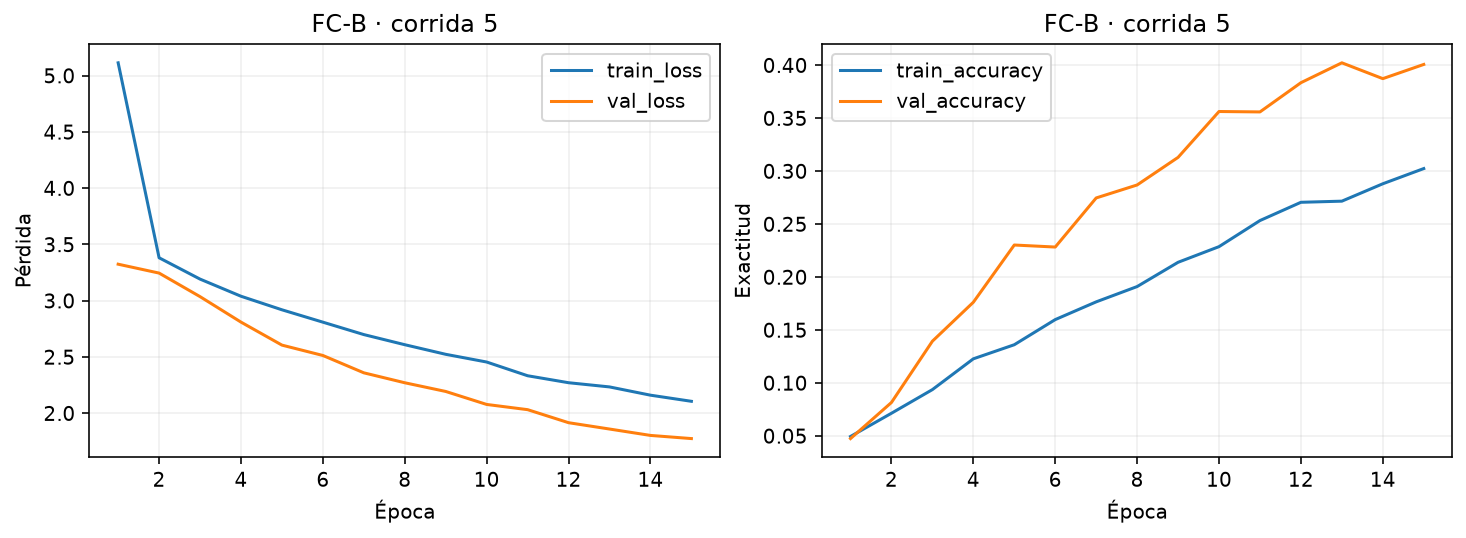

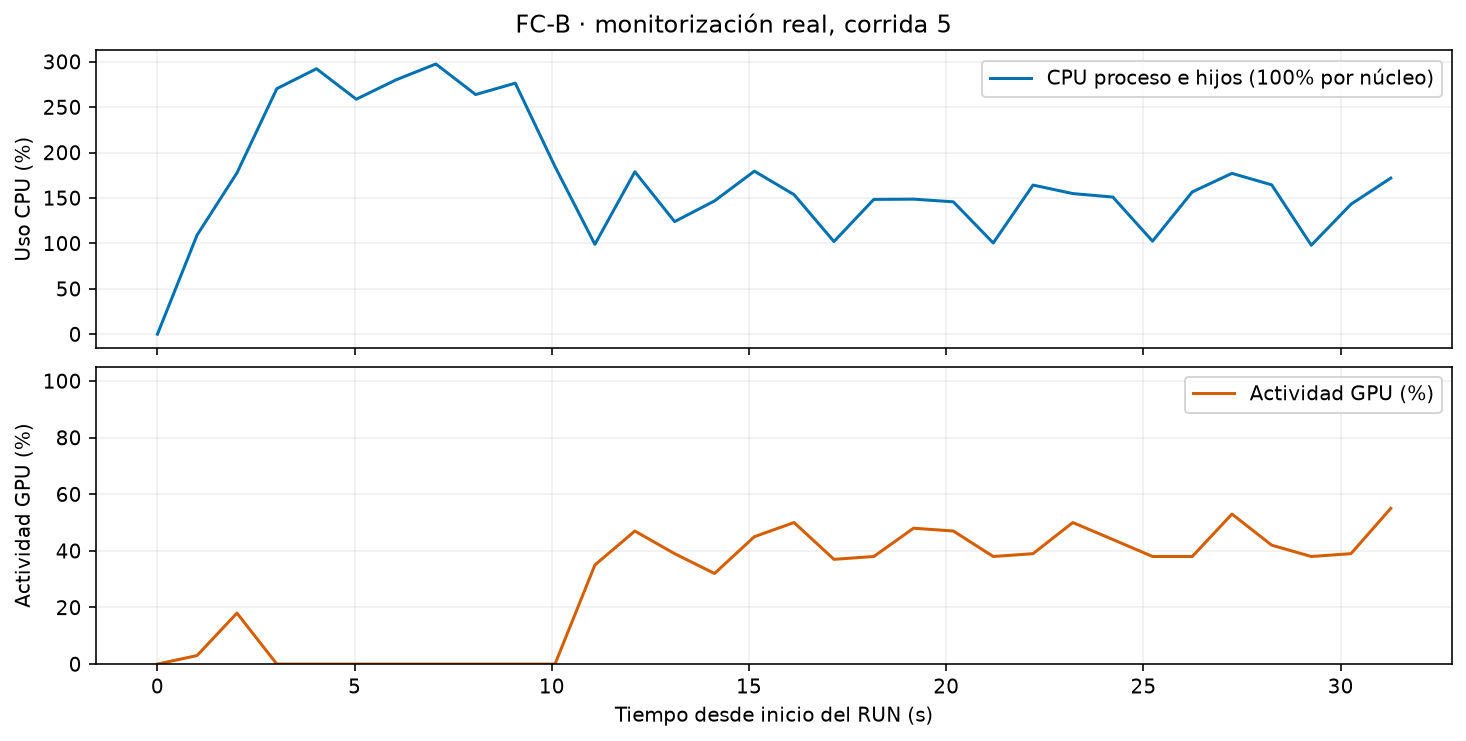

In [44]:
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-012'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna(''))
display(pd.DataFrame(epoch_rows))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-012/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()


## Resumen de las diez corridas nuevas

No se mezclan las observaciones adicionales n=1 de otros notebooks con las campañas de cinco repeticiones.

In [45]:
display(pd.DataFrame([{k:v for k,v in row.items() if k!='test'}|{'test_accuracy':row['test']['accuracy'],'test_loss':row['test']['loss']} for row in all_results]))
limits.__exit__(None,None,None)
print('FIN EXP-012: 150 épocas nuevas FC, cero entrenamientos CPU/CNN-B previos repetidos.')

,run_id,modelo,repeticion,epocas,pasos,entrenamiento_s,evaluacion_cpu_s,comparabilidad,test_accuracy,test_loss
0,RUN-20261118T134323Z-fc-a-01,FC-A,1,15,1440,14.829318,0.387394,"Datos, estado inicial, arquitectura y pasos eq...",0.517241,1.572327
1,RUN-20261118T134514Z-fc-a-02,FC-A,2,15,1440,15.685816,0.390274,"Datos, estado inicial, arquitectura y pasos eq...",0.517241,1.572327
2,RUN-20261118T134514Z-fc-a-03,FC-A,3,15,1440,14.969787,0.396402,"Datos, estado inicial, arquitectura y pasos eq...",0.517241,1.572327
3,RUN-20261118T134514Z-fc-a-04,FC-A,4,15,1440,14.999950,0.390092,"Datos, estado inicial, arquitectura y pasos eq...",0.517241,1.572327
4,RUN-20261118T134514Z-fc-a-05,FC-A,5,15,1440,15.127836,0.397907,"Datos, estado inicial, arquitectura y pasos eq...",0.517241,1.572327
5,RUN-20261118T134514Z-fc-b-01,FC-B,1,15,1440,21.302664,0.517751,"Datos, estado inicial, arquitectura y pasos eq...",0.399617,1.759407
6,RUN-20261118T134514Z-fc-b-02,FC-B,2,15,1440,20.945062,0.531258,"Datos, estado inicial, arquitectura y pasos eq...",0.399617,1.759407
7,RUN-20261118T134514Z-fc-b-03,FC-B,3,15,1440,21.251391,0.525816,"Datos, estado inicial, arquitectura y pasos eq...",0.399617,1.759407
8,RUN-20261118T134514Z-fc-b-04,FC-B,4,15,1440,20.959104,0.511014,"Datos, estado inicial, arquitectura y pasos eq...",0.399617,1.759407
9,RUN-20261118T134514Z-fc-b-05,FC-B,5,15,1440,20.851751,0.530032,"Datos, estado inicial, arquitectura y pasos eq...",0.399617,1.759407


FIN EXP-012: 150 épocas nuevas FC, cero entrenamientos CPU/CNN-B previos repetidos.


## Diagnóstico nativo del kernel FC

Salida real del descriptor stderr del controlador/kernel; no es una celda de entrenamiento adicional.

```text
EXP-011 (primera corrida guardada; incluye fallo de presentación archivado):
[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1795009420.172297   48724 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1795009423.957841   48724 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795009426.905177   48724 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
E0000 00:00:1795009438.185981   48724 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009444.013049   48724 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009449.849126   48724 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
Traceback (most recent call last):
  File "C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\scripts\ejecutar_fc_notebook_v2.py", line 42, in <module>
    if __name__=='__main__':main()
                            ~~~~^^
  File "C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\scripts\ejecutar_fc_notebook_v2.py", line 29, in main
    NotebookClient(nb,km=km,timeout=10800,resources={'metadata':{'path':str(ROOT)}},on_cell_executed=done).execute(cwd=str(ROOT))
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
  File "C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\jupyter_core\utils\__init__.py", line 165, in wrapped
    return loop.run_until_complete(inner)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "C:\Python314\Lib\asyncio\base_events.py", line 719, in run_until_complete
    return future.result()
           ~~~~~~~~~~~~~^^
  File "C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\nbclient\client.py", line 709, in async_execute
    await self.async_execute_cell(
        cell, index, execution_count=self.code_cells_executed + 1
    )
  File "C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\nbclient\client.py", line 1062, in async_execute_cell
    await self._check_raise_for_error(cell, cell_index, exec_reply)
  File "C:\Users\David\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\nbclient\client.py", line 918, in _check_raise_for_error
    raise CellExecutionError.from_cell_and_msg(cell, exec_reply_content)
nbclient.exceptions.CellExecutionError: An error occurred while executing the following cell:
------------------
state('evaluacion_final_cpu',pasos=net.steps)
start=time.perf_counter_ns()
test=reference.evaluate(tx,ty,batch_size=32,verbose=0,return_dict=True)
eval_seconds=(time.perf_counter_ns()-start)/1e9
add('evaluacion_'+name,eval_seconds)
metrics=dict(modelo=name,repeticion=repetition,test={k:float(v) for k,v in test.items()},epocas=15,pasos=1440,
    entrenamiento_s=train_seconds,evaluacion_cpu_s=eval_seconds,
    comparabilidad='Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente')
write_json(run/'metricas.json',metrics);write_csv(run/'tiempos.csv',timings)
write_json(run/'eventos.json',dict(eventos_s=events,validacion_cpu_s=validations,export_cpu_pared_s=export_wall,
    nota='Intervalos stream anidados; no equivalen a tiempo activo exclusivo de kernels; no sumar al tiempo pared'))
write_json(run/'ordenes.json',dict(seed=seed,generador='PCG64',epocas_sha256=shuffle_hashes))
param_count=sum(p['value'].size for p in net.params)
bn_count=sum(op['C']*2 for op in net.ops if op['kind']=='bn')
write_json(run/'transferencias.json',dict(lotes=net.transfers[-1440:],modelo_d2h_copias=16,
    modelo_bytes_por_copia=(param_count+bn_count)*4,optimizador_final_bytes=param_count*8+8,
    control_d2h_bytes=1440*4,reinicios_metricas_h2d_bytes=15*12,
    nota='Copia final adicional de pesos incluida; sin restar costes'))
state('guardado_fuera_timing')
model_dir=ROOT/'data/EXP-011'/run.name;model_dir.mkdir(parents=True,exist_ok=False)
model_path=model_dir/(name+'-CUDA.keras');reference.save(model_path)
fingerprint=hashlib.sha256()
for variable in [*reference.variables,*reference.optimizer.variables]:
    array=variable.numpy();fingerprint.update(str(array.dtype).encode());fingerprint.update(str(array.shape).encode());fingerprint.update(array.tobytes())
write_json(run/'modelo-guardado.json',dict(ruta=model_path.relative_to(ROOT).as_posix(),sha256=sha(model_path),
    estado_canonico_sha256=fingerprint.hexdigest(),optimizer_iterations=1440))
write_json(run/'lanzamientos.json',dict(vector_block=256,bn_parcial_block=[32,8,1],
    bn_parcial_grid=[1,384,1],bn_final_block=256,bn_final_grid=[48,1,1],
    softmax_block=32,softmax_grid=[128,1,1],ultimo_batch=20,recursos=compiled_resources(),
    fc_finish_regs=str(finish_fc.get_regs_per_thread()),
    gemm='cuBLAS SGEMM FP32 PEDANTIC; jerarquía interna de biblioteca, no fijada por el equipo'))
state('completada',pasos=1440)
stop.set();monitor.join(timeout=15)
if repetition==1:
    try:capture.wait(timeout=8)
    except subprocess.TimeoutExpired:capture.terminate();capture.wait();print('Captura no disponible; revisar capturador.log')
    capture_log.close()
display(pd.DataFrame(timings).fillna('').style.hide(axis='index'))
display(pd.DataFrame(epoch_rows).style.hide(axis='index'))
print('MÉTRICAS REALES',json.dumps(metrics,indent=2,ensure_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(range(1,16),[r[key] for r in epoch_rows],label=key)
    ax.set(xlabel='Época',ylabel=title,title=name+' · corrida '+str(repetition));ax.legend();ax.grid(alpha=.2)
fig.savefig(run/'curvas.png',dpi=160);fig.savefig(run/'curvas.svg');mostrar_figura(fig)
resource=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(resource.transcurrido_s,resource.cpu_procesos_pct,color='#0072B2',label='CPU proceso e hijos (100% por núcleo)')
axes[1].plot(resource.transcurrido_s,resource.gpu_util_pct,color='#D55E00',label='Actividad GPU (%)')
axes[0].set(ylabel='Uso CPU (%)');axes[1].set(ylabel='Actividad GPU (%)',xlabel='Tiempo desde inicio del RUN (s)',ylim=(0,105))
for ax in axes:ax.legend(loc='upper right');ax.grid(alpha=.2)
fig.suptitle(name+' · monitorización real, corrida '+str(repetition))
fig.savefig(run/'recursos.png',dpi=160);fig.savefig(run/'recursos.svg');mostrar_figura(fig)
for picture in sorted(run.glob('captura-*.png')):display(Image(filename=str(picture)))
all_results.append(dict(run_id=run.name,**metrics));write_json(ROOT/'resultados/paralelo/EXP-011/progreso.json',all_results)
net.stream.synchronize();net.blas.close()
del net,reference,inputs,x,y,vx,vy,tx,ty,wx,wy,wv,wvy,wt,wty,p,op
tf.keras.backend.clear_session();gc.collect();cuda.current_context().deallocations.clear()

------------------


[31m---------------------------------------------------------------------------[39m
[31mAttributeError[39m                            Traceback (most recent call last)
[36mCell[39m[36m [39m[32mIn[12][39m[32m, line 38[39m
[32m     34[39m [38;5;28;01mif[39;00m repetition==[32m1[39m:
[32m     35[39m     [38;5;28;01mtry[39;00m:capture.wait(timeout=[32m8[39m)
[32m     36[39m     [38;5;28;01mexcept[39;00m subprocess.TimeoutExpired:capture.terminate();capture.wait();print([33m'Captura no disponible; revisar capturador.log'[39m)
[32m     37[39m     capture_log.close()
[32m---> [39m[32m38[39m display(pd.DataFrame(timings).fillna([33m''[39m).style.hide(axis=[33m'index'[39m))
[32m     39[39m display(pd.DataFrame(epoch_rows).style.hide(axis=[33m'index'[39m))
[32m     40[39m print([33m'MÉTRICAS REALES'[39m,json.dumps(metrics,indent=[32m2[39m,ensure_ascii=[38;5;28;01mFalse[39;00m))
[32m     41[39m fig,axes=plt.subplots([32m1[39m,[32m2[39m,figsize=([32m10[39m,[32m3.6[39m),layout=[33m'constrained'[39m)

[36mFile [39m[32m~\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\pandas\core\generic.py:6434[39m, in [36mNDFrame.__getattr__[39m[34m(self, name)[39m
[32m   6430[39m             [38;5;28;01mand[39;00m name [38;5;28;01mnot[39;00m [38;5;28;01min[39;00m self._accessors
[32m   6431[39m             [38;5;28;01mand[39;00m self._info_axis._can_hold_identifiers_and_holds_name(name)
[32m   6432[39m         ):
[32m   6433[39m             [38;5;28;01mreturn[39;00m self[name]
[32m-> [39m[32m6434[39m         [38;5;28;01mreturn[39;00m object.__getattribute__(self, name)

[36mFile [39m[32m~\Documents\2026\S2\PARALELA\CUDA\PROYECTO-CUDA\proyectoCUDA-paralela\PCUDA\Lib\site-packages\pandas\core\frame.py:1258[39m, in [36mDataFrame.style[39m[34m(self)[39m
[32m   1254[39m         """
[32m   1255[39m         [38;5;66;03m# Raise AttributeError so that inspect works even if jinja2 is not installed.[39;00m
[32m   1256[39m         has_jinja2 = import_optional_dependency([33m"jinja2"[39m, errors=[33m"ignore"[39m)
[32m   1257[39m         [38;5;28;01mif[39;00m [38;5;28;01mnot[39;00m has_jinja2:
[32m-> [39m[32m1258[39m             [38;5;28;01mraise[39;00m AttributeError([33m"The '.style' accessor requires jinja2"[39m)
[32m   1259[39m 
[32m   1260[39m         [38;5;28;01mfrom[39;00m pandas.io.formats.style [38;5;28;01mimport[39;00m Styler
[32m   1261[39m 

[31mAttributeError[39m: The '.style' accessor requires jinja2



EXP-012 (nueve pendientes):
[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1795009531.304889   64528 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1795009534.869333   64528 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795009537.458909   64528 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
E0000 00:00:1795009548.974153   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009554.929487   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009560.278135   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009578.774448   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009584.675835   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009590.649973   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009605.839318   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009611.785989   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009617.694874   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009633.087488   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009639.040618   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009644.053844   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009662.921235   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009668.876551   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009674.392172   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009679.844963   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009697.207913   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009702.661597   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009708.115293   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009713.750053   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009731.225323   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009736.735097   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009742.452373   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009748.087850   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009765.778945   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009771.241534   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009776.829505   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009782.289859   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009800.623879   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009806.275732   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009811.679261   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795009817.081203   64528 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}

```

# Comparación ampliada: resultados CPU conservados y CUDA nueva

Sesión separada de presentación: solo lectura de mediciones y gráficas reales. Los contadores reinician en cada sesión; no se reejecuta ningún entrenamiento.

In [1]:
from pathlib import Path
import pandas as pd,json
from IPython.display import display,Image
ROOT=Path.cwd()
OUT=ROOT/'resultados/comparacion/ampliacion-fc'
comparison=pd.read_csv(OUT/'comparacion.csv')
display(comparison)
print('Speedup = media CPU / media CUDA; n=5 por modelo y dispositivo. Evaluación final sigue en CPU.')

,modelo,fase,cpu_media_s,cpu_de_s,cuda_media_s,cuda_de_s,speedup,reduccion_pct
0,CNN-B,entrenamiento_CNN-B,805.649726,2.722684,418.607683,1.916308,1.924594,48.040982
1,CNN-B,evaluacion_CNN-B,2.322390,0.071787,2.492192,0.381288,0.931866,-7.311550
2,FC-A,entrenamiento_FC-A,50.715660,1.264624,15.122541,0.332283,3.353647,70.181712
3,FC-A,evaluacion_FC-A,0.378842,0.005733,0.392414,0.004507,0.965414,-3.582510
4,FC-B,entrenamiento_FC-B,102.441082,3.275205,21.061995,0.201404,4.863788,79.439895
5,FC-B,evaluacion_FC-B,0.520067,0.011493,0.523174,0.008612,0.994060,-0.597535


Speedup = media CPU / media CUDA; n=5 por modelo y dispositivo. Evaluación final sigue en CPU.


In [2]:
display(pd.read_csv(OUT/'calidad.csv'))
display(pd.read_csv(OUT/'desglose.csv'))
display(pd.read_csv(OUT/'recursos-resumen.csv'))

,modelo,origen,n,accuracy_media_pct,accuracy_min_pct,accuracy_max_pct,loss_media
0,FC-A,CPU,5,53.065133,53.065133,53.065133,1.523044
1,FC-A,CUDA,5,51.724136,51.724136,51.724136,1.572327
2,FC-B,CPU,5,44.291186,44.291186,44.291186,1.738064
3,FC-B,CUDA,5,39.961687,39.961687,39.961687,1.759407


,modelo,pared_s,validacion_cpu_s,h2d_eventos_s,d2h_eventos_s,matematica_intervalos_stream_s,resto_host_s
0,FC-A,15.122541,3.481379,1.733154,0.185665,5.548887,4.173457
1,FC-B,21.061995,5.008333,1.863861,0.222636,9.356508,4.610657


,modelo,repeticion,muestras_training,gpu_media_pct,gpu_max_pct,vram_max_mib,cpu_media_pct
0,FC-A,1,15,31.466667,50.0,111.0,121.719527
1,FC-A,2,15,30.933333,33.0,111.0,120.477216
2,FC-A,3,15,30.266667,33.0,111.0,123.102817
3,FC-A,4,15,32.133333,33.0,111.0,122.821218
4,FC-A,5,15,31.733333,34.0,111.0,123.836661
5,FC-B,1,17,37.941176,56.0,187.0,147.502830
6,FC-B,2,16,40.812500,55.0,187.0,157.620959
7,FC-B,3,16,38.625000,52.0,187.0,146.223711
8,FC-B,4,15,43.266667,55.0,187.0,142.616530
9,FC-B,5,15,43.133333,53.0,187.0,154.109161


01_fc_tiempos


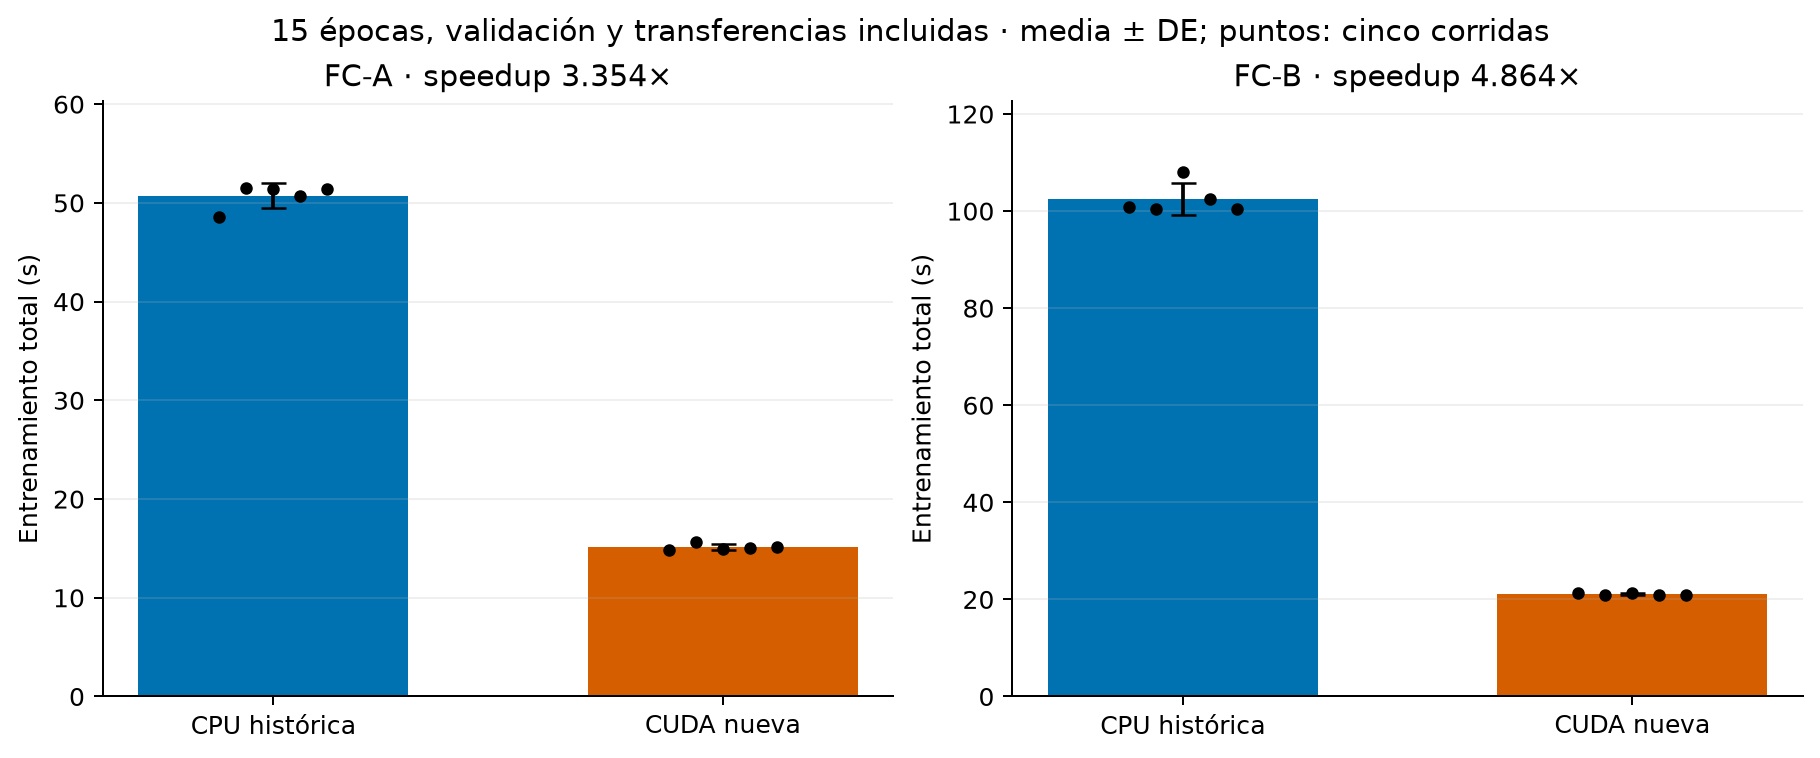

02_tres_redes_speedup


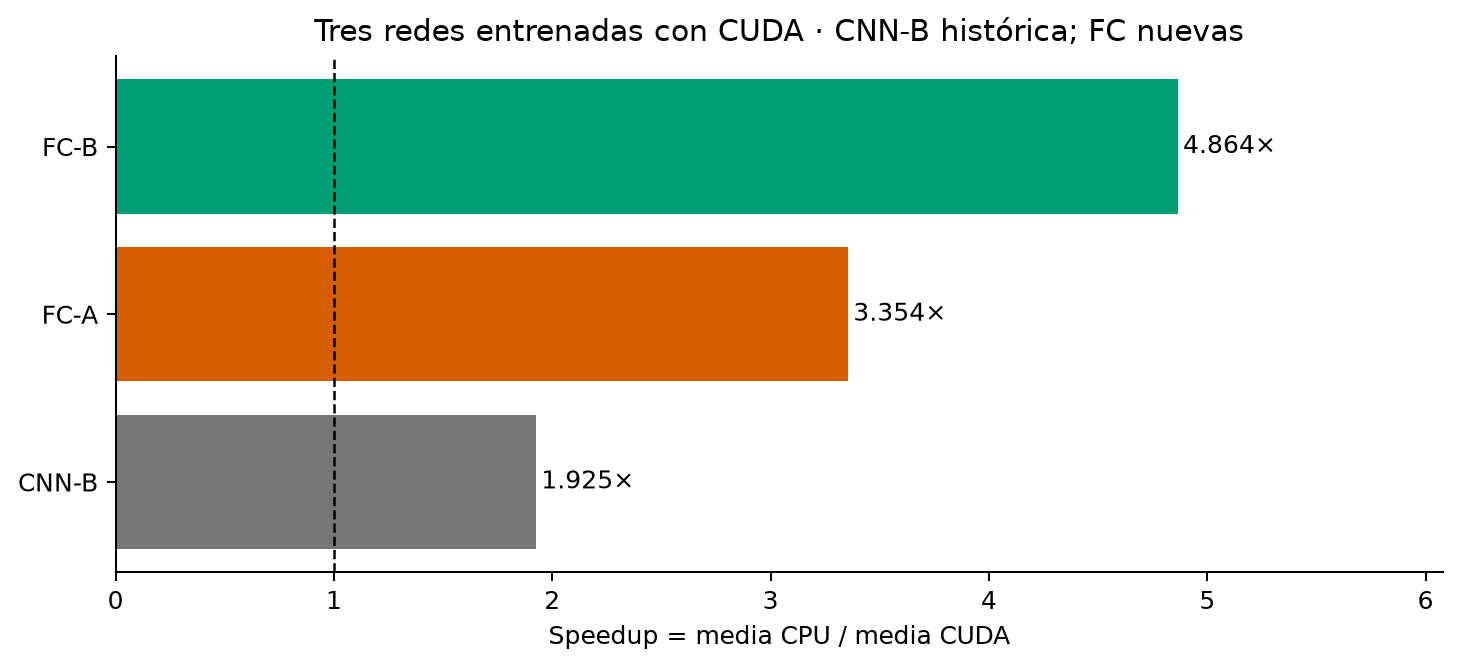

03_fc_desglose


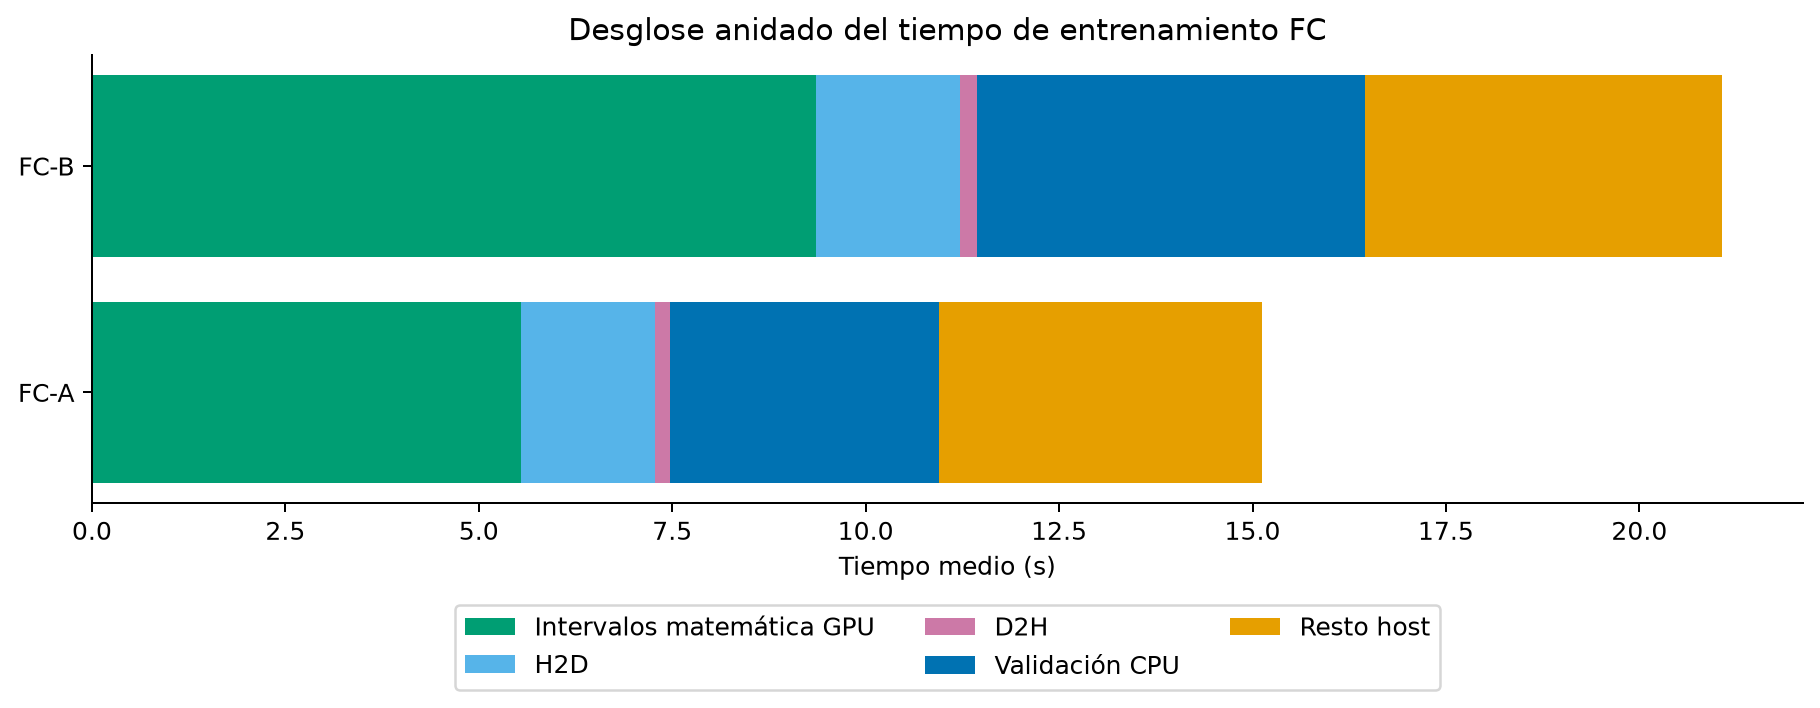

04_fc_calidad


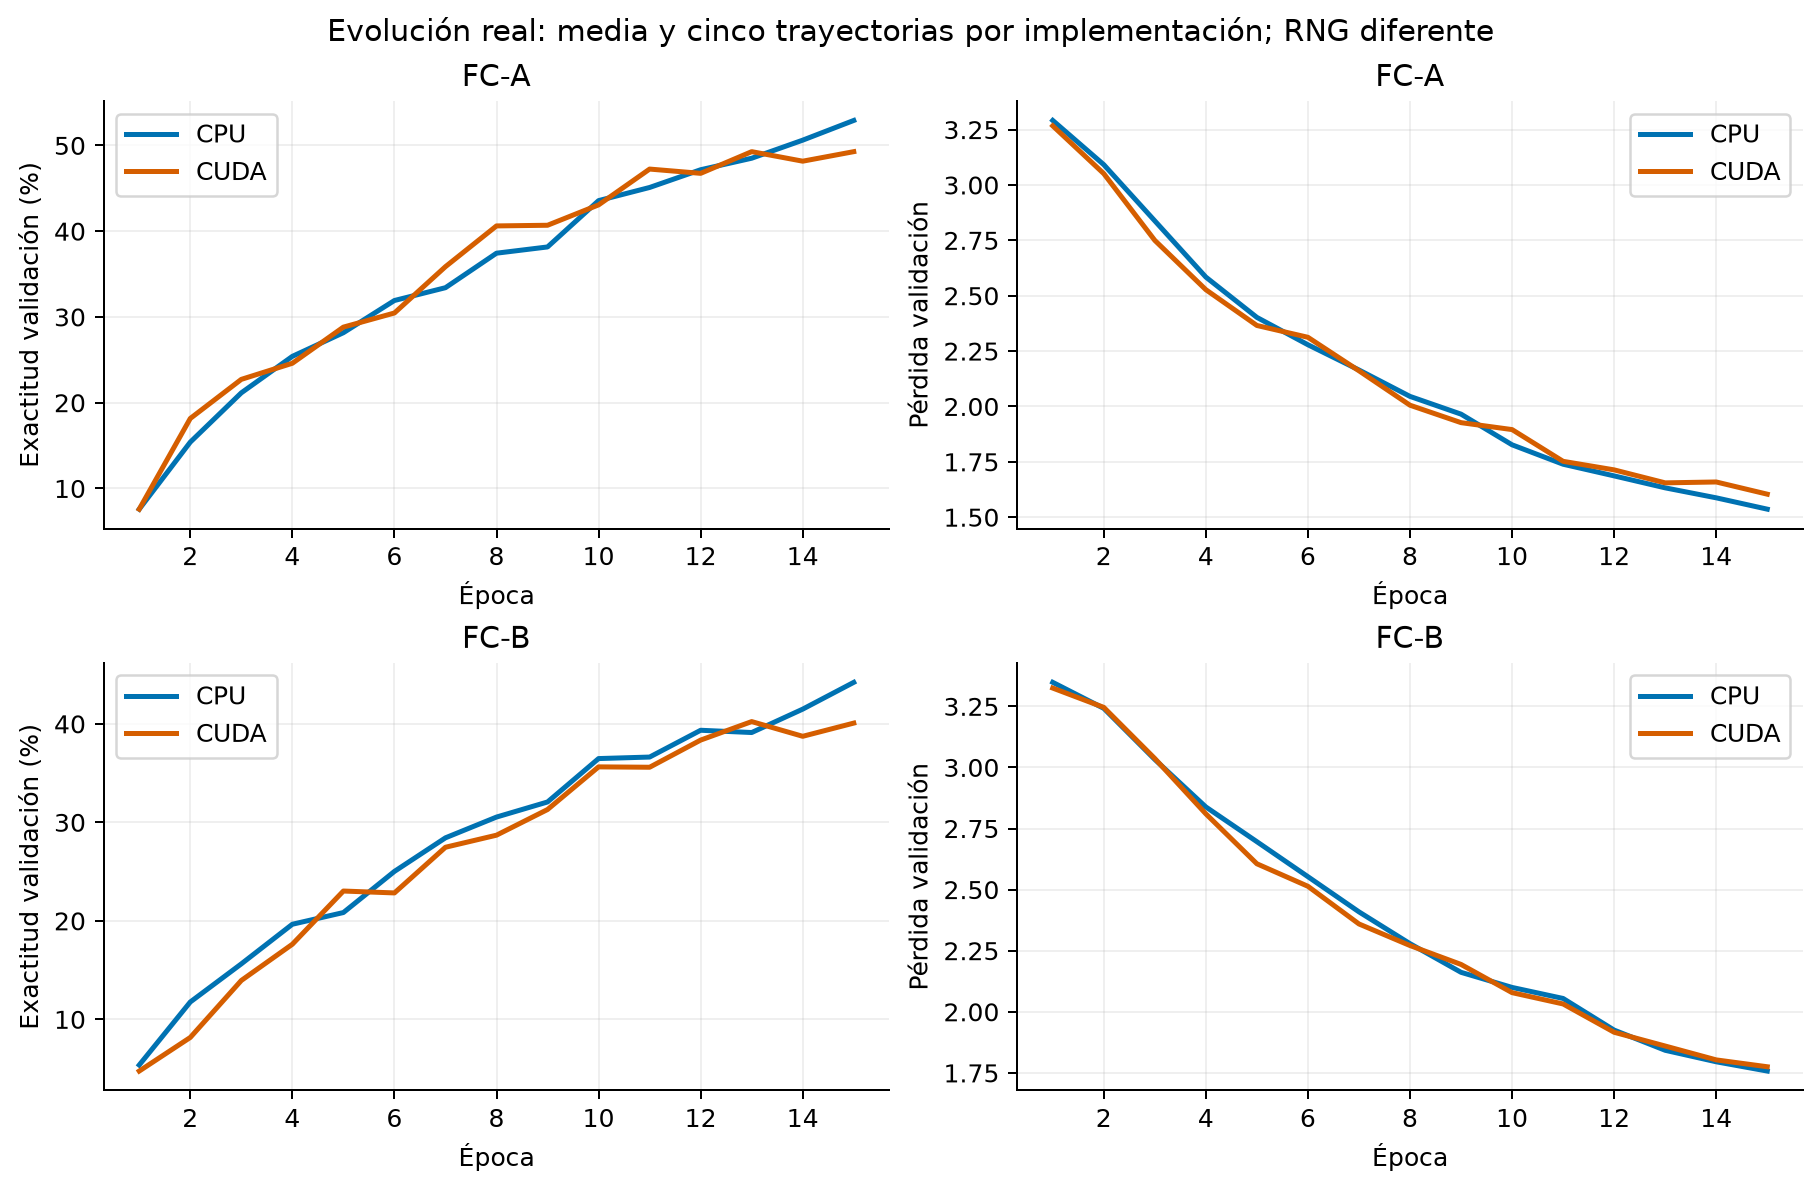

Datos idénticos por SHA-256; CPU histórica con distinto RNG interno. GPU util no equivale a ocupación por SM. Sin saturación artificial de VRAM.


In [3]:
for name in ['01_fc_tiempos','02_tres_redes_speedup','03_fc_desglose','04_fc_calidad']:
    print(name)
    display(Image(filename=str(OUT/(name+'.png'))))
print('Datos idénticos por SHA-256; CPU histórica con distinto RNG interno. GPU util no equivale a ocupación por SM. Sin saturación artificial de VRAM.')